# The Heat Equation with Physics-Informed Neural Networks
### Two case studies: buried soil sensors and the heat shield of a returning spacecraft. NumPy from scratch (Part A) and PyTorch (Part B)

**Author:** Dishanand Jayeprokash

Heat moving through a material follows one of the best-known equations in physics, the **heat equation**. In this notebook the same equation, and the same neural-network method, solve two very different real problems.

**Case study 1: soil.** Push a thermometer a few centimetres into the ground and log it for a few days. The reading swings up and down once a day, following the sun. A second sensor, deeper, swings less and later. A third, deeper still, hardly notices the day at all. The soil acts as a filter that weakens and delays the daily temperature wave, and *how much* it does so depends on one number, the **thermal diffusivity**. A few cheap sensors are enough to find it.

**Case study 2: a spacecraft heat shield.** A spacecraft returning from orbit is wrapped in a glowing plasma for many minutes. Its outer surface reaches about 1200 °C, while the aluminium structure a few centimetres below must stay under about 175 °C. In between sits an insulating ceramic tile, and the whole safety of the vehicle comes down to one question: **how hot does the back of the tile get, and when?** Nobody can easily put a sensor right at the back. A few thermocouples buried part of the way in, together with the heat equation, can tell us.

The two cases are one problem in different clothes: *use a few temperature readings and the physics of heat flow to find an unknown material property and to predict temperatures where nobody measured.*

**What you will find here**

| Section | What it covers |
|---|---|
| **Background** | Where the heat equation comes from (fully derived), the exact solution for a daily cycle in soil, the classical sensor methods, thermal inertia, the exact solution for a tile of finite thickness (by separation of variables), why the back of a heat shield peaks *after* the heating stops, and how the loss is built for a PDE |
| **Setup** | Constants, exact solutions, a classical finite-difference solver, interactive explorers for both cases (including "is this tile thick enough?"), synthetic sensor readings, and the classical estimators |
| **Part A** | NumPy only: a network that returns its own time and depth derivatives, hand-derived gradients, a gradient check, Adam. Soil: sensors-only vs physics-informed training, the diffusivity estimate, a heat-budget check, a training video and a cloudy-afternoon test. **Spacecraft: finding the tile's diffusivity from thermocouples, predicting the back-face temperature, and a re-entry video** |
| **Part B** | PyTorch with automatic differentiation, then L-BFGS, `torch.func`, a study of how many sensors you need, and the heat-shield tile again |

This is the first project in the PDE (partial differential equation) series. Compared with the ODE projects there are three new things:

* **The unknown depends on two variables**, depth and time, so the network has two inputs.
* **There are many more places to check the equation**: a whole depth–time map, not just a line.
* **The equation has a second derivative in space and a first derivative in time**, so we need the network's derivatives in two different directions.

**Requirements:** Python 3.9+, `numpy`, `scipy`, `matplotlib`, `pillow`. Optional: `ipywidgets` (sliders), `ffmpeg` (MP4 files), `torch` (Part B).

---
# Background

## 1. Where this equation shows up

The heat equation describes how temperature spreads by conduction (heat moving through a material without the material itself moving). The same equation, with different names for the symbols, covers:

* **Soil and rock temperature.** Daily and yearly temperature waves in the ground, frost depth, permafrost.
* **Ground-source heat pumps and buried cables and pipes.** How deep is "deep enough" to escape the daily swing.
* **Building walls and roofs.** Why a thick stone wall stays cool through a hot afternoon.
* **Thermal protection of spacecraft.** An insulating tile on a re-entry vehicle is heated on one side for minutes while the other side must stay cool.
* **Remote sensing.** A satellite sees only the temperature of the surface. How much that surface heats up by day and cools by night depends on how easily heat flows into the ground below, a property called *thermal inertia*. Day–night temperature differences are used to map it (Price, 1977).

## 2. Deriving the heat equation

Think of a vertical column of soil with $z$ measured **downwards** from the surface, and $T(z,t)$ the temperature at depth $z$ and time $t$. We assume the soil is the same in every horizontal direction (so only depth matters), that heat moves only by conduction, and that there are no heat sources inside it (no chemical reactions, no moving water).

**Energy balance on a thin slice.** Take a slice between depths $z$ and $z+\Delta z$ with unit area. Let $q(z,t)$ be the heat flow downwards (power per area, W/m²). Over a short time $\Delta t$:

> (heat stored in the slice) = (heat flowing in at the top) − (heat flowing out at the bottom)

The heat stored depends on how much the temperature rises. If the soil has density $\rho$ and specific heat $c$, then $\rho c$ is the heat needed to raise one cubic metre by one degree, so
$$
\rho c\,\Delta z\,\frac{\partial T}{\partial t}\,\Delta t=\big[q(z,t)-q(z+\Delta z,t)\big]\Delta t .
$$
Divide by $\Delta z\,\Delta t$ and let both shrink to zero. The difference quotient of $q$ becomes a derivative:
$$
\rho c\,\frac{\partial T}{\partial t}=-\frac{\partial q}{\partial z}.
\tag{1}
$$

**Fourier's law.** Heat flows from warm to cold, in proportion to how steeply the temperature changes:
$$
q=-k\,\frac{\partial T}{\partial z},
\tag{2}
$$
where $k$ (W/m/K) is the thermal conductivity. The minus sign says heat flows towards lower temperature.

**Putting (1) and (2) together** with constant $k$:
$$
\rho c\,\frac{\partial T}{\partial t}=k\,\frac{\partial^{2}T}{\partial z^{2}}
\quad\Longrightarrow\quad
\boxed{\,\frac{\partial T}{\partial t}=\alpha\,\frac{\partial^{2}T}{\partial z^{2}},\qquad \alpha=\frac{k}{\rho c}\,}
\tag{3}
$$
The number $\alpha$ is the **thermal diffusivity**. Its unit is m²/s (we will use m²/day, which suits a daily cycle). Typical soils have $\alpha$ somewhere around a few times $10^{-7}$ m²/s: it is higher for wet or compact soil and lower for dry, loose soil. Our test soil has $\alpha=5\times10^{-7}$ m²/s, which is $0.0432$ m²/day.

**What kind of equation is this?** It is first-order in time and second-order in space. So, in the spirit of the ODE projects, it needs conditions to pick one solution: an **initial condition** (the temperature profile at the start) and **two boundary conditions** (what happens at the top and at the bottom of the domain).

**Diffusion forgets.** Equation (3) smooths things out. Sharp temperature differences fade, and details of the starting profile are slowly lost. A rough distance that heat travels in time $t$ is the diffusion length $\sqrt{\alpha t}$. For our soil, after one day this is about $\sqrt{0.0432}\approx0.21$ m. This is why the deep soil barely notices the weather on the surface.

## 3. The exact solution for a daily temperature cycle

Suppose the surface temperature follows a clean daily cycle with mean $T_{\text{mean}}$, swing $A$ and angular frequency $\omega=2\pi/(1\text{ day})$:
$$
T(0,t)=T_{\text{mean}}+A\cos\omega t .
$$
Because (3) is linear, we can subtract the mean. Define the temperature **anomaly** $\theta=(T-T_{\text{mean}})$, which obeys the same equation with $\theta(0,t)=A\cos\omega t$ and $\theta\to0$ deep down.

**Step 1: a complex trick.** Write the cosine as the real part of a complex exponential, $A\cos\omega t=\operatorname{Re}\big[A e^{i\omega t}\big]$, and look for a solution of the form
$$
\theta(z,t)=\operatorname{Re}\big[F(z)\,e^{i\omega t}\big].
$$
Since $\partial_t$ acts on $e^{i\omega t}$ to give $i\omega$, equation (3) becomes an ODE for $F$:
$$
i\omega\,F=\alpha\,F''
\quad\Longrightarrow\quad
F''=\frac{i\omega}{\alpha}\,F .
$$

**Step 2: solve it like the oscillator.** Try $F=e^{-kz}$. Then $k^2=i\omega/\alpha$. Using $\sqrt i=(1+i)/\sqrt2$,
$$
k=\sqrt{\frac{i\omega}{\alpha}}=(1+i)\sqrt{\frac{\omega}{2\alpha}}=\frac{1+i}{d},
\qquad
\boxed{\,d=\sqrt{\frac{2\alpha}{\omega}}\,}
$$
The number $d$ is the **damping depth**. (There is also a root $e^{+kz}$, but it grows without limit with depth, so we discard it.) With the surface condition $F(0)=A$:
$$
F(z)=A\,e^{-(1+i)z/d}=A\,e^{-z/d}\,e^{-iz/d}.
$$

**Step 3: take the real part.**
$$
\boxed{\,\theta(z,t)=A\,e^{-z/d}\cos\!\Big(\omega t-\frac zd\Big)\,}
\tag{4}
$$

**Check by substitution.** Let $\varphi=\omega t-z/d$, so $\theta=Ae^{-z/d}\cos\varphi$, with $\partial\varphi/\partial t=\omega$ and $\partial\varphi/\partial z=-1/d$. Then
$$
\theta_t=-A\omega\,e^{-z/d}\sin\varphi,\qquad
\theta_z=\frac Ad\,e^{-z/d}\big(\sin\varphi-\cos\varphi\big),
$$
$$
\theta_{zz}=\frac Ad\,e^{-z/d}\Big[-\frac1d(\sin\varphi-\cos\varphi)-\frac1d(\cos\varphi+\sin\varphi)\Big]=-\frac{2A}{d^{2}}\,e^{-z/d}\sin\varphi .
$$
Since $2\alpha/d^{2}=\omega$, we get $\alpha\theta_{zz}=-A\omega e^{-z/d}\sin\varphi=\theta_t$, so (3) holds.

**What formula (4) says.**

| Feature | Formula | For our soil ($d=11.7$ cm) |
|---|---|---|
| Amplitude at depth $z$ | $A\,e^{-z/d}$ | 65% at 5 cm, 18% at 20 cm, 8% at 30 cm |
| Time delay at depth $z$ | $\dfrac{z}{d\,\omega}$ | 1.6 hours at 5 cm, 9.8 hours at 30 cm |
| Speed of the wave | $\omega d=\sqrt{2\alpha\omega}$ | about 3 cm per hour |
| Wavelength | $2\pi d$ | about 74 cm |
| Depth where the swing is reversed | $\pi d$ | about 37 cm (the soil is coolest when the surface is warmest, and the swing is only 4% of the surface swing) |

**A link to the damped oscillator.** The oscillator solution was $e^{-\alpha t}\cos(\omega_d t)$: a cosine inside a decaying exponential, coming from a pair of complex roots of a characteristic equation. Formula (4) has the same shape, $e^{-z/d}\cos(\omega t-z/d)$, and it also comes from a complex root, $k=(1+i)/d$. The difference is that the decay and the wiggle now happen in **depth** instead of time, and the oscillation is forced at the surface. Nature builds a damped wave out of an equation that has no wave in it. Heat does not "propagate" like a sound wave. This wave is a pattern in the way diffusion reacts to a repeating input.

## 4. Reading the sensors: the classical methods

Suppose sensors at depths $z_1,z_2,\dots$ record the temperature. Fit a single daily cosine to each record, $\theta_i(t)\approx a_i\cos\omega t+b_i\sin\omega t$. Its **amplitude** is $A_i=\sqrt{a_i^2+b_i^2}$ and its **phase lag** is $\varphi_i=\operatorname{atan2}(b_i,a_i)$, so $\theta_i\approx A_i\cos(\omega t-\varphi_i)$. Compare with (4):
$$
\ln A_i=\ln A-\frac{z_i}{d},\qquad \varphi_i=\frac{z_i}{d}.
$$
Both are straight lines in depth. The slope of the first is $-1/d$, and the slope of the second is $+1/d$. Once we have $d$, the diffusivity follows from $d=\sqrt{2\alpha/\omega}$:
$$
\boxed{\,\alpha=\frac{\omega\,d^{2}}{2}\,}
$$
For **two** sensors at depths $z_1$ and $z_2$ this gives the two classical estimates:
$$
\alpha_{\text{amp}}=\frac{\omega\,(z_2-z_1)^2}{2\,\big[\ln(A_1/A_2)\big]^2},\qquad
\alpha_{\text{phase}}=\frac{\omega\,(z_2-z_1)^2}{2\,(\varphi_2-\varphi_1)^2}.
$$
These are the amplitude method and the phase method of soil physics (Horton et al., 1983). They are simple and need no computer. Their weak points:

* They throw away most of the record. Everything is squeezed into one amplitude and one phase per sensor.
* Deep sensors have small amplitudes, so noise matters most exactly where $\ln A$ is most sensitive.
* They need the surface temperature to be a clean cosine, and the record to be a whole number of days.
* In real soil, the two answers often disagree because water moves or the soil changes with depth. The disagreement itself is a useful warning sign.

## 5. What the daily swing says about thermal inertia

How much heat enters the ground? Use Fourier's law (2) with formula (4). At the surface $\varphi=\omega t$, so $\theta_z(0,t)=\frac Ad(\sin\omega t-\cos\omega t)$ and the heat flow into the ground is
$$
q(0,t)=-k\,\theta_z(0,t)=\frac{kA}{d}(\cos\omega t-\sin\omega t)=\frac{\sqrt2\,kA}{d}\cos\!\Big(\omega t+\frac\pi4\Big).
$$
Two things follow.

* **The heat flow into the ground peaks 45° ahead of the surface temperature**, which for a daily cycle is 3 hours earlier. The ground starts storing heat before the surface reaches its warmest.
* **The amplitude of the heat flow is $\sqrt2kA/d$.** Since $\sqrt2/d=\sqrt{\omega/\alpha}$ and $k/\sqrt\alpha=\sqrt{k\rho c}$,
$$
q_{\text{amp}}=A\,\sqrt{\omega}\,\sqrt{k\rho c}
\quad\Longrightarrow\quad
I\equiv\sqrt{k\rho c}=\frac{q_{\text{amp}}}{A\sqrt\omega}.
$$
The quantity $I$ is the **thermal inertia**. For the same daily heat input $q_{\text{amp}}$ (set by the sun), the surface swing is $A=q_{\text{amp}}/(I\sqrt\omega)$. So a high-inertia surface (wet soil, rock) swings less than a low-inertia one (dry sand), and that difference is what a satellite sees from orbit. Note that it is $k\rho c$ that matters here, not $\alpha=k/(\rho c)$. The buried sensors in this notebook give $\alpha$. To get $I$ as well, you also need $\rho c$ (for example from the soil's water content).

## 6. A different situation: sudden heating of a heat-shield tile

The daily cycle is one case. Another is a surface whose temperature jumps and then stays put, as at the hot face of a heat-shield tile. Take a slab that starts at $\theta=0$, with $\theta=1$ held at the surface from $t=0$ onwards, and a slab thick enough that the far side is never reached.

**A similarity variable** (the same trick as in the Blasius notebook). There is no length in this problem except the one that diffusion creates, $\sqrt{\alpha t}$, so look for a solution that depends only on
$$
\eta=\frac{z}{2\sqrt{\alpha t}},\qquad \theta(z,t)=f(\eta).
$$
The chain rule gives $\eta_t=-\eta/(2t)$ and $\eta_z=1/(2\sqrt{\alpha t})$, so
$$
\theta_t=-\frac{\eta}{2t}f',\qquad
\theta_z=\frac{f'}{2\sqrt{\alpha t}},\qquad
\theta_{zz}=\frac{f''}{4\alpha t}.
$$
Putting these into $\theta_t=\alpha\theta_{zz}$ makes every $t$ cancel and leaves an ODE:
$$
-\frac{\eta}{2t}f'=\frac{f''}{4t}
\quad\Longrightarrow\quad
f''=-2\eta f' .
$$
This is first-order in $f'$: $f'=Ce^{-\eta^{2}}$. The conditions are $f(0)=1$ (hot surface) and $f(\infty)=0$ (nothing has arrived far away). Integrating from $\eta$ to $\infty$ gives $f(\eta)=-C\int_\eta^\infty e^{-s^2}ds$, and $f(0)=1$ fixes $C=-2/\sqrt\pi$. The result is
$$
\boxed{\,\theta(z,t)=\operatorname{erfc}\!\Big(\frac{z}{2\sqrt{\alpha t}}\Big)\,}
\tag{5}
$$
where $\operatorname{erfc}(\eta)=\frac2{\sqrt\pi}\int_\eta^\infty e^{-s^2}ds$ is the complementary error function. Two useful facts:

* The heated layer is about $z\approx3.6\sqrt{\alpha t}$ deep (that is where $\operatorname{erfc}$ falls to 1%). It grows like $\sqrt t$.
* The heat flow into the solid at the surface is $q=-k\theta_z(0,t)=\dfrac{k\,\Delta T}{\sqrt{\pi\alpha t}}$, because $f'(0)=-2/\sqrt\pi$. It is huge at first and falls off like $1/\sqrt t$.

For an illustrative insulating tile with $\alpha=5\times10^{-7}$ m²/s, ten minutes of heating warms only the outer $3.6\sqrt{5\times10^{-7}\cdot600}\approx6$ cm. We plot this in the Setup section. The same sensor idea works here too: thermocouples buried in a tile tell you $\alpha$.

## 7. A heat-budget check that needs no exact answer

Integrate the heat equation over the depth of the domain, $0\le z\le L$:
$$
\frac{d}{dt}\int_0^L\theta\,dz=\int_0^L\alpha\,\theta_{zz}\,dz=\alpha\,\big[\theta_z(L,t)-\theta_z(0,t)\big].
\tag{6}
$$
The left side is the rate at which the soil column stores heat. The right side is the heat flowing in at the top minus the heat flowing out at the bottom (times $\rho c$). This balance holds for **any** correct solution. So we can test a model's temperature field against (6) without knowing the true answer, in the same spirit as the energy check of the oscillator notebook and the momentum check of the Blasius notebook.

## 8. A classical solver for comparison: Crank–Nicolson

To know the right answer when the surface temperature is *not* a clean cosine, we need a classical numerical solver. We use the **Crank–Nicolson** scheme (Crank and Nicolson, 1947). Put the soil on a grid of depths $z_j=j\,\Delta z$ and step in time by $\Delta t$. Write $L\theta_j=(\theta_{j+1}-2\theta_j+\theta_{j-1})/\Delta z^2$ for the three-point second difference. Evaluate the right side of the heat equation as the **average** of the old and new time levels:
$$
\frac{\theta_j^{n+1}-\theta_j^{n}}{\Delta t}=\frac\alpha2\Big[L\theta_j^{n+1}+L\theta_j^{n}\Big].
$$
This is stable for any step size and accurate to second order in both $\Delta z$ and $\Delta t$. At each step it gives a tridiagonal system of equations for the new temperatures, which a standard solver handles quickly. We check it against formula (4) in the Setup section.

## 9. The PINN for the heat equation

The network $\hat\theta_\Theta(z,t)$ takes depth and time and returns the temperature anomaly. (We write $\Theta$ for the network's weights, to keep $\theta$ for temperature.) We can differentiate it in either direction, which gives $\hat\theta_t$, $\hat\theta_z$ and $\hat\theta_{zz}$. We work with the anomaly in units of the surface swing $A$, so the numbers are of order one. The loss has four parts:

**Sensor loss.** The mean squared difference between the network and the $N_d$ readings:
$$
\mathcal L_{\text{data}}=\frac1{N_d}\sum_i\big(\hat\theta(z_i,t_i)-\theta_i\big)^2 .
$$

**Equation loss.** At $N_c$ points $(z_j,t_j)$ spread over the whole depth–time rectangle (not only at sensors), form the residual of (3), scaled by $\omega$ so it is of order one:
$$
r_j=\frac{\hat\theta_t-\alpha\,\hat\theta_{zz}}{\omega}\Big|_{(z_j,t_j)},\qquad
\mathcal L_{\text{PDE}}=\frac1{N_c}\sum_j r_j^2 .
$$

**Surface and deep-boundary losses.** At the top, the network must match the recorded surface temperature $\theta_s(t)$. At the bottom of the model ($z=L$) the temperature is the steady deep value:
$$
\mathcal L_{\text{BC}}=\frac1{N_b}\sum_k\Big[\hat\theta(0,t_k)-\theta_s(t_k)\Big]^2+\frac1{N_b}\sum_k\hat\theta(L,t_k)^2 .
$$
(Taking the deep temperature as constant at $L=0.6$ m is an approximation: the real daily swing at that depth is a few hundredths of a degree.)

**There is no initial-condition term.** We do not know the temperature profile at the start. The sensors, the surface record and the equation together settle it, because the effect of the starting profile fades, as explained in section 2.

**Total loss:** $\mathcal L=\lambda_{\text{data}}\mathcal L_{\text{data}}+\lambda_{\text{PDE}}\mathcal L_{\text{PDE}}+\lambda_{\text{BC}}\mathcal L_{\text{BC}}$. Setting $\lambda_{\text{PDE}}=\lambda_{\text{BC}}=0$ gives the "sensors only" network we compare against.

**The unknown diffusivity.** In the inverse problem $\alpha$ is not known, so it becomes one more trainable number. A diffusivity must be positive, so we train its logarithm $s$ and use $\alpha=e^{s}$. The gradient follows from the chain rule. The residual depends on $\alpha$ through $-\alpha\hat\theta_{zz}/\omega$, so
$$
\frac{\partial\mathcal L_{\text{PDE}}}{\partial\alpha}=\frac1{N_c}\sum_j2\,r_j\Big(-\frac{\hat\theta_{zz}}{\omega}\Big),\qquad
\frac{\partial\mathcal L}{\partial s}=\lambda_{\text{PDE}}\,\alpha\,\frac{\partial\mathcal L_{\text{PDE}}}{\partial\alpha}.
$$

**What the sensors must supply.** With the surface temperature known, even one interior sensor carries the information (its amplitude and delay relative to the surface). More sensors add accuracy and a way to see whether the soil really behaves like uniform soil.

## 10. Differentiating the network in two directions

The network has two inputs, depth and time. We carry four quantities through every layer: the value, the depth-derivative $\partial_z$, the second depth-derivative $\partial_z^2$, and the time-derivative $\partial_t$. (No mixed derivative appears in equation (3), so we do not need one.) Write them with subscripts, $\mathbf P,\mathbf P_z,\mathbf P_{zz},\mathbf P_t$ for what enters a layer.

* **Linear step.** $\mathbf Z=\mathbf P\mathbf W+\mathbf b$, and the derivatives pass straight through: $\mathbf Z_z=\mathbf P_z\mathbf W$, $\mathbf Z_{zz}=\mathbf P_{zz}\mathbf W$, $\mathbf Z_t=\mathbf P_t\mathbf W$.
* **Activation step.** With $\mathbf A=\tanh\mathbf Z$ and $\mathbf S=1-\mathbf A^2$:
$$
\mathbf A_z=\mathbf S\,\mathbf Z_z,\qquad
\mathbf A_{zz}=\mathbf S\,\mathbf Z_{zz}-2\mathbf A\mathbf S\,\mathbf Z_z^{2},\qquad
\mathbf A_t=\mathbf S\,\mathbf Z_t .
$$
The second one is the product rule applied to $\mathbf A_z$, using $\partial_z\mathbf S=-2\mathbf A\mathbf S\mathbf Z_z$. It is the same formula as in the oscillator notebook.
* **Start of the chain.** The input has two columns, $(\bar z,\bar t)$. We feed the network scaled coordinates $\bar z=z/L$ and $\bar t=t/t_{\max}$, so the numbers it sees are of order one. We want derivatives with respect to the **physical** $z$ and $t$, so we simply start the chain with the right seeds: $\mathbf P_z=(1/L,\,0)$, $\mathbf P_t=(0,\,1/t_{\max})$ and $\mathbf P_{zz}=0$. The chain rule is then built in, and no later step needs to know about the scaling.

Part A codes this by hand. Part B lets PyTorch do it.

## 11. What to expect from this PINN

* **It is not magic.** If the exact solution is known and the surface is a clean cosine, a least-squares fit of formula (4) to the sensor data is already the best possible estimate. We will see that the network matches it but does not beat it. The network earns its keep when there is no formula: a messy surface temperature, an unknown starting profile, or conditions that no one has solved by hand.
* **Time moves one way.** Heat equation solutions at later times depend on earlier ones. PINNs that ignore this can fail on harder problems (Wang et al., 2022). Here the problem is gentle, and training works without special measures.
* **Sensors only vs sensors + physics.** A network trained on the sensors alone has nothing to say about depths without sensors, such as the top 5 cm or the soil below 30 cm. The physics-informed network gets those regions from the equation and the boundary conditions.

---
# Background, continued: case study 2, a spacecraft heat shield

Sections 1 to 11 were written around buried soil sensors, but everything in them (the heat equation, the classical solver, the way the loss is built) applies to the second case study as well. This part adds what is specific to a heat shield.

## 12. The problem: an insulating tile between a plasma and an aluminium skin

A spacecraft coming back from orbit meets the upper atmosphere at about 7 to 8 kilometres per second. The air in front of it cannot get out of the way fast enough. It is squeezed so hard that it turns into a glowing plasma at thousands of degrees, and the vehicle's surface is heated for some minutes. Reusable orbiters were covered in light ceramic tiles for exactly this reason. The outer face of such a tile gets to around 1000 °C or more, while the aluminium structure underneath has to stay below a limit of the order of 175 °C. (We use 175 °C as an illustrative limit. The real value depends on the vehicle.)

Why does a tile work? It is mostly air in tiny pockets, so it conducts heat very poorly. Even more important for us is that heat does not move through a material instantly. It creeps. The heating lasts about twenty minutes, and the time heat needs to cross a few centimetres of tile is more than an hour. The structure never feels the full surface temperature, only a slow, small warming, and that warming comes late.

**The engineering question** is the **peak temperature at the back face** and the **time at which it occurs**. Two things make it hard to answer.

* **A sensor at the back face is awkward.** In test and flight, thermocouples are buried at a few depths inside the tile. What the structure experiences has to be *inferred* from them. This is a classic **inverse heat-conduction problem** (Beck et al., 1985; Alifanov, 1994).
* **The material's diffusivity is not known exactly.** It varies from tile to tile and with temperature and pressure. So the diffusivity has to be estimated from the readings too.

## 12.1 The model

Measure the depth $z$ from the hot face, with the tile occupying $0\le z\le L$. The temperature obeys the heat equation (3), $T_t=\alpha T_{zz}$, with three conditions:

| Condition | Meaning | Mathematics |
|---|---|---|
| Hot face | the surface temperature follows a known history $T_s(t)$ (from a flight model, an arc-jet test, or a pyrometer) | $T(0,t)=T_s(t)$ |
| Back face | no heat leaves through the back (an **insulated** back) | $\dfrac{\partial T}{\partial z}(L,t)=0$ |
| Start | the tile begins at the ambient temperature $T_0$ | $T(z,0)=T_0$ |

The insulated back is a deliberately **cautious** choice. In reality the aluminium structure soaks up some of the heat, so the true back-face temperature would be lower. Assuming it soaks up none gives an upper estimate.

As in the soil case, we subtract the start temperature and divide by the largest rise, defining the **scaled temperature rise**
$$
\theta=\frac{T-T_0}{T_{\text{pk}}-T_0}.
$$
It obeys the same equation with $\theta(0,t)=s(t)$ (a surface history between 0 and 1), $\theta_z(L,t)=0$ and $\theta(z,0)=0$.

## 12.2 The numbers we use

These are **illustrative** values in the right range for a ceramic insulation tile at room temperature. Real tile properties change a lot with temperature and pressure, and the notebook ignores that to keep the equation linear.

| Quantity | Value |
|---|---|
| Conductivity $k$ | 0.06 W/m/K |
| Density $\rho$ | 150 kg/m³ |
| Specific heat $c$ | 1000 J/kg/K |
| Diffusivity $\alpha=k/(\rho c)$ | $4.0\times10^{-7}$ m²/s, which is $2.4\times10^{-5}$ m²/min |
| Thickness $L$ | 7 cm |
| Start temperature $T_0$ and peak surface temperature $T_{\text{pk}}$ | 20 °C and 1200 °C |

**The heating history.** Surface temperature rises over 4 minutes, stays at its peak for 5 minutes, then falls over 10 minutes back to ambient (so the heating is over at minute 19). With $t$ in minutes,
$$
s(t)=\begin{cases}
\sin^{2}(\pi t/8), & 0\le t<4,\\
1, & 4\le t<9,\\
\cos^{2}\!\big(\pi (t-9)/20\big), & 9\le t<19,\\
0, & t\ge19 .
\end{cases}
$$
Each piece is chosen so the history is smooth: at $t=4$ the first piece reaches 1, at $t=9$ the third equals 1, and at $t=19$ it reaches 0.

## 12.3 How fast does heat cross the tile? Separation of variables

Take the simplest heating, a **sudden step**: the surface jumps to $\theta=1$ at $t=0$ and stays there. It is easier to work with $u=1-\theta$, which obeys the same heat equation but has $u(0,t)=0$, $u_z(L,t)=0$ and $u(z,0)=1$.

**Step 1: split the variables.** Look for solutions of the form $u=X(z)\,G(t)$. Then $X\,G'=\alpha X''G$, so
$$
\frac{G'}{\alpha G}=\frac{X''}{X}=-\lambda^{2}.
$$
(The two sides depend on different variables, so both equal one constant. We call it $-\lambda^2$ because a positive constant would give growth in time.) This leaves two ODEs: $G'=-\alpha\lambda^{2}G$ and $X''=-\lambda^{2}X$, with solutions
$$
G(t)=e^{-\alpha\lambda^{2}t},\qquad X(z)=\sin\lambda z\ \ \text{(the $\cos$ part is killed by } u(0,t)=0).
$$

**Step 2: impose the back condition.** $u_z(L,t)=0$ requires $X'(L)=\lambda\cos\lambda L=0$, so
$$
\lambda_n=\frac{(2n+1)\,\pi}{2L},\qquad n=0,1,2,\dots
$$

**Step 3: add up all the pieces.** Since the equation is linear, any sum of solutions is a solution:
$$
u(z,t)=\sum_{n=0}^{\infty}b_n\,\sin(\lambda_n z)\,e^{-\alpha\lambda_n^{2}t}.
$$

**Step 4: fit the start.** At $t=0$ we need $u=1$ everywhere. The sines $\sin\lambda_n z$ are orthogonal on $[0,L]$, with $\int_0^L\sin\lambda_m z\,\sin\lambda_n z\,dz=\tfrac L2\delta_{mn}$, so
$$
b_n=\frac2L\int_0^L\sin(\lambda_n z)\,dz=\frac{2}{L\lambda_n}\big(1-\cos\lambda_nL\big)=\frac{2}{L\lambda_n}=\frac{4}{(2n+1)\pi}.
$$
Going back to $\theta=1-u$:
$$
\boxed{\,\theta(z,t)=1-\sum_{n=0}^{\infty}\frac{4}{(2n+1)\pi}\,\sin\!\Big(\frac{(2n+1)\pi z}{2L}\Big)\,\exp\!\Big[-\Big(\frac{(2n+1)\pi}{2L}\Big)^{2}\alpha t\Big]\,}
\tag{7}
$$
At the back face $\sin\lambda_nL=(-1)^n$, so $\theta(L,t)=1-\sum_n\frac{4(-1)^n}{(2n+1)\pi}e^{-\alpha\lambda_n^2t}$.

**The time scale.** Every term in (7) decays exponentially, and the slowest is $n=0$, with rate $\alpha\lambda_0^2=\alpha\pi^2/(4L^2)$. So the tile settles to its final state with time constant
$$
\tau=\frac{4L^{2}}{\pi^{2}\alpha}.
$$
For our tile, $\tau=4(0.07)^2/(\pi^2\times2.4\times10^{-5})\approx83$ minutes, against a heating pulse of 19 minutes. That is the whole point of the tile: **it is slower than the heating**.

## 12.4 Any heating history: superposition

Equation (7) is the reply to a single sudden step. The real heating history is not a step, but the heat equation is linear, so replies to different steps simply add. Think of $s(t)$ as a staircase of small steps of size $\Delta s_k=s(\tau_k)-s(\tau_{k-1})$ at times $\tau_k$. A step at $\tau_k$ produces the reply $\Delta s_k\,g(z,t-\tau_k)$, where $g$ is formula (7), and the replies add up. Letting the steps shrink gives
$$
\theta(z,t)=\int_0^{t}g(z,t-\tau)\,s'(\tau)\,d\tau
$$
(this is Duhamel's principle). We will not evaluate this integral. Our classical finite-difference solver does the same job for any history, and we check both against each other. But it shows two useful things. The reply at any depth is a **delayed and smoothed copy** of the surface history. The tile acts as a **low-pass filter**: slow changes get through, fast changes do not.

## 12.5 Heat soak: why the back peaks *after* the heating ends

The heat stored in the tile per unit area is $E(t)=\rho c\int_0^L(T-T_0)\,dz$. Integrate the heat equation over the tile, with the insulated back:
$$
\frac{dE}{dt}=\rho c\int_0^L\alpha T_{zz}\,dz=k\big[T_z(L,t)-T_z(0,t)\big]=-k\,T_z(0,t).
$$
The right side is the heat flowing in through the hot face. While the surface is hot, heat flows inward and $E$ grows. When the surface cools, the hot layer just under it keeps spreading heat both outward and **deeper into the tile**. The back face keeps warming for a long while after the surface has cooled. This is **heat soak**. It is why the hottest moment of the structure comes tens of minutes after the plasma is gone, and why a design check must follow the whole history and not just the peak heating.

Two honest remarks about our model. We let the surface cool all the way to ambient in 10 minutes. A real surface cools more slowly (by radiation), so real heat soak would be stronger. That makes our model a little **optimistic**. The insulated back, as noted, makes it a little **cautious**.

## 12.6 What changes in the PINN for the tile

The network $\hat\theta_\Theta(z,t)$ is the same kind of object as in the soil case. The differences are in the loss.

* **Sensor loss** and **equation loss**: as in section 9. The unknown diffusivity is again trained as $\alpha=e^{s}$.
* **Surface condition**: $\hat\theta(0,t)=s(t)$, the known heating history.
* **Back condition**: $\hat\theta_z(L,t)=0$. This uses the *depth derivative* output of the network, which our two-direction forward pass already provides. We multiply it by $L$ so it is of order one.
* **Initial condition**: $\hat\theta(z,0)=0$. In the soil case the starting profile was unknown. Here the tile starts at ambient, so we can use it.
* **Units**: time in minutes, depth in metres. The residual is scaled by $1/(10\text{ min})$, a typical rate of change.

The quantity we want in the end is not the diffusivity itself but the **back-face temperature history**, in particular its peak and when it happens.

**Why this is better behaved than the textbook inverse problem.** Estimating the heat *flux* on the hot face from interior temperatures is very sensitive to noise. Here we know the hot-face temperature and the start, and only the diffusivity is unknown, so a few noisy readings are enough.

---
# Setup (shared by both parts)

The cells in this section define the constants, the exact solutions, a classical solver, interactive explorers, the synthetic sensor readings, the classical estimators, and the helpers for plotting and for the training video. **S1 to S9 are for case study 1 (soil). S10 to S15, after them, are for case study 2 (the heat-shield tile).** Only NumPy, SciPy and Matplotlib are used. Run them once, then go to Part A or Part B.

## S1. Imports

In [ ]:
import os
import time
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.linalg import solve_banded
from scipy.optimize import minimize_scalar
from scipy.special import erfc
from scipy.interpolate import RegularGridInterpolator

# folder for the video and the GIF
MEDIA_DIR = Path("media")
MEDIA_DIR.mkdir(exist_ok=True)

## S2. Constants
Depth is in metres, time in **days**, and the diffusivity in m²/day. The soil has $\alpha=5\times10^{-7}$ m²/s, which is $0.0432$ m²/day. The surface swings by $\pm8$ °C around 15 °C once per day. The model covers the top 0.6 m for three days.

In [ ]:
# the soil and the daily cycle
ALPHA_TRUE = 5.0e-7 * 86400.0        # thermal diffusivity: 5e-7 m^2/s expressed in m^2/day (= 0.0432)
OMEGA = 2.0 * np.pi                  # one cycle per day (rad/day)
T_MEAN, AMP = 15.0, 8.0              # mean temperature and surface swing (deg C)

# the part of the world we model
Z_MAX, T_MAX = 0.6, 3.0              # 0 to 0.6 m deep, 0 to 3 days

# derived quantities
def damping_depth(alpha, omega=OMEGA):
    return np.sqrt(2.0 * alpha / omega)

d_true = damping_depth(ALPHA_TRUE)
print(f"alpha = {ALPHA_TRUE:.4f} m^2/day  ({ALPHA_TRUE/86400:.1e} m^2/s)")
print(f"damping depth d = {100*d_true:.1f} cm")
print(f"time delay at 5 cm / 30 cm = {24*0.05/(d_true*OMEGA):.1f} h / {24*0.30/(d_true*OMEGA):.1f} h")
print(f"wave speed = {100*OMEGA*d_true/24:.1f} cm per hour,  wavelength = {100*2*np.pi*d_true:.0f} cm")

alpha = 0.0432 m^2/day  (5.0e-07 m^2/s)
damping depth d = 11.7 cm
time delay at 5 cm / 30 cm = 1.6 h / 9.8 h
wave speed = 3.1 cm per hour,  wavelength = 74 cm


## S3. The exact solution for a daily cycle (formula 4)
The function gives the temperature **anomaly in units of the surface swing**, $\theta/A=e^{-z/d}\cos(\omega t-z/d)$. Multiply by `AMP` and add `T_MEAN` for degrees Celsius.

In [ ]:
def exact_theta(z, t, alpha=ALPHA_TRUE):
    # temperature anomaly in units of the surface swing: formula (4) with A = 1
    d = damping_depth(alpha)
    return np.exp(-z / d) * np.cos(OMEGA * t - z / d)


def to_celsius(theta):
    return T_MEAN + AMP * np.asarray(theta)

## S4. A classical solver (Crank–Nicolson, background section 8)
`fd_solve` steps the heat equation forward in time on a grid of depths, for **any** surface temperature `surf(t)` and any starting profile. It can also treat the far end as **insulated** (no heat flow through it), which we need for the heat-shield tile. It returns the whole depth–time field. We test it against the exact solution first: start from formula (4), force the surface with the same cosine, and compare after three days. The solver uses a tall domain here (1.5 m) so the deep boundary does not matter.

In [ ]:
def fd_solve(alpha, surf, z_max, t_end, dz=0.0025, dt=0.002, theta0=None, deep=0.0, insulated_back=False):
    # Crank-Nicolson solution of theta_t = alpha * theta_zz.
    #   surf(t) : temperature anomaly imposed at z = 0
    #   theta0(z): starting profile (zero if None)
    #   deep    : temperature anomaly imposed at z = z_max, unless insulated_back=True,
    #             in which case no heat flows through z = z_max (used for the heat-shield tile)
    nz = int(round(z_max / dz)) + 1
    z = np.linspace(0.0, z_max, nz)
    nt = int(round(t_end / dt))
    r = alpha * dt / dz**2

    theta = np.zeros(nz) if theta0 is None else np.array(theta0(z), dtype=float)
    theta[0] = surf(0.0)
    if not insulated_back:
        theta[-1] = deep

    n = nz - 2 if not insulated_back else nz - 1     # number of unknown points
    band = np.zeros((3, n))                      # tridiagonal matrix in banded form
    band[0, 1:] = -r / 2.0
    band[1, :] = 1.0 + r
    band[2, :-1] = -r / 2.0
    if insulated_back:
        band[2, -2] = -r                         # last row: the mirror point doubles its neighbour's weight

    times, field = [0.0], [theta.copy()]
    for step in range(nt):
        t_new = (step + 1) * dt
        if not insulated_back:
            rhs = theta[1:-1] + r / 2.0 * (theta[2:] - 2.0 * theta[1:-1] + theta[:-2])
            rhs[0] += r / 2.0 * surf(t_new)
            rhs[-1] += r / 2.0 * deep
            theta[1:-1] = solve_banded((1, 1), band, rhs)
            theta[0], theta[-1] = surf(t_new), deep
        else:
            rhs = np.empty(n)
            rhs[:-1] = theta[1:-1] + r / 2.0 * (theta[2:] - 2.0 * theta[1:-1] + theta[:-2])
            rhs[-1] = (1.0 - r) * theta[-1] + r * theta[-2]          # mirror point at the insulated end
            rhs[0] += r / 2.0 * surf(t_new)
            theta[1:] = solve_banded((1, 1), band, rhs)
            theta[0] = surf(t_new)
        times.append(t_new)
        field.append(theta.copy())
    return z, np.array(times), np.array(field)


z_fd, t_fd, field_fd = fd_solve(ALPHA_TRUE, lambda t: np.cos(OMEGA * t), 1.5, T_MAX,
                                theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
difference = np.abs(field_fd - exact_theta(z_fd[None, :], t_fd[:, None])).max()
print(f"largest difference between the solver and formula (4): {difference:.1e}  (in units of the surface swing)")

largest difference between the solver and formula (4): 2.3e-05  (in units of the surface swing)


The solver and the formula agree to about $2\times10^{-5}$ of the surface swing, so both the solver and our derivation of formula (4) are working.

## S5. The damped wave, in pictures
Left: temperature against time at five depths. The swings shrink and arrive later as we go down. Right: temperature against depth at four times of day. The envelope $\pm Ae^{-z/d}$ (dashed) is the same damped shape as in the oscillator notebook. The dotted lines mark the sensor depths we will use.

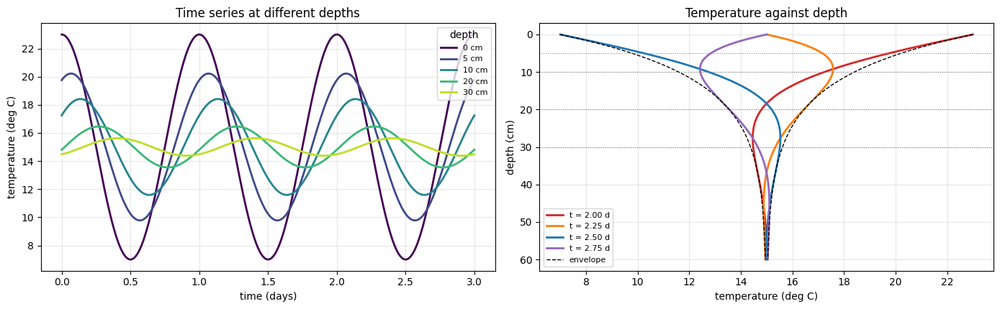

In [ ]:
t_fine = np.linspace(0.0, 3.0, 600)
z_fine = np.linspace(0.0, Z_MAX, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for z_cm, colour in zip((0, 5, 10, 20, 30), plt.cm.viridis(np.linspace(0.0, 0.9, 5))):
    axes[0].plot(t_fine, to_celsius(exact_theta(z_cm / 100.0, t_fine)), color=colour, lw=2, label=f"{z_cm} cm")
axes[0].set_xlabel("time (days)")
axes[0].set_ylabel("temperature (deg C)")
axes[0].set_title("Time series at different depths")
axes[0].legend(title="depth", loc="upper right", fontsize=8)
axes[0].grid(alpha=0.3)

for t_day, colour in zip((2.0, 2.25, 2.5, 2.75), ("tab:red", "tab:orange", "tab:blue", "tab:purple")):
    axes[1].plot(to_celsius(exact_theta(z_fine, t_day)), 100 * z_fine, color=colour, lw=2, label=f"t = {t_day:.2f} d")
axes[1].plot(to_celsius(np.exp(-z_fine / d_true)), 100 * z_fine, "k--", lw=1)
axes[1].plot(to_celsius(-np.exp(-z_fine / d_true)), 100 * z_fine, "k--", lw=1, label="envelope")
for z_cm in (5, 10, 20, 30):
    axes[1].axhline(z_cm, color="gray", ls=":", lw=0.8)
axes[1].invert_yaxis()
axes[1].set_xlabel("temperature (deg C)")
axes[1].set_ylabel("depth (cm)")
axes[1].set_title("Temperature against depth")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Try it yourself (Jupyter or Colab).** The sliders change the diffusivity, the surface swing and the sensor depth. Watch how a larger diffusivity lets the wave travel deeper and arrive sooner. If `ipywidgets` is not installed, the cell prints a hint and moves on.

In [ ]:
def explore_soil(alpha_1e7=5.0, swing=8.0, sensor_depth_cm=10):
    alpha = alpha_1e7 * 1e-7 * 86400.0                  # m^2/s -> m^2/day
    d = damping_depth(alpha)
    tt = np.linspace(0.0, 3.0, 500)
    zz = np.linspace(0.0, 0.6, 300)
    z_s = sensor_depth_cm / 100.0
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(tt, T_MEAN + swing * np.cos(OMEGA * tt), color="gray", lw=1.5, label="surface")
    axes[0].plot(tt, T_MEAN + swing * exact_theta(z_s, tt, alpha), color="tab:red", lw=2.2,
                 label=f"{sensor_depth_cm} cm deep")
    axes[0].set_ylim(T_MEAN - 9, T_MEAN + 9)
    axes[0].set_xlabel("time (days)")
    axes[0].set_ylabel("temperature (deg C)")
    axes[0].legend(loc="upper right")
    axes[0].grid(alpha=0.3)
    for t_day, colour in zip((2.0, 2.25, 2.5, 2.75), ("tab:red", "tab:orange", "tab:blue", "tab:purple")):
        axes[1].plot(T_MEAN + swing * exact_theta(zz, t_day, alpha), 100 * zz, color=colour, lw=2)
    axes[1].plot(T_MEAN + swing * np.exp(-zz / d), 100 * zz, "k--", lw=1)
    axes[1].plot(T_MEAN - swing * np.exp(-zz / d), 100 * zz, "k--", lw=1)
    axes[1].axhline(sensor_depth_cm, color="tab:red", ls=":")
    axes[1].set_xlim(T_MEAN - 9, T_MEAN + 9)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("temperature (deg C)")
    axes[1].set_ylabel("depth (cm)")
    # axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)
    lag_h = 24 * z_s / (d * OMEGA)
    fig.suptitle(f"alpha = {alpha_1e7:.1f}e-7 m^2/s:  damping depth {100*d:.1f} cm,  "
                 f"amplitude at the sensor {100*np.exp(-z_s/d):.0f}% of the surface,  delay {lag_h:.1f} h")
    plt.tight_layout()
    plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(
        explore_soil,
        alpha_1e7=widgets.FloatSlider(value=5.0, min=1.0, max=15.0, step=0.5, description="alpha (1e-7 m2/s)"),
        swing=widgets.FloatSlider(value=8.0, min=2.0, max=12.0, step=0.5, description="swing (deg C)"),
        sensor_depth_cm=widgets.IntSlider(value=10, min=2, max=40, step=1, description="sensor (cm)"),
    )
except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")

## S6. The heat-shield case (formula 5)
Sudden heating at the surface, from background section 6. The curves are $\operatorname{erfc}\big(z/(2\sqrt{\alpha t})\big)$ at several times, for an illustrative tile with $\alpha=5\times10^{-7}$ m²/s heated for up to ten minutes. The dashed circles are the Crank–Nicolson solution for the same problem (the check on the derivation).

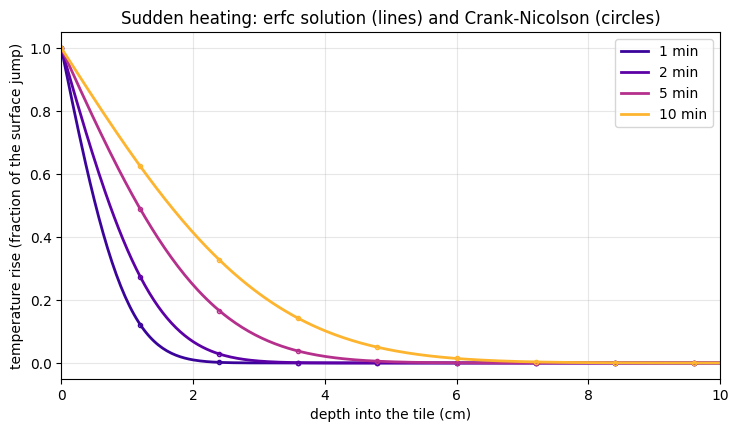

heated depth after 10 minutes, 3.6*sqrt(alpha*t) = 6.2 cm


In [ ]:
alpha_tile = 5.0e-7                       # m^2/s (illustrative)
z_tile = np.linspace(0.0, 0.10, 300)      # first 10 cm
minutes = (1, 2, 5, 10)

# same problem with the classical solver (time in seconds here; the surface jumps to 1 at once)
z_chk, t_chk, f_chk = fd_solve(alpha_tile, lambda t: 1.0, 0.30, 600.0, dz=0.001, dt=0.5)

plt.figure(figsize=(8.5, 4.5))
for m_ in minutes:
    colour = plt.cm.plasma(m_ / 12.0)
    plt.plot(100 * z_tile, erfc(z_tile / (2 * np.sqrt(alpha_tile * 60 * m_))), color=colour, lw=2, label=f"{m_} min")
    k_ = int(round(60 * m_ / 0.5))
    plt.plot(100 * z_chk[::12], f_chk[k_][::12], "o", color=colour, ms=3, mfc="none")
plt.xlabel("depth into the tile (cm)")
plt.ylabel("temperature rise (fraction of the surface jump)")
plt.title("Sudden heating: erfc solution (lines) and Crank-Nicolson (circles)")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 10)
plt.show()
print(f"heated depth after 10 minutes, 3.6*sqrt(alpha*t) = {100*3.6*np.sqrt(alpha_tile*600):.1f} cm")

## S7. The sensor readings
We bury four sensors at **5, 10, 20 and 30 cm**. They log the temperature **every hour for three days**, with random noise of **0.2 °C** (a typical value for a cheap thermistor). The surface temperature comes from a separate record (say an infrared thermometer), which we take as the clean daily cosine. The random seed is fixed so every run gives the same readings. The readings are stored in units of the surface swing, as the network will see them.

292 readings from 4 sensors; noise = 0.2 deg C (0.025 of the surface swing)


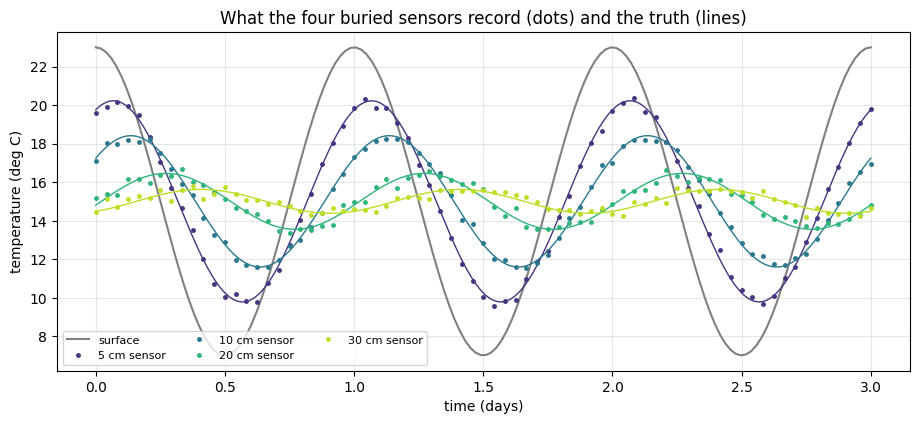

In [ ]:
sensor_depths = np.array([0.05, 0.10, 0.20, 0.30])         # metres
sensor_times = np.arange(0.0, T_MAX + 1e-9, 1.0 / 24.0)    # hourly, in days
noise_celsius = 0.2
noise_theta = noise_celsius / AMP

rng_data = np.random.default_rng(5)
theta_clean = exact_theta(sensor_depths[:, None], sensor_times[None, :])           # shape (4, 73)
theta_matrix = theta_clean + noise_theta * rng_data.standard_normal(theta_clean.shape)

# the same readings as a list of points: (depth, time) and the value
zt_data = np.array([(z, t) for z in sensor_depths for t in sensor_times])
theta_data = theta_matrix.reshape(-1, 1)

# surface record: the clean daily cosine, sampled 150 times
t_surface = np.linspace(0.0, T_MAX, 150)
print(f"{len(zt_data)} readings from {len(sensor_depths)} sensors; noise = {noise_celsius} deg C "
      f"({noise_theta:.3f} of the surface swing)")

plt.figure(figsize=(11, 4.4))
plt.plot(t_surface, to_celsius(np.cos(OMEGA * t_surface)), color="gray", lw=1.5, label="surface")
for i, (z, colour) in enumerate(zip(sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    plt.plot(sensor_times, to_celsius(theta_matrix[i]), ".", color=colour, ms=5, label=f"{int(100*z)} cm sensor")
    plt.plot(t_fine, to_celsius(exact_theta(z, t_fine)), "-", color=colour, lw=1)
plt.xlabel("time (days)")
plt.ylabel("temperature (deg C)")
plt.title("What the four buried sensors record (dots) and the truth (lines)")
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## S8. The classical estimators and how well they do
Three ways to turn these readings into a diffusivity, all from background section 4:

* **Amplitude method:** fit a daily cosine to each sensor, then use $\ln A_i=\ln A-z_i/d$. We fit a line through the origin (the surface amplitude is known to be 1 here) by least squares, which uses all four sensors.
* **Phase method:** the same with the delay, $\varphi_i=z_i/d$.
* **Formula fit:** adjust $\alpha$ until formula (4) matches all the readings as closely as possible (least squares). This is the best use of the data when the exact formula applies.

The cell applies them to our readings. Then it repeats the experiment 300 times with fresh random noise, to show how much each method typically wanders.

method                  alpha (m^2/day)    error
amplitude method                0.04140    -4.2%
phase method                    0.04337     0.4%
formula fit                     0.04223    -2.2%
truth                           0.04320

Over 300 repeats with new noise (error in percent):
  amplitude method   mean   0.41%   spread (std)  2.86%   worst  10.4%
  phase method       mean  -0.00%   spread (std)  2.77%   worst   8.1%
  formula fit        mean   0.02%   spread (std)  0.94%   worst   2.6%


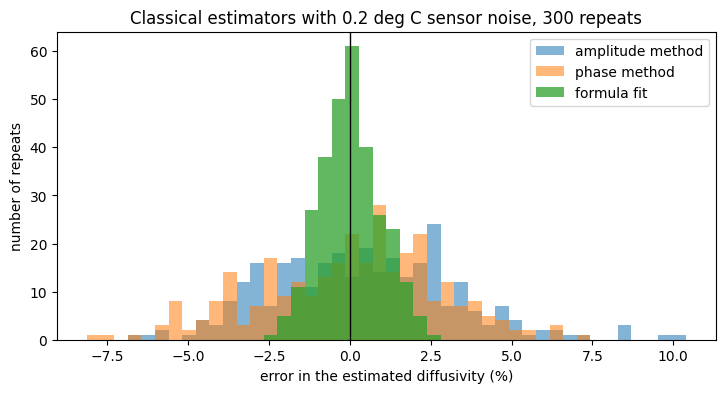

In [ ]:
_design = np.column_stack([np.ones_like(sensor_times), np.cos(OMEGA * sensor_times), np.sin(OMEGA * sensor_times)])

def amplitude_and_phase(theta_by_depth):
    # least-squares daily cosine for every sensor record
    coef = np.linalg.lstsq(_design, theta_by_depth.T, rcond=None)[0]      # rows: mean, cos, sin
    return np.hypot(coef[1], coef[2]), np.arctan2(coef[2], coef[1])


def classical_alphas(theta_by_depth, depths=sensor_depths):
    amplitude, phase = amplitude_and_phase(theta_by_depth)
    d_amp = -np.sum(depths**2) / np.sum(depths * np.log(amplitude))       # ln A = -z/d, line through the origin
    d_phase = np.sum(depths**2) / np.sum(depths * phase)                  # phase = z/d
    return OMEGA * d_amp**2 / 2.0, OMEGA * d_phase**2 / 2.0


def formula_fit_alpha(theta_by_depth, depths=sensor_depths):
    misfit = lambda a: np.sum((theta_by_depth - exact_theta(depths[:, None], sensor_times[None, :], a)) ** 2)
    return minimize_scalar(misfit, bounds=(0.005, 0.2), method="bounded", options={"xatol": 1e-9}).x


alpha_amp, alpha_phase = classical_alphas(theta_matrix)
alpha_fit = formula_fit_alpha(theta_matrix)
print(f"{'method':22s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase), ("formula fit", alpha_fit)):
    print(f"{name:22s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':22s}{ALPHA_TRUE:17.5f}")

# 300 repeats with fresh noise
rng_mc = np.random.default_rng(123)
repeats = []
for _ in range(300):
    noisy = theta_clean + noise_theta * rng_mc.standard_normal(theta_clean.shape)
    repeats.append((*classical_alphas(noisy), formula_fit_alpha(noisy)))
repeats = np.array(repeats)
error_pct = 100 * (repeats / ALPHA_TRUE - 1)
print("\nOver 300 repeats with new noise (error in percent):")
for col, name in enumerate(("amplitude method", "phase method", "formula fit")):
    print(f"  {name:18s} mean {error_pct[:, col].mean():6.2f}%   spread (std) {error_pct[:, col].std():5.2f}%   "
          f"worst {np.abs(error_pct[:, col]).max():5.1f}%")

plt.figure(figsize=(8.5, 4))
bins = np.linspace(error_pct.min(), error_pct.max(), 45)
plt.hist(error_pct[:, 0], bins=bins, alpha=0.55, label="amplitude method")
plt.hist(error_pct[:, 1], bins=bins, alpha=0.55, label="phase method")
plt.hist(error_pct[:, 2], bins=bins, alpha=0.75, label="formula fit")
plt.axvline(0, color="k", lw=1)
plt.xlabel("error in the estimated diffusivity (%)")
plt.ylabel("number of repeats")
plt.title("Classical estimators with 0.2 deg C sensor noise, 300 repeats")
plt.legend()
plt.show()

Two things to take away. First, with four sensors and hourly readings, even the simple amplitude and phase methods work, with typical errors around 3%. Second, the formula fit is about three times tighter, because it uses every reading in the way the physics says it should. Keep these numbers in mind: they are what the neural network has to be judged against.

## S9. The evaluation grid and the video helpers

A fixed grid of depths and times is used to compare each network with the exact answer and to draw the animation. Then the helper functions, used by both parts:

* `rmse` measures an error; `make_snapshot_epochs` picks which epochs to record (many early, fewer later).
* `make_training_video` draws a two-column animation: a network that sees **only the sensors** next to a network that also knows **the heat equation**. For each it shows the depth–time temperature map, the temperature profile with depth at one moment (day 2, when the surface is warmest), and a strip with the error and (for the physics network) the diffusivity estimate as training goes on. It writes a GIF with Pillow and an MP4 with `ffmpeg`.
* `convert_mp4_to_gif` turns an MP4 into a GIF. `snapshot_grid` is a still picture of a few moments (it shows on GitHub), and `scrub_epochs` is a slider.

Each "run" is a dictionary with a name, a colour, the saved temperature maps `theta` (one row per snapshot), the saved diffusivity estimates `alpha` (or `None`), and the saved errors `rmse`.

In [ ]:
# evaluation grid: 31 depths x 91 times
GRID_Z = np.linspace(0.0, Z_MAX, 31)
GRID_T = np.linspace(0.0, T_MAX, 91)
GRID_ZZ, GRID_TT = np.meshgrid(GRID_Z, GRID_T, indexing="ij")
GRID_POINTS = np.column_stack([GRID_ZZ.ravel(), GRID_TT.ravel()])      # (n, 2): depth, time
GRID_EXACT = exact_theta(GRID_ZZ, GRID_TT).ravel()
PROFILE_TIME = 2.0                                                      # moment shown in the profile panel


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def make_snapshot_epochs(epochs, n_snapshots=90):
    # epoch 0 plus a geometric spread up to the final epoch
    spread = np.unique(np.round(np.geomspace(1, epochs, n_snapshots)).astype(int))
    return sorted(set([0] + spread.tolist()))


def find_ffmpeg():
    path = shutil.which("ffmpeg")
    if path:
        return path
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None

In [ ]:
def make_training_video(epochs_saved, runs, mp4_path=None, gif_path=None, fps=12, hold_frames=18,
                        mp4_dpi=90, gif_dpi=60):
    # runs: two dictionaries with keys "name", "color", "theta" (n_snap x n_grid), "alpha" (n_snap or None), "rmse" (n_snap)
    epochs_saved = np.asarray(epochs_saved)
    nz, nt = len(GRID_Z), len(GRID_T)
    i_profile = int(np.argmin(np.abs(GRID_T - PROFILE_TIME)))
    exact_profile = to_celsius(GRID_EXACT.reshape(nz, nt)[:, i_profile])
    sensor_at_profile = int(np.argmin(np.abs(sensor_times - PROFILE_TIME)))

    fig = plt.figure(figsize=(12, 7.2))                  # even pixel sizes, needed for MP4
    gs = fig.add_gridspec(3, 3, height_ratios=[1.5, 1.7, 1.2], width_ratios=[1, 1, 0.04])
    ax_map = [fig.add_subplot(gs[0, j]) for j in range(2)]
    ax_cbar = fig.add_subplot(gs[0, 2])
    ax_prof = [fig.add_subplot(gs[1, j]) for j in range(2)]
    ax_err = fig.add_subplot(gs[2, 0])
    ax_alpha = fig.add_subplot(gs[2, 1])

    images, lines = [], []
    for j, run in enumerate(runs):
        ax = ax_map[j]
        image = ax.imshow(np.zeros((nz, nt)), aspect="auto", origin="upper", cmap="coolwarm", vmin=T_MEAN - AMP,
                          vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
        for z in sensor_depths:
            ax.axhline(100 * z, color="k", lw=0.6, ls=":")
        ax.set_title(run["name"], fontsize=12)
        ax.set_ylabel("depth (cm)")
        ax.set_xlabel("time (days)")
        images.append(image)

        axp = ax_prof[j]
        axp.plot(exact_profile, 100 * GRID_Z, "k--", lw=1.3, label="exact")
        axp.scatter(to_celsius(theta_matrix[:, sensor_at_profile]), 100 * sensor_depths, color="crimson", zorder=3, s=25, label="sensor readings")
        line, = axp.plot([], [], color=run["color"], lw=2.6, label="network")
        axp.set_xlim(T_MEAN - AMP * 1.15, T_MEAN + AMP * 1.15)
        axp.set_ylim(100 * Z_MAX, 0)
        axp.set_xlabel(f"temperature (deg C) at day {PROFILE_TIME:.0f}")
        axp.set_ylabel("depth (cm)")
        axp.grid(alpha=0.3)
        axp.legend(loc="lower left", fontsize=8)
        lines.append(line)
    fig.colorbar(images[1], cax=ax_cbar, label="temperature (deg C)")

    all_rmse = np.concatenate([np.asarray(r["rmse"]) for r in runs])
    ax_err.set_xscale("log"); ax_err.set_yscale("log")
    ax_err.set_xlim(1, epochs_saved.max() * 1.1)
    ax_err.set_ylim(all_rmse.min() * 0.7, all_rmse.max() * 1.4)
    ax_err.set_xlabel("epoch"); ax_err.set_ylabel("error vs exact (deg C)")
    ax_err.grid(alpha=0.3, which="both")
    err_curves, err_dots = [], []
    for run in runs:
        c, = ax_err.plot([], [], color=run["color"], lw=2)
        d, = ax_err.plot([], [], "o", color=run["color"])
        err_curves.append(c); err_dots.append(d)

    ax_alpha.set_xscale("log")
    ax_alpha.set_xlim(1, epochs_saved.max() * 1.1)
    alpha_values = [np.asarray(r["alpha"]) for r in runs if r["alpha"] is not None]
    a_all = np.concatenate(alpha_values) if alpha_values else np.array([ALPHA_TRUE])
    ax_alpha.set_ylim(0, max(a_all.max(), ALPHA_TRUE) * 1.15)
    ax_alpha.axhline(ALPHA_TRUE, color="k", ls="--", lw=1.2, label=f"true alpha = {ALPHA_TRUE:.4f}")
    ax_alpha.set_xlabel("epoch"); ax_alpha.set_ylabel("estimated alpha (m$^2$/day)")
    ax_alpha.grid(alpha=0.3, which="both")
    alpha_curves, alpha_dots = [], []
    for run in runs:
        if run["alpha"] is None:
            alpha_curves.append(None); alpha_dots.append(None); continue
        c, = ax_alpha.plot([], [], color=run["color"], lw=2, label="estimate (physics network)")
        d, = ax_alpha.plot([], [], "o", color=run["color"])
        alpha_curves.append(c); alpha_dots.append(d)
    ax_alpha.legend(loc="upper left", fontsize=8)
    title = fig.suptitle("", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    epochs_plot = np.maximum(epochs_saved, 1)
    frames = list(range(len(epochs_saved))) + [len(epochs_saved) - 1] * hold_frames

    def update(i):
        artists = []
        for j, run in enumerate(runs):
            field = to_celsius(np.asarray(run["theta"][i]).reshape(nz, nt))
            images[j].set_data(field)
            lines[j].set_data(field[:, i_profile], 100 * GRID_Z)
            err_curves[j].set_data(epochs_plot[: i + 1], np.asarray(run["rmse"])[: i + 1])
            err_dots[j].set_data([epochs_plot[i]], [run["rmse"][i]])
            artists += [images[j], lines[j], err_curves[j], err_dots[j]]
            if alpha_curves[j] is not None:
                alpha_curves[j].set_data(epochs_plot[: i + 1], np.asarray(run["alpha"])[: i + 1])
                alpha_dots[j].set_data([epochs_plot[i]], [run["alpha"][i]])
                artists += [alpha_curves[j], alpha_dots[j]]
        title.set_text(f"Training epoch {int(epochs_saved[i]):,}")
        return artists + [title]

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)

    if gif_path is not None:
        anim.save(str(gif_path), writer=animation.PillowWriter(fps=fps), dpi=gif_dpi)
        print(f"saved GIF: {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    if mp4_path is not None:
        ffmpeg = find_ffmpeg()
        if ffmpeg is None:
            print("ffmpeg was not found, so no MP4 was written. Install ffmpeg, or run: pip install imageio-ffmpeg")
        else:
            plt.rcParams["animation.ffmpeg_path"] = ffmpeg
            anim.save(str(mp4_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2200), dpi=mp4_dpi)
            print(f"saved MP4: {mp4_path}  ({Path(mp4_path).stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)
    return anim


def convert_mp4_to_gif(mp4_path, gif_path, fps=12, width=800):
    # convert an existing MP4 to a GIF with ffmpeg. The palette step keeps the colours clean.
    ffmpeg = find_ffmpeg()
    if ffmpeg is None:
        print("ffmpeg was not found, so the MP4 could not be converted.")
        return None
    filters = f"fps={fps},scale={width}:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse"
    subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(mp4_path), "-vf", filters, str(gif_path)], check=True)
    print(f"converted {mp4_path} -> {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    return gif_path

In [ ]:
def scrub_epochs(epochs_saved, runs):
    # epoch slider (needs ipywidgets in Jupyter or Colab).
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets is not installed. Run: pip install ipywidgets")
        return
    nz, nt = len(GRID_Z), len(GRID_T)
    i_profile = int(np.argmin(np.abs(GRID_T - PROFILE_TIME)))
    sensor_at_profile = int(np.argmin(np.abs(sensor_times - PROFILE_TIME)))

    def draw(snapshot):
        fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 4.2), sharey=True)
        for ax, run in zip(np.atleast_1d(axes), runs):
            field = to_celsius(np.asarray(run["theta"][snapshot]).reshape(nz, nt))
            ax.plot(to_celsius(GRID_EXACT.reshape(nz, nt)[:, i_profile]), 100 * GRID_Z, "k--", lw=1.2, label="exact")
            ax.scatter(to_celsius(theta_matrix[:, sensor_at_profile]), 100 * sensor_depths, color="crimson", zorder=3, s=25, label="sensors")
            ax.plot(field[:, i_profile], 100 * GRID_Z, color=run["color"], lw=2.5, label="network")
            extra = "" if run["alpha"] is None else f",  alpha = {run['alpha'][snapshot]:.4f}"
            ax.set_title(f"{run['name']}\nerror {run['rmse'][snapshot]:.2f} deg C{extra}")
            ax.set_xlabel(f"temperature (deg C) at day {PROFILE_TIME:.0f}")
            ax.set_xlim(T_MEAN - AMP * 1.15, T_MEAN + AMP * 1.15)
            ax.set_ylim(100 * Z_MAX, 0)
            ax.grid(alpha=0.3)
        np.atleast_1d(axes)[0].set_ylabel("depth (cm)")
        np.atleast_1d(axes)[0].legend(loc="lower left", fontsize=8)
        fig.suptitle(f"epoch {int(epochs_saved[snapshot]):,}", fontweight="bold")
        plt.tight_layout()
        plt.show()

    slider = widgets.SelectionSlider(options=[(f"{int(e):,}", i) for i, e in enumerate(epochs_saved)],
                                     description="epoch", layout=widgets.Layout(width="85%"))
    widgets.interact(draw, snapshot=slider)


def snapshot_grid(epochs_saved, runs, picks=(0, 100, 1000, 3000, 8000)):
    # still picture of a few moments in training (it also shows on GitHub, where sliders do not).
    epochs_saved = np.asarray(epochs_saved)
    nz, nt = len(GRID_Z), len(GRID_T)
    idx = [int(np.argmin(np.abs(epochs_saved - p))) for p in picks]
    fig, axes = plt.subplots(len(runs), len(idx), figsize=(3.3 * len(idx), 2.7 * len(runs)),
                             sharex=True, sharey=True, squeeze=False)
    for col, i in enumerate(idx):
        for row, run in enumerate(runs):
            ax = axes[row, col]
            field = to_celsius(np.asarray(run["theta"][i]).reshape(nz, nt))
            ax.imshow(field, aspect="auto", origin="upper", cmap="coolwarm", vmin=T_MEAN - AMP, vmax=T_MEAN + AMP,
                      extent=[0, T_MAX, 100 * Z_MAX, 0])
            for z in sensor_depths:
                ax.axhline(100 * z, color="k", lw=0.5, ls=":")
            if row == 0:
                ax.set_title(f"epoch {int(epochs_saved[i]):,}", fontsize=11)
            if col == 0:
                ax.set_ylabel(run["name"].split("(")[0].strip() + "\ndepth (cm)")
            if row == len(runs) - 1:
                ax.set_xlabel("time (days)")
    plt.tight_layout()
    plt.show()

---
## Setup for case study 2: the heat-shield tile

The cells below set up the tile problem: constants, a finite-thickness exact solution, the re-entry heating history with a classical-solver "truth", an interactive design explorer, the thermocouple readings, and a classical way to read them. Time is in **minutes** here, depth in metres and temperature in °C.

## S10. The tile: constants and a picture
Properties are computed from the conductivity, density and specific heat, so the link $\alpha=k/(\rho c)$ stays visible.

alpha = 4.0e-07 m^2/s = 2.4e-05 m^2/min
slowest time constant tau = 4 L^2 / (pi^2 alpha) = 83 minutes  (the heating lasts 19 minutes)
diffusion length after 19 minutes, sqrt(alpha t) = 2.1 cm


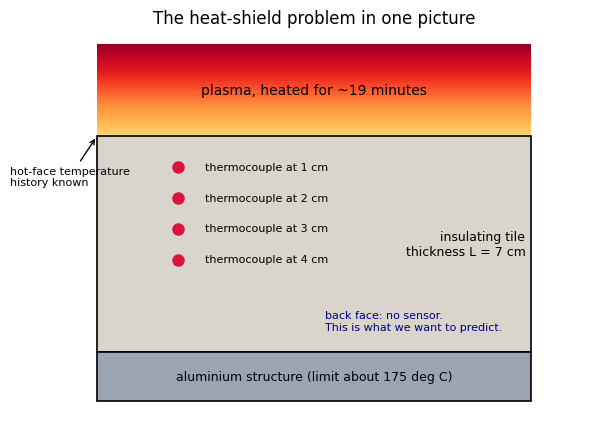

In [ ]:
# the heat-shield tile (illustrative values; time in MINUTES, depth in metres, temperature in deg C)
TILE_K, TILE_RHO, TILE_C = 0.06, 150.0, 1000.0           # W/m/K, kg/m^3, J/kg/K
TILE_ALPHA_S = TILE_K / (TILE_RHO * TILE_C)             # diffusivity in m^2/s  (4.0e-7)
TILE_ALPHA = TILE_ALPHA_S * 60.0                        # the same in m^2/min   (2.4e-5)
TILE_L = 0.07                                           # thickness (m)
TILE_T0, TILE_TPK = 20.0, 1200.0                        # start temperature and peak surface temperature
TILE_DT = TILE_TPK - TILE_T0                            # scale for the temperature rise
TILE_TEND = 60.0                                        # we follow the tile for 60 minutes
BOND_LIMIT = 175.0                                      # illustrative limit for the structure behind the tile

tau_slow = 4 * TILE_L**2 / (np.pi**2 * TILE_ALPHA)
print(f"alpha = {TILE_ALPHA_S:.1e} m^2/s = {TILE_ALPHA:.1e} m^2/min")
print(f"slowest time constant tau = 4 L^2 / (pi^2 alpha) = {tau_slow:.0f} minutes  (the heating lasts 19 minutes)")
print(f"diffusion length after 19 minutes, sqrt(alpha t) = {100*np.sqrt(TILE_ALPHA*19):.1f} cm")


def draw_tile_schematic(ax):
    # a simple cross-section of the heat shield: plasma, tile, thermocouples, structure
    ax.set_xlim(0, 10)
    ax.set_ylim(9.6, -3.4)
    ax.axis("off")
    for k in range(40):                                              # glowing plasma above the hot face
        ax.add_patch(plt.Rectangle((1, -3 + 3 * k / 40), 8, 3 / 40, color=plt.cm.YlOrRd(0.95 - 0.7 * k / 40), lw=0))
    ax.text(5, -1.5, "plasma, heated for ~19 minutes", ha="center", va="center", fontsize=10)
    ax.add_patch(plt.Rectangle((1, 0), 8, 7, facecolor="#d9d4cc", edgecolor="k", lw=1.2))
    ax.text(8.9, 3.5, "insulating tile\nthickness L = 7 cm", ha="right", va="center", fontsize=9, rotation=0)
    for depth_cm in (1, 2, 3, 4):
        ax.plot([2.5], [depth_cm], "o", color="crimson", ms=8, zorder=3)
        ax.text(3.0, depth_cm, f"thermocouple at {depth_cm} cm", va="center", fontsize=8)
    ax.add_patch(plt.Rectangle((1, 7), 8, 1.6, facecolor="#9aa5b1", edgecolor="k", lw=1.2))
    ax.text(5, 7.8, f"aluminium structure (limit about {BOND_LIMIT:.0f} deg C)", ha="center", va="center", fontsize=9)
    ax.annotate("hot-face temperature\nhistory known", (1, 0), (-0.6, 1.6), fontsize=8, arrowprops=dict(arrowstyle="->"), ha="left")
    ax.annotate("back face: no sensor.\nThis is what we want to predict.", (5, 7), (5.2, 6.3), fontsize=8, color="navy", ha="left")


fig, ax = plt.subplots(figsize=(7, 5.2))
draw_tile_schematic(ax)
ax.set_title("The heat-shield problem in one picture")
plt.show()

## S11. The finite-thickness solution (formula 7) and a check
Formula (7) from background section 12.3, for a sudden step at the hot face and an insulated back. We check it against the Crank–Nicolson solver (which gets a small new option for an insulated back face: at the last grid point the missing neighbour is a mirror image of the one before it). The right plot shows the step response at several depths and the time constant $\tau$.

largest difference between formula (7) and the solver: 2.8e-05


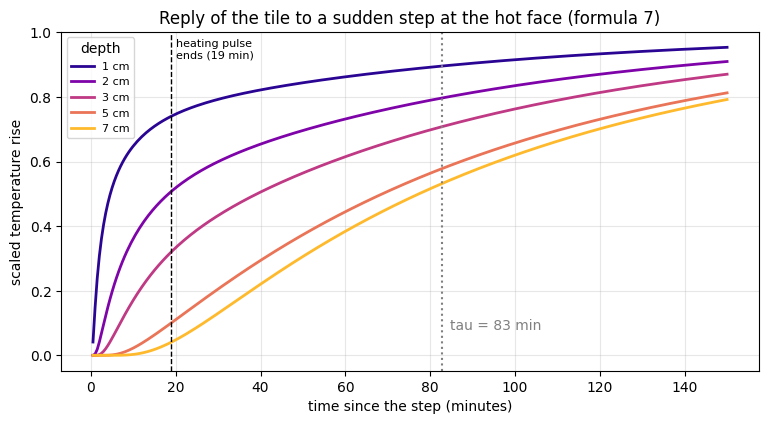

In [ ]:
def slab_step_response(z, t, L=TILE_L, alpha=TILE_ALPHA, n_terms=200):
    # formula (7): scaled temperature rise for a step at the hot face, insulated back
    z = np.atleast_1d(z)[:, None]
    t = np.atleast_1d(t)[None, :]
    n = np.arange(n_terms)
    lam = (2 * n + 1) * np.pi / (2 * L)
    coeff = (4.0 / ((2 * n + 1) * np.pi))[:, None, None]
    terms = coeff * np.sin(lam[:, None, None] * z[None]) * np.exp(-alpha * lam[:, None, None] ** 2 * t[None])
    return 1.0 - terms.sum(axis=0)


# check against the classical solver (insulated back), at three times
z_chk, t_chk, f_chk = fd_solve(TILE_ALPHA, lambda t: 1.0, TILE_L, 60.0, dz=0.0005, dt=0.02, insulated_back=True)
t_test = np.array([5.0, 20.0, 60.0])
solver_values = np.array([f_chk[int(round(t / 0.02))] for t in t_test]).T
series_values = slab_step_response(z_chk, t_test)
print(f"largest difference between formula (7) and the solver: {np.abs(series_values - solver_values).max():.1e}")

t_long = np.linspace(0.5, 150.0, 300)
plt.figure(figsize=(9, 4.4))
for z_cm, colour in zip((1, 2, 3, 5, 7), plt.cm.plasma(np.linspace(0.05, 0.85, 5))):
    plt.plot(t_long, slab_step_response(z_cm / 100.0, t_long)[0], color=colour, lw=2, label=f"{z_cm} cm")
plt.axvline(tau_slow, color="gray", ls=":")
plt.text(tau_slow + 2, 0.08, f"tau = {tau_slow:.0f} min", color="gray")
plt.axvline(19, color="k", ls="--", lw=1)
plt.text(20, 0.92, "heating pulse\nends (19 min)", fontsize=8)
plt.xlabel("time since the step (minutes)")
plt.ylabel("scaled temperature rise")
plt.title("Reply of the tile to a sudden step at the hot face (formula 7)")
plt.legend(title="depth", fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## S12. Re-entry heating and the classical "truth"
The surface history $s(t)$ of background section 12.2, and the resulting temperatures from the Crank–Nicolson solver on a fine grid (`dz = 0.5 mm`, `dt = 1.2 s`). This is the "truth" the networks will be compared with. We also ask the engineering question: **is the back face safe?** The first plot follows the surface and several depths. The second zooms in on the back face with the limit. The third is the whole depth–time map.

In [ ]:
def reentry_pulse(t):
    # scaled surface temperature rise s(t), t in minutes (background section 12.2)
    t = np.asarray(t, dtype=float)
    rise = np.sin(np.pi * t / 8.0) ** 2
    fall = np.cos(np.pi * (t - 9.0) / 20.0) ** 2
    return np.where(t < 4.0, rise, np.where(t < 9.0, 1.0, np.where(t < 19.0, fall, 0.0)))


tile_z, tile_t, tile_field = fd_solve(TILE_ALPHA, reentry_pulse, TILE_L, TILE_TEND, dz=0.0005, dt=0.02, insulated_back=True)
tile_truth = RegularGridInterpolator((tile_t, tile_z), tile_field)


def tile_temp_series(depth, minutes):
    # true temperature (deg C) at one depth for an array of times
    minutes = np.asarray(minutes, dtype=float)
    return TILE_T0 + TILE_DT * tile_truth(np.column_stack([minutes, np.full_like(minutes, depth)]))


minutes_fine = np.linspace(0.0, TILE_TEND, 601)
back_true = tile_temp_series(TILE_L, minutes_fine)
i_pk = int(np.argmax(back_true))
print(f"back-face peak: {back_true[i_pk]:.0f} deg C at minute {minutes_fine[i_pk]:.1f}")
print(f"margin below the {BOND_LIMIT:.0f} deg C limit: {BOND_LIMIT - back_true[i_pk]:.0f} deg C")
print(f"the peak comes {minutes_fine[i_pk] - 19:.0f} minutes AFTER the surface heating has ended (heat soak)")


def back_face_peak(thickness, alpha=TILE_ALPHA, t_end=100.0):
    # peak back-face temperature and its time, for a tile of a different thickness (coarser grid, quick)
    z, t, f = fd_solve(alpha, reentry_pulse, thickness, t_end, dz=0.001, dt=0.05, insulated_back=True)
    back = TILE_T0 + TILE_DT * f[:, -1]
    return back.max(), t[int(np.argmax(back))]

print("\nthickness   peak back-face   at minute   verdict")
for cm in (5, 6, 7, 8):
    peak, t_peak = back_face_peak(cm / 100.0)
    print(f"{cm:6d} cm   {peak:10.0f} C   {t_peak:9.1f}   {'OK' if peak < BOND_LIMIT else 'TOO HOT'}")

back-face peak: 147 deg C at minute 43.1
margin below the 175 deg C limit: 28 deg C
the peak comes 24 minutes AFTER the surface heating has ended (heat soak)

thickness   peak back-face   at minute   verdict
     5 cm          262 C        27.2   TOO HOT
     6 cm          192 C        34.4   TOO HOT
     7 cm          147 C        43.1   OK
     8 cm          118 C        53.2   OK


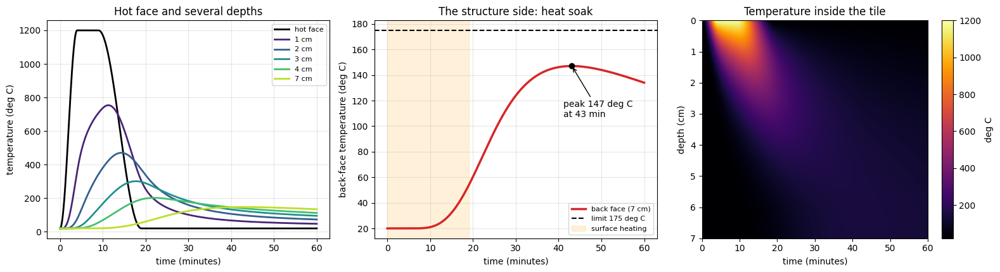

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(minutes_fine, TILE_T0 + TILE_DT * reentry_pulse(minutes_fine), "k", lw=2, label="hot face")
for z_cm, colour in zip((1, 2, 3, 4, 7), plt.cm.viridis(np.linspace(0.1, 0.9, 5))):
    axes[0].plot(minutes_fine, tile_temp_series(z_cm / 100.0, minutes_fine), color=colour, lw=2, label=f"{z_cm} cm")
axes[0].set_xlabel("time (minutes)")
axes[0].set_ylabel("temperature (deg C)")
axes[0].set_title("Hot face and several depths")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(minutes_fine, back_true, color="tab:red", lw=2.5, label="back face (7 cm)")
axes[1].axhline(BOND_LIMIT, color="k", ls="--", label=f"limit {BOND_LIMIT:.0f} deg C")
axes[1].axvspan(0, 19, color="orange", alpha=0.15, label="surface heating")
axes[1].plot(minutes_fine[i_pk], back_true[i_pk], "ko")
axes[1].annotate(f"peak {back_true[i_pk]:.0f} deg C\nat {minutes_fine[i_pk]:.0f} min", (minutes_fine[i_pk], back_true[i_pk]),
                 (minutes_fine[i_pk] - 2, back_true[i_pk] - 40), arrowprops=dict(arrowstyle="->"))
axes[1].set_xlabel("time (minutes)")
axes[1].set_ylabel("back-face temperature (deg C)")
axes[1].set_title("The structure side: heat soak")
axes[1].legend(fontsize=8, loc="lower right")
axes[1].grid(alpha=0.3)

img = axes[2].imshow(TILE_T0 + TILE_DT * tile_field.T, aspect="auto", origin="upper", cmap="inferno",
                     extent=[0, TILE_TEND, 100 * TILE_L, 0])
axes[2].set_xlabel("time (minutes)")
axes[2].set_ylabel("depth (cm)")
axes[2].set_title("Temperature inside the tile")
fig.colorbar(img, ax=axes[2], label="deg C")
plt.tight_layout()
plt.show()

## S13. Try it yourself: is this tile thick enough?
Sliders for the tile thickness, its diffusivity and the peak surface temperature. The plot shows the back-face temperature against the limit, using the classical solver. Watch how a thicker tile lowers the peak *and* delays it, and how a higher diffusivity (a worse insulator) does the opposite. If `ipywidgets` is not installed, the cell prints a hint and moves on.

In [ ]:
def explore_tile(thickness_cm=7.0, alpha_1e7=4.0, peak_surface=1200.0):
    alpha = alpha_1e7 * 1e-7 * 60.0                              # m^2/s -> m^2/min
    z, t, f = fd_solve(alpha, reentry_pulse, thickness_cm / 100.0, 120.0, dz=0.001, dt=0.05, insulated_back=True)
    back = TILE_T0 + (peak_surface - TILE_T0) * f[:, -1]
    mid = TILE_T0 + (peak_surface - TILE_T0) * f[:, int(len(z) // 2)]
    i = int(np.argmax(back))
    ok = back[i] < BOND_LIMIT
    plt.figure(figsize=(9.5, 4.4))
    plt.plot(t, TILE_T0 + (peak_surface - TILE_T0) * reentry_pulse(t), color="k", lw=1.2, label="hot face")
    plt.plot(t, mid, color="tab:orange", lw=1.8, label="halfway through the tile")
    plt.plot(t, back, color="tab:green" if ok else "tab:red", lw=2.8, label="back face")
    plt.axhline(BOND_LIMIT, color="k", ls="--")
    plt.text(2, BOND_LIMIT + 15, f"limit {BOND_LIMIT:.0f} deg C", fontsize=9)
    plt.plot(t[i], back[i], "ko")
    plt.ylim(0, 1300)
    plt.xlabel("time (minutes)")
    plt.ylabel("temperature (deg C)")
    plt.title(f"thickness {thickness_cm:.1f} cm, alpha = {alpha_1e7:.1f}e-7 m2/s:  back-face peak {back[i]:.0f} deg C at "
              f"minute {t[i]:.0f}  ->  {'OK' if ok else 'TOO HOT'}")
    plt.legend(fontsize=8, loc="upper right")
    plt.grid(alpha=0.3)
    plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(
        explore_tile,
        thickness_cm=widgets.FloatSlider(value=7.0, min=3.0, max=12.0, step=0.5, description="thickness (cm)"),
        alpha_1e7=widgets.FloatSlider(value=4.0, min=2.0, max=10.0, step=0.5, description="alpha (1e-7 m2/s)"),
        peak_surface=widgets.FloatSlider(value=1200.0, min=600.0, max=1600.0, step=50.0, description="peak surface (C)"),
    )
except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")

## S14. The thermocouple readings
Four thermocouples are embedded at **1, 2, 3 and 4 cm** from the hot face. They log **every 30 seconds for an hour**, with random noise of **3 °C** (a typical figure for a thermocouple system, chosen here for illustration). **Nothing is measured at the back face** (7 cm). The hot-face temperature history is known. The readings are stored as the scaled temperature rise, as the network will see them. The random seed is fixed so every run gives the same readings.

484 readings from 4 thermocouples; noise 3.0 deg C (0.0025 of the full temperature rise)


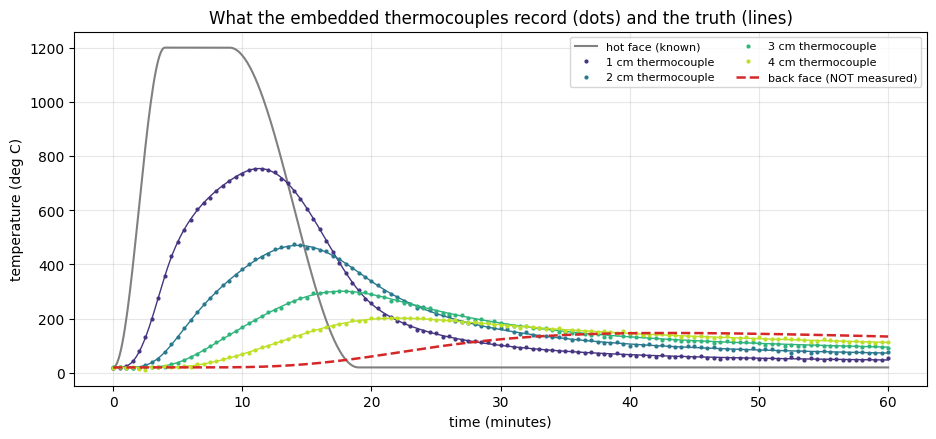

In [ ]:
tile_sensor_depths = np.array([0.01, 0.02, 0.03, 0.04])             # metres
tile_sensor_times = np.arange(0.0, TILE_TEND + 1e-9, 0.5)           # every 30 s, in minutes
tile_noise_c = 3.0                                                  # deg C
tile_noise_theta = tile_noise_c / TILE_DT

tile_pts = np.array([(t, z) for z in tile_sensor_depths for t in tile_sensor_times])      # (time, depth) for the interpolator
tile_theta_clean = tile_truth(tile_pts).reshape(len(tile_sensor_depths), len(tile_sensor_times))
tile_theta_matrix = tile_theta_clean + tile_noise_theta * np.random.default_rng(5).standard_normal(tile_theta_clean.shape)

tile_zt_data = np.array([(z, t) for z in tile_sensor_depths for t in tile_sensor_times])    # (depth, time) rows
tile_theta_data = tile_theta_matrix.reshape(-1, 1)
print(f"{len(tile_zt_data)} readings from {len(tile_sensor_depths)} thermocouples; noise {tile_noise_c} deg C "
      f"({tile_noise_theta:.4f} of the full temperature rise)")

plt.figure(figsize=(11, 4.6))
plt.plot(minutes_fine, TILE_T0 + TILE_DT * reentry_pulse(minutes_fine), color="gray", lw=1.5, label="hot face (known)")
for i, (z, colour) in enumerate(zip(tile_sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    plt.plot(tile_sensor_times, TILE_T0 + TILE_DT * tile_theta_matrix[i], ".", color=colour, ms=4, label=f"{int(100*z)} cm thermocouple")
    plt.plot(minutes_fine, tile_temp_series(z, minutes_fine), "-", color=colour, lw=1)
plt.plot(minutes_fine, back_true, "--", color="tab:red", lw=1.8, label="back face (NOT measured)")
plt.xlabel("time (minutes)")
plt.ylabel("temperature (deg C)")
plt.title("What the embedded thermocouples record (dots) and the truth (lines)")
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## S15. The classical way: fit with the solver
The standard approach for a problem like this is to **fit the diffusivity with a solver**: try a value, run the classical solver for the known hot-face history, compare with the readings, and adjust. It needs the solver to run many times. Once we have a diffusivity, the same solver predicts the back-face temperature.

The cell does this for our readings (with a coarser grid, `dz = 2 mm`, to keep it quick), and then repeats the experiment 40 times with fresh noise to show how much the answers typically wander. Both the diffusivity and the **predicted back-face peak** are of interest.

In [ ]:
def tile_solver_fit(theta_by_depth, dz=0.002, dt=0.1):
    # classical estimate: adjust alpha until the solver's temperatures match the readings (least squares)
    def misfit(a):
        z, t, f = fd_solve(a, reentry_pulse, TILE_L, TILE_TEND, dz=dz, dt=dt, insulated_back=True)
        interp = RegularGridInterpolator((t, z), f)
        return np.sum((theta_by_depth - interp(tile_pts).reshape(theta_by_depth.shape)) ** 2)
    return minimize_scalar(misfit, bounds=(1.0e-5, 5.0e-5), method="bounded", options={"xatol": 1e-9}).x


def peak_from_alpha(alpha):
    peak, t_peak = back_face_peak(TILE_L, alpha=alpha, t_end=TILE_TEND)
    return peak, t_peak


t0 = time.time()
alpha_tile_fit = tile_solver_fit(tile_theta_matrix)
peak_fit, t_peak_fit = peak_from_alpha(alpha_tile_fit)
print(f"solver fit on our readings:  alpha = {alpha_tile_fit:.3e} m^2/min  (true {TILE_ALPHA:.3e}, error {100*(alpha_tile_fit/TILE_ALPHA-1):.2f}%)")
print(f"predicted back-face peak: {peak_fit:.0f} deg C at minute {t_peak_fit:.1f}   (true {back_true[i_pk]:.0f} at {minutes_fine[i_pk]:.1f})")

rng_tile = np.random.default_rng(321)
repeat_alpha, repeat_peak = [], []
for _ in range(40):
    noisy = tile_theta_clean + tile_noise_theta * rng_tile.standard_normal(tile_theta_clean.shape)
    a_hat = tile_solver_fit(noisy)
    repeat_alpha.append(100 * (a_hat / TILE_ALPHA - 1))
    repeat_peak.append(peak_from_alpha(a_hat)[0] - back_true[i_pk])
print(f"\nover 40 repeats with new noise (took {time.time()-t0:.0f} s in total):")
print(f"  diffusivity error : mean {np.mean(repeat_alpha):6.2f}%   spread (std) {np.std(repeat_alpha):5.2f}%")
print(f"  back-face peak error: mean {np.mean(repeat_peak):6.2f} deg C   spread (std) {np.std(repeat_peak):5.2f} deg C")

solver fit on our readings:  alpha = 2.406e-05 m^2/min  (true 2.400e-05, error 0.24%)
predicted back-face peak: 147 deg C at minute 43.0   (true 147 at 43.1)

over 40 repeats with new noise (took 40 s in total):
  diffusivity error : mean  -0.02%   spread (std)  0.14%
  back-face peak error: mean  -0.04 deg C   spread (std)  0.17 deg C


With thermocouples this good and the hot-face history known, the solver fit pins down the diffusivity to about a tenth of a percent and the predicted back-face peak to within a fraction of a degree. That is the benchmark. The network has to be judged against it. As before, the network does not need to beat the best classical method to be worth knowing about. What it offers is that a single training run fits the diffusivity and gives the whole temperature field *without* a solver loop, and that it keeps working when the geometry or conditions are too messy for a neat solver.

---
---
# Part A: From scratch with NumPy

Only NumPy (arrays and matrix products), SciPy (for the classical solver and one small optimiser) and Matplotlib. No machine-learning library and no automatic differentiation. We write:

1. a network with two inputs (depth and time) that returns $\hat\theta$, $\hat\theta_z$, $\hat\theta_{zz}$ and $\hat\theta_t$ in one forward pass,
2. the loss (sensors, equation, boundaries),
3. the gradients by hand, and a test of them,
4. the Adam optimiser,
5. training: a network that sees only the sensors, and a network that also knows the heat equation and has to find $\alpha$,
6. for the soil: a heat-budget check, a training video, and a harder test with a messy surface temperature,
7. **for the spacecraft heat shield (A13): the same network with a different loss, the tile's diffusivity from thermocouples, the back-face prediction, and a re-entry video.**

## A1. The network and its forward pass with derivatives

The network is 2 → 24 → 24 → 24 → 1 with $\tanh$ in the hidden layers. The two inputs are depth and time, scaled by $L$ and $t_{\max}$ so that they are of order one. Weights are kept in a dictionary (`W0, b0, ...`) with Xavier-uniform starting values and zero biases, as in the earlier notebooks.

The forward pass carries four things through every layer (background section 10): the value (`P`), the depth derivative (`Pz`), the second depth derivative (`Pzz`) and the time derivative (`Pt`). After the matrix product they are `Z, Zz, Zzz, Zt`; after the $\tanh$ they are `A, Az, Azz, At`; and `S` is $1-\mathbf A^2$. The seeds at the input carry the chain rule for the scaling: $\mathbf P_z=(1/L,0)$ and $\mathbf P_t=(0,1/t_{\max})$. The two scales are an optional argument (`scales`), so the same function serves the soil case (its default) and the heat-shield tile (A13).

In [ ]:
def init_params(sizes, seed=0):
    # Xavier-uniform weights, zero biases. sizes = (2, 24, 24, 24, 1) for example.
    rng = np.random.default_rng(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        limit = np.sqrt(6.0 / (n_in + n_out))
        params[f"W{i}"] = rng.uniform(-limit, limit, size=(n_in, n_out))
        params[f"b{i}"] = np.zeros((1, n_out))
    return params


def n_layers(params):
    return sum(1 for key in params if key.startswith("W"))


def forward_jets(params, X, scales=None):
    # X: scaled inputs, shape (N, 2) = [z / z_scale, t / t_scale]. The scales default to the soil case (Z_MAX, T_MAX).
    # returns theta, theta_z, theta_zz, theta_t (all in the PHYSICAL z and t) and stored arrays for backprop.
    z_scale, t_scale = (Z_MAX, T_MAX) if scales is None else scales
    N, L = X.shape[0], n_layers(params)
    P = X
    Pz = np.tile([1.0 / z_scale, 0.0], (N, 1))        # d(input)/dz
    Pzz = np.zeros_like(X)                             # second derivative of the input: zero
    Pt = np.tile([0.0, 1.0 / t_scale], (N, 1))        # d(input)/dt
    caches = []
    for l in range(L - 1):                             # hidden layers
        W, b = params[f"W{l}"], params[f"b{l}"]
        Z, Zz, Zzz, Zt = P @ W + b, Pz @ W, Pzz @ W, Pt @ W      # linear step
        A = np.tanh(Z)
        S = 1.0 - A**2
        Az = S * Zz
        Azz = S * Zzz - 2.0 * A * S * Zz**2
        At = S * Zt
        caches.append((P, Pz, Pzz, Pt, Zz, Zzz, Zt, A, S))
        P, Pz, Pzz, Pt = A, Az, Azz, At
    W, b = params[f"W{L-1}"], params[f"b{L-1}"]        # last layer is linear
    theta, theta_z, theta_zz, theta_t = P @ W + b, Pz @ W, Pzz @ W, Pt @ W
    caches.append((P, Pz, Pzz, Pt))
    return theta, theta_z, theta_zz, theta_t, caches

## A2. The loss

All the points go into one batch: first the **collocation points** (where the equation is checked), then the **surface** points ($z=0$), then the **deep** points ($z=L$), then the **sensor readings**. `make_batch` stacks them, scales the coordinates, and remembers where each group sits. The surface values are passed in, so the surface temperature can be any record we like.

The loss is the one from background section 9: the squared equation residual $(\hat\theta_t-\alpha\hat\theta_{zz})/\omega$ at the collocation points, the squared errors at the surface and deep boundaries, and the squared sensor errors. The weights are `lam = (lam_data, lam_bc, lam_pde)`.

In [ ]:
def make_batch(zt_colloc, zt_surface, surface_values, zt_deep, zt_sensors, theta_sensors):
    # every argument holding points is an array of (depth, time) rows in physical units
    X = np.vstack([zt_colloc, zt_surface, zt_deep, zt_sensors]) / np.array([Z_MAX, T_MAX])
    return {"X": X, "n_c": len(zt_colloc), "n_b": len(zt_surface), "n_d": len(zt_sensors),
            "surface_values": surface_values, "theta_sensors": theta_sensors}


def loss_terms(params, batch, alpha):
    # the three loss pieces (sensors, equation, boundaries) without weights
    nc, nb, nd = batch["n_c"], batch["n_b"], batch["n_d"]
    theta, theta_z, theta_zz, theta_t, _ = forward_jets(params, batch["X"])
    r = (theta_t[:nc] - alpha * theta_zz[:nc]) / OMEGA
    r_surface = theta[nc:nc + nb] - batch["surface_values"]
    r_deep = theta[nc + nb:nc + 2 * nb]
    r_data = theta[nc + 2 * nb:nc + 2 * nb + nd] - batch["theta_sensors"]
    return np.mean(r_data**2), np.mean(r**2), np.mean(r_surface**2) + np.mean(r_deep**2)


def total_loss(params, batch, lam, alpha):
    l_data, l_pde, l_bc = loss_terms(params, batch, alpha)
    return lam[0] * l_data + lam[2] * l_pde + lam[1] * l_bc

## A3. Gradients by hand

We need $\partial\mathcal L/\partial\Theta$ for every weight. This is backpropagation through a network that carries four quantities per layer, the same structure as in the oscillator notebook with one extra direction (time).

**Step 1: gradients at the network outputs.** Call them $g_\theta,g_{\theta_z},g_{\theta_{zz}},g_{\theta_t}$. For "mean of $r^2$" the rule is $\partial/\partial r=2r/N$:

* **equation**, $r=(\hat\theta_t-\alpha\hat\theta_{zz})/\omega$: $\;g_{\theta_t}\mathrel{+}=\lambda_{\text{PDE}}\dfrac{2r}{N_c\,\omega}$ and $g_{\theta_{zz}}\mathrel{+}=-\alpha\,\lambda_{\text{PDE}}\dfrac{2r}{N_c\,\omega}$,
* **boundaries and sensors**: $g_\theta\mathrel{+}=\lambda\,\dfrac{2}{N}\,(\hat\theta-\text{target})$ with the right weight and count for each group.

**Step 2: the last (linear) layer.** With $\theta=\mathbf P\mathbf W+\mathbf b$ and the derivatives passing through $\mathbf W$:
$$
\frac{\partial\mathcal L}{\partial\mathbf W}=\mathbf P^\top g_\theta+\mathbf P_z^\top g_{\theta_z}+\mathbf P_{zz}^\top g_{\theta_{zz}}+\mathbf P_t^\top g_{\theta_t},\qquad
\frac{\partial\mathcal L}{\partial\mathbf b}=\sum g_\theta ,
$$
and the gradients passed down are $g_{\mathbf A}=g_\theta\mathbf W^\top$, $g_{\mathbf A_z}=g_{\theta_z}\mathbf W^\top$, $g_{\mathbf A_{zz}}=g_{\theta_{zz}}\mathbf W^\top$, $g_{\mathbf A_t}=g_{\theta_t}\mathbf W^\top$.

**Step 3: a hidden layer.** The activation relations are $\mathbf S=1-\mathbf A^2$, $\mathbf A_z=\mathbf S\mathbf Z_z$, $\mathbf A_{zz}=\mathbf S\mathbf Z_{zz}-2\mathbf A\mathbf S\mathbf Z_z^2$, $\mathbf A_t=\mathbf S\mathbf Z_t$. Differentiate each output with respect to the quantities it uses:

$$
\begin{aligned}
g_S&=g_{A_z}\mathbf Z_z+g_{A_{zz}}\big(\mathbf Z_{zz}-2\mathbf A\mathbf Z_z^{2}\big)+g_{A_t}\mathbf Z_t,\\
g_{Z_z}&=g_{A_z}\mathbf S+g_{A_{zz}}\big(-4\mathbf A\mathbf S\mathbf Z_z\big),\\
g_{Z_{zz}}&=g_{A_{zz}}\mathbf S,\qquad g_{Z_t}=g_{A_t}\mathbf S,\\
g_{A,\text{tot}}&=g_A+g_{A_{zz}}\big(-2\mathbf S\mathbf Z_z^{2}\big)+g_S\,(-2\mathbf A),\qquad g_Z=g_{A,\text{tot}}\,\mathbf S .
\end{aligned}
$$
The weights and the layer below follow from the linear step, exactly as in step 2. Repeat down to the input. The next section tests all of it.

**The gradient for $\alpha$.** From background section 9, $\partial\mathcal L/\partial s=\alpha\,\lambda_{\text{PDE}}\,\overline{2\,r\,(-\hat\theta_{zz}/\omega)}$ where the bar is the average over collocation points. It is one line at the end of the function.

In [ ]:
def backward_jets(params, caches, g_theta, g_theta_z, g_theta_zz, g_theta_t):
    # backprop through the network that carries value + z-derivative + z-second-derivative + t-derivative.
    L = n_layers(params)
    grads = {key: np.zeros_like(val) for key, val in params.items()}

    # last (linear) layer
    P, Pz, Pzz, Pt = caches[-1]
    W = params[f"W{L-1}"]
    grads[f"W{L-1}"] += P.T @ g_theta + Pz.T @ g_theta_z + Pzz.T @ g_theta_zz + Pt.T @ g_theta_t
    grads[f"b{L-1}"] += g_theta.sum(axis=0, keepdims=True)
    gA, gAz, gAzz, gAt = g_theta @ W.T, g_theta_z @ W.T, g_theta_zz @ W.T, g_theta_t @ W.T

    # hidden layers, last to first
    for l in range(L - 2, -1, -1):
        P, Pz, Pzz, Pt, Zz, Zzz, Zt, A, S = caches[l]
        W = params[f"W{l}"]
        gS = gAz * Zz + gAzz * (Zzz - 2.0 * A * Zz**2) + gAt * Zt
        gZz = gAz * S + gAzz * (-4.0 * A * S * Zz)
        gZzz = gAzz * S
        gZt = gAt * S
        gA_total = gA + gAzz * (-2.0 * S * Zz**2) + gS * (-2.0 * A)
        gZ = gA_total * S

        grads[f"W{l}"] += P.T @ gZ + Pz.T @ gZz + Pzz.T @ gZzz + Pt.T @ gZt
        grads[f"b{l}"] += gZ.sum(axis=0, keepdims=True)
        gA, gAz, gAzz, gAt = gZ @ W.T, gZz @ W.T, gZzz @ W.T, gZt @ W.T
    return grads


def loss_and_grads(params, batch, lam, alpha, want_alpha_grad=False):
    # total loss, its three parts, the gradient for every weight, and (optionally) the gradient for log(alpha)
    lam_data, lam_bc, lam_pde = lam
    nc, nb, nd = batch["n_c"], batch["n_b"], batch["n_d"]
    i_surf, i_deep, i_data = nc, nc + nb, nc + 2 * nb
    theta, theta_z, theta_zz, theta_t, caches = forward_jets(params, batch["X"])

    r = (theta_t[:nc] - alpha * theta_zz[:nc]) / OMEGA
    r_surface = theta[i_surf:i_surf + nb] - batch["surface_values"]
    r_deep = theta[i_deep:i_deep + nb]
    r_data = theta[i_data:i_data + nd] - batch["theta_sensors"]

    l_pde, l_data = np.mean(r**2), np.mean(r_data**2)
    l_bc = np.mean(r_surface**2) + np.mean(r_deep**2)
    total = lam_pde * l_pde + lam_bc * l_bc + lam_data * l_data

    # step 1: gradients at the outputs
    g_theta, g_theta_z, g_theta_zz, g_theta_t = (np.zeros_like(theta) for _ in range(4))
    g_res = lam_pde * 2.0 / nc * r / OMEGA
    g_theta_t[:nc] += g_res
    g_theta_zz[:nc] += -alpha * g_res
    g_theta[i_surf:i_surf + nb] += lam_bc * 2.0 / nb * r_surface
    g_theta[i_deep:i_deep + nb] += lam_bc * 2.0 / nb * r_deep
    g_theta[i_data:i_data + nd] += lam_data * 2.0 / nd * r_data

    # steps 2 and 3: back through the layers
    grads = backward_jets(params, caches, g_theta, g_theta_z, g_theta_zz, g_theta_t)

    grad_log_alpha = 0.0
    if want_alpha_grad:
        grad_alpha = float(np.mean(lam_pde * 2.0 * r * (-theta_zz[:nc] / OMEGA)))
        grad_log_alpha = grad_alpha * alpha                 # chain rule: alpha = exp(s)
    return total, (l_data, l_pde, l_bc), grads, grad_log_alpha

## A4. Checking the gradients with finite differences
Nudge each weight by a tiny $\varepsilon$ both ways and compare $[\mathcal L(\Theta+\varepsilon)-\mathcal L(\Theta-\varepsilon)]/2\varepsilon$ with the analytic gradient. We use a small network, unequal loss weights, and a handful of points of every kind, so a mistake in any term or direction would show up. The cell also checks the gradient with respect to $\log\alpha$.

In [ ]:
rng_chk = np.random.default_rng(0)
chk_colloc = np.column_stack([rng_chk.uniform(0, Z_MAX, 8), rng_chk.uniform(0, T_MAX, 8)])
chk_surface = np.column_stack([np.zeros(4), np.linspace(0, T_MAX, 4)])
chk_deep = np.column_stack([np.full(4, Z_MAX), np.linspace(0, T_MAX, 4)])
chk_batch = make_batch(chk_colloc, chk_surface, np.cos(OMEGA * chk_surface[:, 1:2]), chk_deep,
                       zt_data[::60][:4], theta_data[::60][:4])
chk_params = init_params((2, 6, 6, 1), seed=1)
chk_lam, chk_alpha = (1.0, 2.0, 3.0), 0.05

_, _, analytic, grad_log_alpha = loss_and_grads(chk_params, chk_batch, chk_lam, chk_alpha, want_alpha_grad=True)

eps = 1e-6
worst = 0.0
for name in analytic:
    numeric = np.zeros_like(chk_params[name])
    it = np.nditer(chk_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = chk_params[name][idx]
        chk_params[name][idx] = old + eps
        up = total_loss(chk_params, chk_batch, chk_lam, chk_alpha)
        chk_params[name][idx] = old - eps
        down = total_loss(chk_params, chk_batch, chk_lam, chk_alpha)
        chk_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic[name]), 1e-12)
    worst = max(worst, np.max(np.abs(numeric - analytic[name]) / denom))
print(f"worst relative difference over all weights: {worst:.2e}")

up = total_loss(chk_params, chk_batch, chk_lam, chk_alpha * np.exp(eps))
down = total_loss(chk_params, chk_batch, chk_lam, chk_alpha * np.exp(-eps))
print(f"gradient for log(alpha): analytic = {grad_log_alpha:.8f}, numeric = {(up - down) / (2 * eps):.8f}")

worst relative difference over all weights: 1.09e-09
gradient for log(alpha): analytic = 0.00017507, numeric = 0.00017507


Agreement to about a part in a billion means the hand-derived gradients are right, including the second-derivative path and the diffusivity gradient.

## A5. The Adam optimiser
The same optimiser as in the earlier notebooks: running averages of the gradient and of its square, bias-corrected, with a step $\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ (Kingma and Ba, 2015). The learning rate is given at every step so it can shrink over time.

In [ ]:
class Adam:
    def __init__(self, params, beta1=0.9, beta2=0.999, eps=1e-8):
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.m = {key: np.zeros_like(val) for key, val in params.items()}
        self.v = {key: np.zeros_like(val) for key, val in params.items()}
        self.step_count = 0

    def step(self, params, grads, lr):
        self.step_count += 1
        for key in grads:
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * grads[key] ** 2
            m_hat = self.m[key] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[key] / (1 - self.beta2 ** self.step_count)
            params[key] -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

## A6. Setting up the training

**The points.** The equation is checked at 1500 random points over the whole depth–time rectangle (they never move), and at 150 times along the surface and the bottom edge. The sensor readings come from Setup. `build_batch` assembles them. It takes the surface values as an argument, so later we can pass a messy surface record.

**The training function** trains either network. The loss weights say which one:

* `lam = (1, 0, 0)`: **sensors only**. The network sees the readings and nothing else.
* `lam = (1, 1, 1)` with `learn_alpha=True`: **sensors + physics**. The diffusivity is unknown, so it is trained as well, starting from a wrong guess of 0.015 m²/day (the truth is 0.0432).

Both networks start from the **same random weights**. The learning rate falls geometrically from $3\times10^{-3}$ to $10^{-4}$. While training, the function saves the network's temperature map on the evaluation grid at chosen epochs (for the video).

In [ ]:
SIZES = (2, 24, 24, 24, 1)
LR_START, LR_END = 3e-3, 1e-4


def build_batch(theta_sensors=None, surface_function=None, n_colloc=1500, n_boundary=150, seed=1):
    theta_sensors = theta_data if theta_sensors is None else theta_sensors
    surface_function = (lambda t: np.cos(OMEGA * t)) if surface_function is None else surface_function
    rng = np.random.default_rng(seed)
    zt_colloc = np.column_stack([rng.uniform(0, Z_MAX, n_colloc), rng.uniform(0, T_MAX, n_colloc)])
    t_edge = np.linspace(0, T_MAX, n_boundary)
    zt_surface = np.column_stack([np.zeros(n_boundary), t_edge])
    zt_deep = np.column_stack([np.full(n_boundary, Z_MAX), t_edge])
    return make_batch(zt_colloc, zt_surface, surface_function(t_edge).reshape(-1, 1), zt_deep, zt_data, theta_sensors)


GRID_X = GRID_POINTS / np.array([Z_MAX, T_MAX])          # scaled inputs of the evaluation grid


def train(lam, epochs=8000, learn_alpha=False, alpha_start=0.015, seed=0, batch=None,
          snapshot_epochs=None, verbose=True, print_every=1000):
    batch = build_batch() if batch is None else batch
    params = init_params(SIZES, seed=seed)
    trainable = dict(params)                                  # shares the arrays, so updates reach `params`
    if learn_alpha:
        trainable["s"] = np.array([np.log(alpha_start)])      # log of the diffusivity (keeps alpha positive)
    opt = Adam(trainable)
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, alpha_history = [], []
    snap_theta, snap_alpha, snap_rmse = [], [], []
    for epoch in range(epochs + 1):
        alpha = float(np.exp(trainable["s"][0])) if learn_alpha else ALPHA_TRUE
        if epoch in snap_set:                                 # record the temperature map for the video
            field = forward_jets(params, GRID_X)[0].ravel()
            snap_theta.append(field.copy())
            snap_alpha.append(alpha)
            snap_rmse.append(AMP * rmse(field, GRID_EXACT))
        if epoch == epochs:
            break
        total, parts, grads, grad_log_alpha = loss_and_grads(params, batch, lam, alpha, want_alpha_grad=learn_alpha)
        if learn_alpha:
            grads["s"] = np.array([grad_log_alpha])
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(trainable, grads, lr)
        history.append((total, *parts))
        alpha_history.append(alpha)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha:.5f}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.3e}  sensors = {parts[0]:.2e}  "
                  f"equation = {parts[1]:.2e}  boundary = {parts[2]:.2e}{extra}")
    snaps = {"theta": np.array(snap_theta), "alpha": np.array(snap_alpha) if learn_alpha else None,
             "rmse": np.array(snap_rmse)}
    return params, np.array(history), np.array(alpha_history), snaps

## A7. Train both networks
First the sensors-only network, then the physics network. Each takes a minute or two. The printout shows the loss pieces every 1000 epochs. For the sensors-only run, the equation and boundary columns are measured but not minimised. They show how badly that network breaks the physics. For the physics run, watch the diffusivity estimate climb from the wrong starting guess of 0.015 towards the truth.

In [ ]:
snap_epochs = make_snapshot_epochs(8000)

print("=== sensors only ===")
params_data, hist_data, _, snaps_data = train((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== sensors + physics, diffusivity unknown ===")
params_pinn, hist_pinn, alpha_hist, snaps_pinn = train((1.0, 1.0, 1.0), learn_alpha=True, snapshot_epochs=snap_epochs)
alpha_hat = alpha_hist[-1]

=== sensors only ===
epoch   1000/8000  total = 2.696e-02  sensors = 2.70e-02  equation = 6.06e-02  boundary = 4.37e-01
epoch   2000/8000  total = 5.809e-04  sensors = 5.81e-04  equation = 4.27e-02  boundary = 5.56e-02
epoch   3000/8000  total = 4.969e-04  sensors = 4.97e-04  equation = 4.67e-02  boundary = 5.91e-02
epoch   4000/8000  total = 4.717e-04  sensors = 4.72e-04  equation = 4.88e-02  boundary = 6.12e-02
epoch   5000/8000  total = 4.593e-04  sensors = 4.59e-04  equation = 5.11e-02  boundary = 6.21e-02
epoch   6000/8000  total = 4.515e-04  sensors = 4.51e-04  equation = 5.36e-02  boundary = 6.28e-02
epoch   7000/8000  total = 4.460e-04  sensors = 4.46e-04  equation = 5.64e-02  boundary = 6.37e-02
epoch   8000/8000  total = 4.419e-04  sensors = 4.42e-04  equation = 5.93e-02  boundary = 6.48e-02

=== sensors + physics, diffusivity unknown ===
epoch   1000/8000  total = 1.081e-02  sensors = 1.33e-03  equation = 7.34e-03  boundary = 2.14e-03  alpha = 0.03000
epoch   2000/8000  tota

## A8. Results
We compare each network with the exact solution on the evaluation grid, in degrees Celsius. The table splits the depth range into the part the sensors cover (5 to 30 cm), the thin layer above the shallowest sensor, and the soil below the deepest one. We also plot the temperature against time at three depths **with no sensor**.

In [ ]:
def field_errors(theta_flat):
    # RMSE in deg C on the evaluation grid, split by depth
    err = AMP * (np.asarray(theta_flat).reshape(len(GRID_Z), len(GRID_T)) - GRID_EXACT.reshape(len(GRID_Z), len(GRID_T)))
    band = (GRID_Z >= 0.05) & (GRID_Z <= 0.30)
    return {"sensor depths (5-30 cm)": np.sqrt(np.mean(err[band] ** 2)),
            "above 5 cm": np.sqrt(np.mean(err[GRID_Z < 0.05] ** 2)),
            "below 30 cm": np.sqrt(np.mean(err[GRID_Z > 0.30] ** 2)),
            "whole map": np.sqrt(np.mean(err ** 2))}

field_data = forward_jets(params_data, GRID_X)[0].ravel()
field_pinn = forward_jets(params_pinn, GRID_X)[0].ravel()
e_data, e_pinn = field_errors(field_data), field_errors(field_pinn)

print(f"{'error vs exact (deg C)':28s}{'sensors only':>14s}{'sensors + physics':>19s}")
print(f"{'sensor noise (for reference)':28s}{noise_celsius:14.2f}{noise_celsius:19.2f}")
for key in e_data:
    print(f"{key:28s}{e_data[key]:14.3f}{e_pinn[key]:19.3f}")
print(f"\nestimated diffusivity: {alpha_hat:.5f} m^2/day   (true {ALPHA_TRUE:.5f}, error {100*(alpha_hat/ALPHA_TRUE-1):.1f}%)")

error vs exact (deg C)        sensors only  sensors + physics
sensor noise (for reference)          0.20               0.20
sensor depths (5-30 cm)              0.118              0.055
above 5 cm                           0.779              0.064
below 30 cm                          1.048              0.029
whole map                            0.772              0.046

estimated diffusivity: 0.04213 m^2/day   (true 0.04320, error -2.5%)


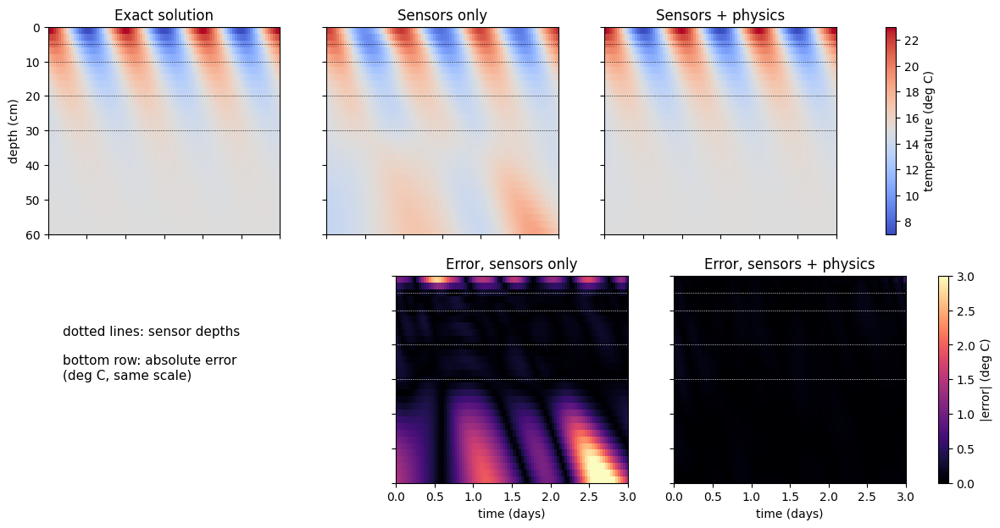

In [ ]:
shape = (len(GRID_Z), len(GRID_T))
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
panels = [(axes[0, 0], GRID_EXACT, "Exact solution"), (axes[0, 1], field_data, "Sensors only"),
          (axes[0, 2], field_pinn, "Sensors + physics")]
for ax, field, title in panels:
    img = ax.imshow(to_celsius(np.asarray(field).reshape(shape)), aspect="auto", origin="upper", cmap="coolwarm",
                    vmin=T_MEAN - AMP, vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    for z in sensor_depths:
        ax.axhline(100 * z, color="k", lw=0.6, ls=":")
fig.colorbar(img, ax=axes[0, :], label="temperature (deg C)")
axes[1, 0].axis("off")
axes[1, 0].text(0.05, 0.5, "dotted lines: sensor depths\n\nbottom row: absolute error\n(deg C, same scale)",
                transform=axes[1, 0].transAxes, fontsize=11)
for ax, field, title in ((axes[1, 1], field_data, "Error, sensors only"), (axes[1, 2], field_pinn, "Error, sensors + physics")):
    err_img = ax.imshow(AMP * np.abs(np.asarray(field) - GRID_EXACT).reshape(shape), aspect="auto", origin="upper",
                        cmap="magma", vmin=0, vmax=3, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    for z in sensor_depths:
        ax.axhline(100 * z, color="w", lw=0.6, ls=":")
fig.colorbar(err_img, ax=axes[1, 1:], label="|error| (deg C)")
for ax in axes[1, 1:]:
    ax.set_xlabel("time (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("depth (cm)")
plt.show()

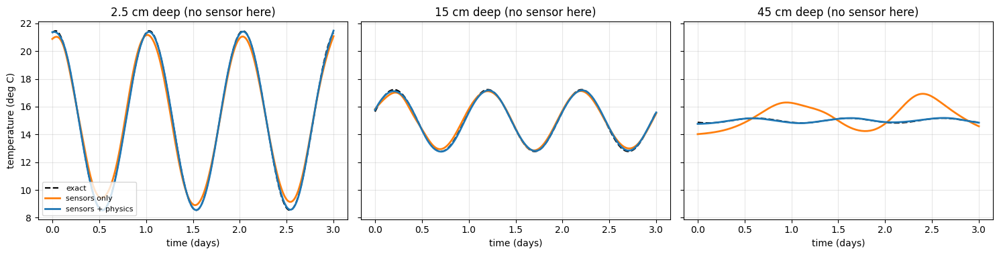

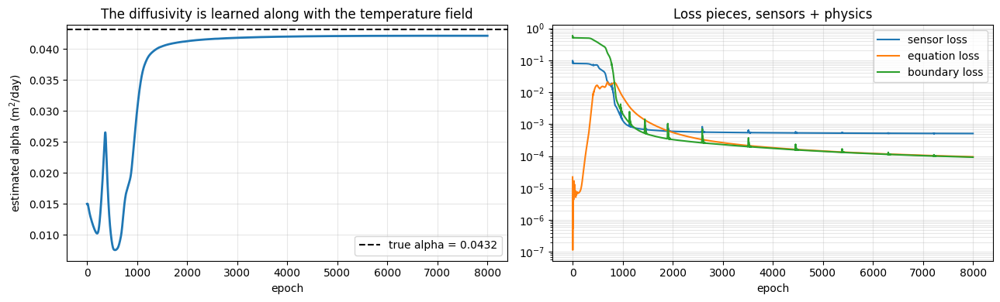

In [ ]:
t_line = np.linspace(0, T_MAX, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, z_cm in zip(axes, (2.5, 15, 45)):
    X_line = np.column_stack([np.full_like(t_line, z_cm / 100.0), t_line]) / np.array([Z_MAX, T_MAX])
    ax.plot(t_line, to_celsius(exact_theta(z_cm / 100.0, t_line)), "k--", lw=1.6, label="exact")
    ax.plot(t_line, to_celsius(forward_jets(params_data, X_line)[0].ravel()), color="tab:orange", lw=2, label="sensors only")
    ax.plot(t_line, to_celsius(forward_jets(params_pinn, X_line)[0].ravel()), color="tab:blue", lw=2, label="sensors + physics")
    ax.set_title(f"{z_cm} cm deep (no sensor here)")
    ax.set_xlabel("time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("temperature (deg C)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(alpha_hist, lw=2)
axes[0].axhline(ALPHA_TRUE, color="k", ls="--", label=f"true alpha = {ALPHA_TRUE:.4f}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("estimated alpha (m$^2$/day)")
axes[0].set_title("The diffusivity is learned along with the temperature field")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].semilogy(hist_pinn[:, 1], label="sensor loss")
axes[1].semilogy(hist_pinn[:, 2], label="equation loss")
axes[1].semilogy(hist_pinn[:, 3], label="boundary loss")
axes[1].set_xlabel("epoch")
axes[1].set_title("Loss pieces, sensors + physics")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

**What to notice.**

* Between the sensors (5 to 30 cm), both networks follow the readings. The sensors-only network can do that because it has data there.
* Above the shallowest sensor and below the deepest one, the sensors-only network has nothing to go on. Its error there is about 0.8 °C above 5 cm and about 1 °C below 30 cm, and it grows to several degrees in the bottom corner of the map. The physics network is held to the equation and the boundary conditions over the whole map. Its error is only 0.03 to 0.06 °C in those same regions, **far below the 0.2 °C noise of a single reading**.
* The physics network starts with a diffusivity that is far too low and corrects it within the first couple of thousand epochs.

## A9. How does the network's estimate compare with the classical methods?
On the same readings, here are all four estimates side by side, and then the network's error placed on the histograms from Setup (300 repeats with new noise for the classical methods).

method                    alpha (m^2/day)    error
amplitude method                  0.04140    -4.2%
phase method                      0.04337     0.4%
formula fit                       0.04223    -2.2%
sensors + physics (network)          0.04213    -2.5%
truth                             0.04320


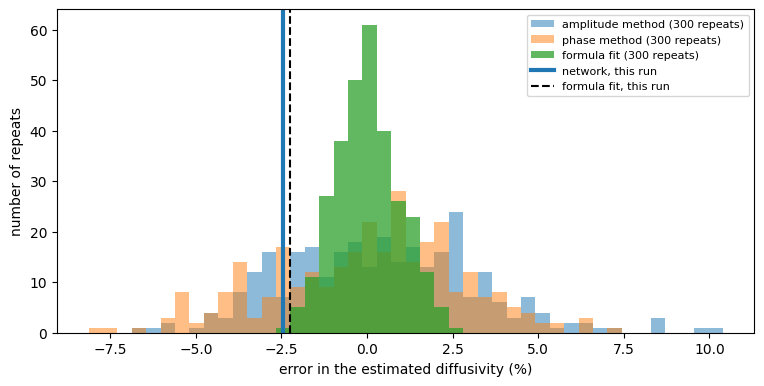

In [ ]:
print(f"{'method':24s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase),
                    ("formula fit", alpha_fit), ("sensors + physics (network)", alpha_hat)):
    print(f"{name:24s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':24s}{ALPHA_TRUE:17.5f}")

plt.figure(figsize=(9, 4.2))
bins = np.linspace(error_pct.min(), error_pct.max(), 45)
plt.hist(error_pct[:, 0], bins=bins, alpha=0.5, label="amplitude method (300 repeats)")
plt.hist(error_pct[:, 1], bins=bins, alpha=0.5, label="phase method (300 repeats)")
plt.hist(error_pct[:, 2], bins=bins, alpha=0.75, label="formula fit (300 repeats)")
plt.axvline(100 * (alpha_hat / ALPHA_TRUE - 1), color="tab:blue", lw=3, label="network, this run")
plt.axvline(100 * (alpha_fit / ALPHA_TRUE - 1), color="k", lw=1.5, ls="--", label="formula fit, this run")
plt.xlabel("error in the estimated diffusivity (%)")
plt.ylabel("number of repeats")
plt.legend(fontsize=8)
plt.show()

**Reading this honestly.** On these readings the network lands almost exactly where the formula fit does. That is no accident: both use all the data together with the same physics, so both reach about the best answer that these readings allow. In this run the readings happen to point about 2% low (the formula fit says so too), which is within the normal wander of the repeats. The simple amplitude and phase methods are noisier.

So in this clean problem, **the network does not beat the best classical method, it matches it.** The reason to bother is what comes next: it needs no exact formula, so it keeps working when the formula does not apply.

## A10. A heat-budget check
Background section 7 gave a balance that every correct solution must obey: the rate of change of the stored heat, $\frac{d}{dt}\int_0^L\theta\,dz$, equals $\alpha\,[\theta_z(L,t)-\theta_z(0,t)]$. We compute both sides from each network (the depth integral by the trapezoid rule, the time derivative by finite differences, and $\theta_z$ at the two ends from the network's own derivative output) and check how well they agree. We use the true $\alpha$ for the sensors-only network (it has none of its own), and the learned $\alpha$ for the physics network. The check does not use the exact answer.

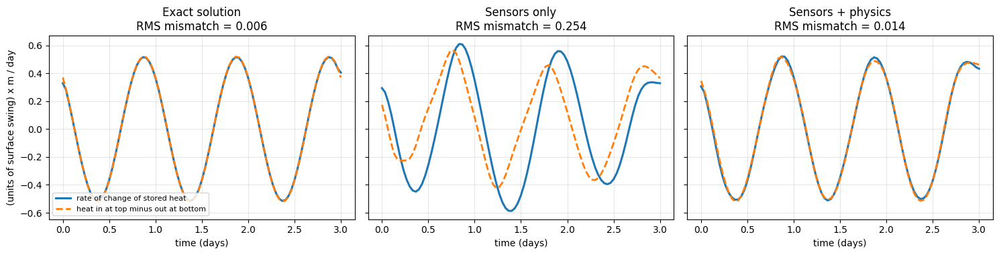

In [ ]:
z_dense = np.linspace(0.0, Z_MAX, 241)

def trapezoid(y, x):
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))

def stored_heat_and_flux(params, alpha):
    # left side (rate of change of stored heat) and right side (heat in at top minus out at bottom)
    Q = np.array([trapezoid(forward_jets(params, np.column_stack([z_dense, np.full_like(z_dense, t)]) / np.array([Z_MAX, T_MAX]))[0].ravel(), z_dense)
                  for t in GRID_T])
    top = forward_jets(params, np.column_stack([np.zeros_like(GRID_T), GRID_T]) / np.array([Z_MAX, T_MAX]))[1].ravel()
    bottom = forward_jets(params, np.column_stack([np.full_like(GRID_T, Z_MAX), GRID_T]) / np.array([Z_MAX, T_MAX]))[1].ravel()
    return np.gradient(Q, GRID_T), alpha * (bottom - top)

def exact_budget():
    d = d_true
    def z_derivative(z, t):
        phi = OMEGA * t - z / d
        return np.exp(-z / d) / d * (np.sin(phi) - np.cos(phi))
    Q = np.array([trapezoid(exact_theta(z_dense, t), z_dense) for t in GRID_T])
    return np.gradient(Q, GRID_T), ALPHA_TRUE * (z_derivative(Z_MAX, GRID_T) - z_derivative(0.0, GRID_T))

left_exact, right_exact = exact_budget()
left_data, right_data = stored_heat_and_flux(params_data, ALPHA_TRUE)
left_pinn, right_pinn = stored_heat_and_flux(params_pinn, alpha_hat)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, (left, right, title) in zip(axes, ((left_exact, right_exact, "Exact solution"),
                                           (left_data, right_data, "Sensors only"),
                                           (left_pinn, right_pinn, "Sensors + physics"))):
    ax.plot(GRID_T, left, lw=2.2, label="rate of change of stored heat")
    ax.plot(GRID_T, right, "--", lw=2, label="heat in at top minus out at bottom")
    ax.set_title(f"{title}\nRMS mismatch = {np.sqrt(np.mean((left - right) ** 2)):.3f}")
    ax.set_xlabel("time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("(units of surface swing) x m / day")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

The exact solution balances to within the accuracy of the finite differences (RMS mismatch 0.006). The physics network balances almost as well (0.014). The sensors-only network is only constrained where the sensors are, so its two sides disagree by about 40 times more (0.245), with the wrong size and the wrong timing. You could run this check on any model of soil temperature without knowing the true answer.

## A11. The training video and GIF
Now the animation. Left: the sensors-only network. Right: the network with physics, which also has to find the diffusivity. For each there is:

1. the depth–time temperature map the network currently believes in (dotted lines mark the sensors),
2. the temperature against depth at day 2, with the exact curve and the sensor readings at that moment,
3. a strip with the error against the exact solution, and for the physics network the diffusivity estimate against the truth.

`make_training_video` writes a GIF (always works) and an MP4 (needs `ffmpeg`).

In [ ]:
runs_video = [
    {"name": "Sensors only", "color": "tab:orange", "theta": snaps_data["theta"], "alpha": None, "rmse": snaps_data["rmse"]},
    {"name": "Sensors + physics", "color": "tab:blue", "theta": snaps_pinn["theta"], "alpha": snaps_pinn["alpha"], "rmse": snaps_pinn["rmse"]},
]
gif_path = MEDIA_DIR / "soil_heat_training.gif"
mp4_path = MEDIA_DIR / "soil_heat_training.mp4"

anim = make_training_video(snap_epochs, runs_video, mp4_path=mp4_path, gif_path=gif_path, fps=12)

saved GIF: media/soil_heat_training.gif  (2.1 MB)
saved MP4: media/soil_heat_training.mp4  (0.9 MB)


In [ ]:
# optional: build a GIF from the MP4 with ffmpeg (a colour palette is computed for cleaner colours)
convert_mp4_to_gif(mp4_path, MEDIA_DIR / "soil_heat_training_from_mp4.gif", fps=12, width=800)

converted media/soil_heat_training.mp4 -> media/soil_heat_training_from_mp4.gif  (1.7 MB)


PosixPath('media/soil_heat_training_from_mp4.gif')

Here is the GIF. (In Jupyter it plays inline. Elsewhere, open the file in the `media` folder.)

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(gif_path)))

**Results (GIF)**

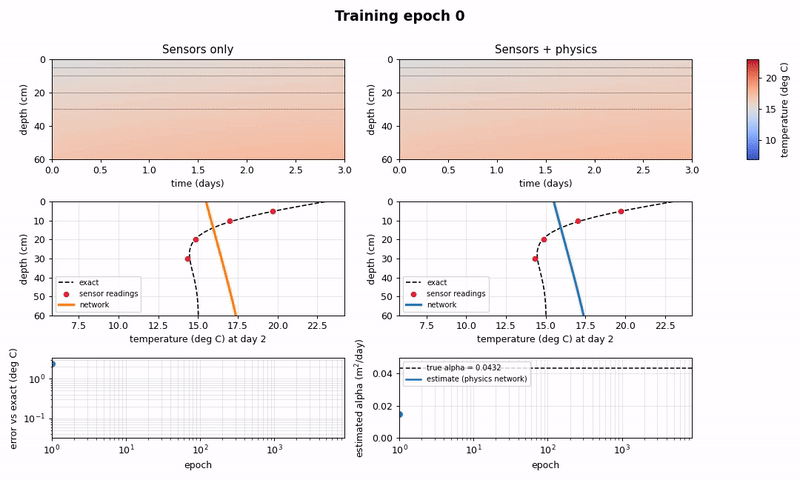

A still picture of a few moments, for places where animations do not play:

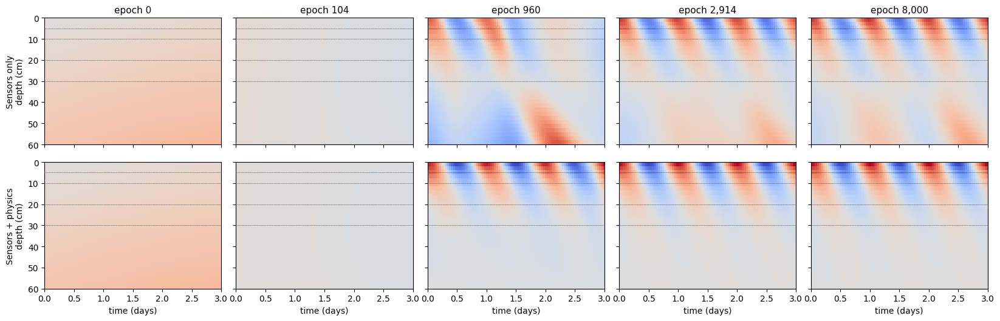

In [ ]:
snapshot_grid(snap_epochs, runs_video, picks=(0, 100, 1000, 3000, 8000))

And a slider to move through training by hand (Jupyter or Colab):

In [ ]:
scrub_epochs(snap_epochs, runs_video)

## A12. A harder test: a cloudy afternoon
*This section goes beyond the main experiment.*

So far the surface was a clean daily cosine, which has an exact solution. Real surfaces are messier. Here the surface temperature has a sharper afternoon peak (a second daily harmonic) and **a cloud that covers the sun for a couple of hours on day 2**, causing a sudden dip. There is no neat formula for this. The "truth" is computed with the Crank–Nicolson solver from Setup, starting from the soil's steady daily pattern. The four sensors read this truth with the same noise as before.

What changes for the methods?

* **Amplitude and phase methods** need a reference. We take the first daily harmonic of the **measured surface record** as the surface amplitude and phase.
* **A formula fit** is not possible. The classical way is to **fit with a solver**: try a diffusivity, run Crank–Nicolson, compare with the readings, and adjust. We do that too.
* **The network** needs no change at all, except that the surface record it is given is the messy one.

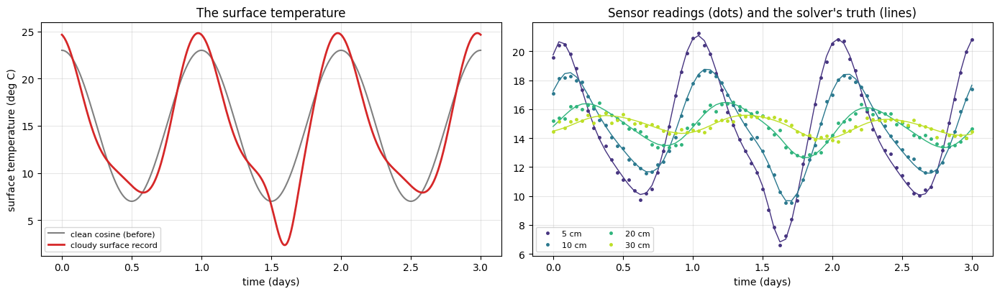

In [ ]:
def surface_cloudy(t):
    # sharper afternoon peak (second harmonic) and a cloud dip on day 2
    return np.cos(OMEGA * t) + 0.25 * np.cos(2 * OMEGA * t + 0.6) - 0.7 * np.exp(-((t - 1.6) / 0.1) ** 2)


z_c, t_c, field_c = fd_solve(ALPHA_TRUE, surface_cloudy, Z_MAX, T_MAX, theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
truth_c = RegularGridInterpolator((t_c, z_c), field_c)

pts = np.array([(t, z) for z in sensor_depths for t in sensor_times])
theta_clean_c = truth_c(pts).reshape(len(sensor_depths), len(sensor_times))
theta_matrix_c = theta_clean_c + noise_theta * np.random.default_rng(5).standard_normal(theta_clean_c.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(t_fine, to_celsius(np.cos(OMEGA * t_fine)), color="gray", lw=1.5, label="clean cosine (before)")
axes[0].plot(t_fine, to_celsius(surface_cloudy(t_fine)), color="tab:red", lw=2, label="cloudy surface record")
axes[0].set_xlabel("time (days)")
axes[0].set_ylabel("surface temperature (deg C)")
axes[0].set_title("The surface temperature")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
for i, (z, colour) in enumerate(zip(sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    axes[1].plot(sensor_times, to_celsius(theta_matrix_c[i]), ".", color=colour, ms=5, label=f"{int(100*z)} cm")
    axes[1].plot(sensor_times, to_celsius(theta_clean_c[i]), "-", color=colour, lw=1)
axes[1].set_xlabel("time (days)")
axes[1].set_title("Sensor readings (dots) and the solver's truth (lines)")
axes[1].legend(ncol=2, fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# classical estimates for the cloudy case: amplitude and phase relative to the surface record's first harmonic
t_rec = np.arange(0.0, T_MAX + 1e-9, 1.0 / 96.0)
surface_rec = surface_cloudy(t_rec)
_surface_coef = np.linalg.lstsq(np.column_stack([np.ones_like(t_rec), np.cos(OMEGA * t_rec), np.sin(OMEGA * t_rec)]),
                                surface_rec, rcond=None)[0]
surface_amp, surface_phase = np.hypot(_surface_coef[1], _surface_coef[2]), np.arctan2(_surface_coef[2], _surface_coef[1])

def classical_alphas_cloudy(theta_by_depth):
    amplitude, phase = amplitude_and_phase(theta_by_depth)
    ln_ratio = np.log(amplitude / surface_amp)
    delay = (phase - surface_phase + np.pi) % (2 * np.pi) - np.pi
    d_amp = -np.sum(sensor_depths**2) / np.sum(sensor_depths * ln_ratio)
    d_phase = np.sum(sensor_depths**2) / np.sum(sensor_depths * delay)
    return OMEGA * d_amp**2 / 2.0, OMEGA * d_phase**2 / 2.0

def solver_fit_alpha(theta_by_depth):
    # fit alpha by running the classical solver for each trial value
    def misfit(a):
        z_t, t_t, f_t = fd_solve(a, surface_cloudy, Z_MAX, T_MAX, dz=0.005, dt=0.004,
                                 theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
        interp = RegularGridInterpolator((t_t, z_t), f_t)
        return np.sum((theta_by_depth - interp(pts).reshape(theta_by_depth.shape)) ** 2)
    return minimize_scalar(misfit, bounds=(0.02, 0.08), method="bounded", options={"xatol": 1e-6}).x

alpha_amp_c, alpha_phase_c = classical_alphas_cloudy(theta_matrix_c)
alpha_solver_c = solver_fit_alpha(theta_matrix_c)

# 300 repeats of the harmonic methods with new noise
rng_c = np.random.default_rng(7)
rep_c = np.array([classical_alphas_cloudy(theta_clean_c + noise_theta * rng_c.standard_normal(theta_clean_c.shape))
                  for _ in range(300)])
err_c = 100 * (rep_c / ALPHA_TRUE - 1)
print(f"on perfectly clean readings, amplitude / phase method: {classical_alphas_cloudy(theta_clean_c)[0]:.4f} / "
      f"{classical_alphas_cloudy(theta_clean_c)[1]:.4f}   (truth {ALPHA_TRUE:.4f})")
print(f"over 300 noisy repeats: amplitude method mean {err_c[:,0].mean():.2f}% spread {err_c[:,0].std():.2f}%;  "
      f"phase method mean {err_c[:,1].mean():.2f}% spread {err_c[:,1].std():.2f}%")

on perfectly clean readings, amplitude / phase method: 0.0429 / 0.0438   (truth 0.0432)
over 300 noisy repeats: amplitude method mean -0.40% spread 2.59%;  phase method mean 1.29% spread 2.63%


In [ ]:
batch_c = build_batch(theta_sensors=theta_matrix_c.reshape(-1, 1), surface_function=surface_cloudy, n_boundary=300)
params_c, hist_c, alpha_hist_c, _ = train((1.0, 1.0, 1.0), learn_alpha=True, batch=batch_c, verbose=False)
alpha_hat_c = alpha_hist_c[-1]

ex_c = truth_c(np.column_stack([GRID_POINTS[:, 1], GRID_POINTS[:, 0]]))
field_c_net = forward_jets(params_c, GRID_X)[0].ravel()
print(f"{'method':32s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp_c), ("phase method", alpha_phase_c),
                    ("fit with the classical solver", alpha_solver_c), ("sensors + physics (network)", alpha_hat_c)):
    print(f"{name:32s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':32s}{ALPHA_TRUE:17.5f}")
print(f"\nnetwork temperature map: RMSE against the solver's truth = {AMP*rmse(field_c_net, ex_c):.3f} deg C")

method                            alpha (m^2/day)    error
amplitude method                          0.04121    -4.6%
phase method                              0.04387     1.6%
fit with the classical solver             0.04262    -1.4%
sensors + physics (network)               0.04222    -2.3%
truth                                     0.04320

network temperature map: RMSE against the solver's truth = 0.059 deg C


**What this shows.** The network recovers the diffusivity from the messy surface record (2.3% low) about as well as the classical solver fit does (1.4% low), with a single training run and no exact formula. Its temperature map matches the solver's to about 0.06 °C. The harmonic methods still work here too, because a two-hour cloud is a small disturbance to the daily wave: on clean readings they are off by only a percent or so. Their remaining problem is the noise, with the typical wander shown above.

So the honest summary is not "the network wins". It is that **the network handles the messy case with the same code and no special treatment**, while giving results comparable to the best classical approach, which here needs a solver to be run again and again.

---
## A13. Case study 2: the heat-shield tile

Now the spacecraft. The network is the same two-input network, with the **same hand-derived forward and backward passes** (A1 and A3). Only the loss changes, as described in background section 12.6: a known hot-face history, a zero-flux back face, a known start, and thermocouple readings. The diffusivity is unknown and starts from a wrong guess. The goal is to find it and, more to the point, to **predict the back-face temperature where nobody measured**.

We compare, as before:

* a network that sees **only the thermocouple readings**, and
* a network that also knows the heat equation and the boundary and initial conditions.

For the cheaper "sensors only" network we pass a batch with very few unused physics points, because they would carry zero weight anyway.

### A13.1 The tile loss and its gradients

A small extension of A2 and A3. The network works in scaled units, so its input scales are the tile thickness and the 60-minute window, which `forward_jets` now accepts as an optional `scales` argument (the soil case uses the defaults). There are five loss pieces (`lam = (lam_data, lam_boundary, lam_equation, lam_initial)`):

$$
\mathcal L=\lambda_{\text{data}}\overline{(\hat\theta-\theta_i)^2}+\lambda_{\text{PDE}}\overline{r^2}+\lambda_{\text{BC}}\Big[\overline{(\hat\theta-s)^2}_{z=0}+\overline{(L\hat\theta_z)^2}_{z=L}\Big]+\lambda_{\text{init}}\overline{\hat\theta^2}_{t=0},
\qquad r=\frac{\hat\theta_t-\alpha\hat\theta_{zz}}{0.1\ \text{per min}} .
$$

The new thing for the gradients is the back-face condition, which acts on the **depth-derivative output** $\hat\theta_z$. In step 1 of A3 it simply adds to $g_{\theta_z}$: $\;g_{\theta_z}\mathrel{+}=\lambda_{\text{BC}}\,\frac{2}{N_b}\,L^2\,\hat\theta_z$. Everything after step 1 is unchanged, because `backward_jets` already accepts a gradient for the depth derivative.

In [ ]:
TILE_SCALES = (TILE_L, TILE_TEND)        # input scales: depth and time
TILE_RES = 0.1                           # residual scale: 1 / (10 minutes)


def make_tile_batch(zt_colloc, zt_surface, surface_values, zt_back, zt_initial, zt_sensors, theta_sensors):
    # points are rows of (depth in m, time in minutes), stacked in this order and scaled for the network
    X = np.vstack([zt_colloc, zt_surface, zt_back, zt_initial, zt_sensors]) / np.array(TILE_SCALES)
    return {"X": X, "n_c": len(zt_colloc), "n_s": len(zt_surface), "n_b": len(zt_back), "n_i": len(zt_initial),
            "n_m": len(zt_sensors), "surface_values": surface_values, "theta_sensors": theta_sensors}


def tile_loss_and_grads(params, batch, lam, alpha, want_alpha_grad=False):
    lam_data, lam_bc, lam_pde, lam_init = lam
    nc, ns, nb, ni, nm = batch["n_c"], batch["n_s"], batch["n_b"], batch["n_i"], batch["n_m"]
    i_s, i_b, i_i, i_m = nc, nc + ns, nc + ns + nb, nc + ns + nb + ni
    theta, theta_z, theta_zz, theta_t, caches = forward_jets(params, batch["X"], TILE_SCALES)

    r = (theta_t[:nc] - alpha * theta_zz[:nc]) / TILE_RES
    r_surface = theta[i_s:i_s + ns] - batch["surface_values"]
    r_back = theta_z[i_b:i_b + nb] * TILE_L                  # zero-flux condition, scaled by the thickness
    r_init = theta[i_i:i_i + ni]
    r_data = theta[i_m:i_m + nm] - batch["theta_sensors"]

    l_pde, l_data, l_init = np.mean(r**2), np.mean(r_data**2), np.mean(r_init**2)
    l_bc = np.mean(r_surface**2) + np.mean(r_back**2)
    total = lam_pde * l_pde + lam_bc * l_bc + lam_init * l_init + lam_data * l_data

    g_theta, g_theta_z, g_theta_zz, g_theta_t = (np.zeros_like(theta) for _ in range(4))
    g_res = lam_pde * 2.0 / nc * r / TILE_RES
    g_theta_t[:nc] += g_res
    g_theta_zz[:nc] += -alpha * g_res
    g_theta[i_s:i_s + ns] += lam_bc * 2.0 / ns * r_surface
    g_theta_z[i_b:i_b + nb] += lam_bc * 2.0 / nb * r_back * TILE_L
    g_theta[i_i:i_i + ni] += lam_init * 2.0 / ni * r_init
    g_theta[i_m:i_m + nm] += lam_data * 2.0 / nm * r_data
    grads = backward_jets(params, caches, g_theta, g_theta_z, g_theta_zz, g_theta_t)

    grad_log_alpha = 0.0
    if want_alpha_grad:
        grad_log_alpha = float(np.mean(lam_pde * 2.0 * r * (-theta_zz[:nc] / TILE_RES))) * alpha
    return total, (l_data, l_pde, l_bc, l_init), grads, grad_log_alpha

### A13.2 Gradient check
The same finite-difference test as in A4, now for the tile loss, with unequal weights and a few points of each kind (including the zero-flux back-face points, which exercise the new gradient path).

In [ ]:
rng_t = np.random.default_rng(0)
chk_c = np.column_stack([rng_t.uniform(0, TILE_L, 8), rng_t.uniform(0, TILE_TEND, 8)])
chk_s = np.column_stack([np.zeros(4), np.linspace(0, TILE_TEND, 4)])
chk_b = np.column_stack([np.full(4, TILE_L), np.linspace(0, TILE_TEND, 4)])
chk_i = np.column_stack([np.linspace(0, TILE_L, 4), np.zeros(4)])
chk_tile_batch = make_tile_batch(chk_c, chk_s, reentry_pulse(chk_s[:, 1]).reshape(-1, 1), chk_b, chk_i,
                                 tile_zt_data[::90][:4], tile_theta_data[::90][:4])
chk_tile_params = init_params((2, 6, 6, 1), seed=1)
chk_tile_lam, chk_tile_alpha = (1.0, 2.0, 3.0, 4.0), 1.5e-5

_, _, analytic_t, grad_log_alpha_t = tile_loss_and_grads(chk_tile_params, chk_tile_batch, chk_tile_lam,
                                                         chk_tile_alpha, want_alpha_grad=True)
eps = 1e-6
worst_t = 0.0
for name in analytic_t:
    numeric = np.zeros_like(chk_tile_params[name])
    it = np.nditer(chk_tile_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = chk_tile_params[name][idx]
        chk_tile_params[name][idx] = old + eps
        up = tile_loss_and_grads(chk_tile_params, chk_tile_batch, chk_tile_lam, chk_tile_alpha)[0]
        chk_tile_params[name][idx] = old - eps
        down = tile_loss_and_grads(chk_tile_params, chk_tile_batch, chk_tile_lam, chk_tile_alpha)[0]
        chk_tile_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic_t[name]), 1e-12)
    worst_t = max(worst_t, np.max(np.abs(numeric - analytic_t[name]) / denom))
print(f"worst relative difference over all weights: {worst_t:.2e}")
up = tile_loss_and_grads(chk_tile_params, chk_tile_batch, chk_tile_lam, chk_tile_alpha * np.exp(eps))[0]
down = tile_loss_and_grads(chk_tile_params, chk_tile_batch, chk_tile_lam, chk_tile_alpha * np.exp(-eps))[0]
print(f"gradient for log(alpha): analytic = {grad_log_alpha_t:.8f}, numeric = {(up - down) / (2 * eps):.8f}")

worst relative difference over all weights: 9.44e-11
gradient for log(alpha): analytic = 0.00062977, numeric = 0.00062977


### A13.3 Training functions and evaluation helpers
The batch has 2500 random equation points over the whole depth–time rectangle, 300 times along the hot face and the back face, 100 depths at the start, and the thermocouple readings. The network is a bit larger than in the soil case (32 neurons per layer), because the heated layer is thin early on. The diffusivity starts at $1.2\times10^{-5}$ m²/min, half the true value. Learning rate and optimiser are the same as before.

In [ ]:
TILE_SIZES = (2, 32, 32, 32, 1)


def build_tile_batch(theta_sensors=None, n_colloc=2500, n_edge=300, n_init=100, seed=1):
    theta_sensors = tile_theta_data if theta_sensors is None else theta_sensors
    rng = np.random.default_rng(seed)
    zt_colloc = np.column_stack([rng.uniform(0, TILE_L, n_colloc), rng.uniform(0, TILE_TEND, n_colloc)])
    t_edge = np.linspace(0, TILE_TEND, n_edge)
    zt_surface = np.column_stack([np.zeros(n_edge), t_edge])
    zt_back = np.column_stack([np.full(n_edge, TILE_L), t_edge])
    zt_initial = np.column_stack([np.linspace(0, TILE_L, n_init), np.zeros(n_init)])
    return make_tile_batch(zt_colloc, zt_surface, reentry_pulse(t_edge).reshape(-1, 1), zt_back, zt_initial,
                           tile_zt_data, theta_sensors)


def train_tile(lam, epochs=8000, learn_alpha=True, alpha_start=1.2e-5, seed=0, batch=None, verbose=True, print_every=1000):
    batch = build_tile_batch() if batch is None else batch
    params = init_params(TILE_SIZES, seed=seed)
    trainable = dict(params)
    if learn_alpha:
        trainable["s"] = np.array([np.log(alpha_start)])
    opt = Adam(trainable)
    history, alpha_history = [], []
    for epoch in range(epochs):
        alpha = float(np.exp(trainable["s"][0])) if learn_alpha else TILE_ALPHA
        total, parts, grads, grad_log_alpha = tile_loss_and_grads(params, batch, lam, alpha, want_alpha_grad=learn_alpha)
        if learn_alpha:
            grads["s"] = np.array([grad_log_alpha])
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(trainable, grads, lr)
        history.append((total, *parts))
        alpha_history.append(alpha)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha:.3e}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.3e}  sensors = {parts[0]:.2e}  equation = {parts[1]:.2e}  "
                  f"boundary = {parts[2]:.2e}  initial = {parts[3]:.2e}{extra}")
    return params, np.array(history), np.array(alpha_history)


# evaluation grid: 36 depths x 121 times (every 30 s)
tile_grid_z = np.linspace(0.0, TILE_L, 36)
tile_grid_t = np.linspace(0.0, TILE_TEND, 121)
tile_grid_zz, tile_grid_tt = np.meshgrid(tile_grid_z, tile_grid_t, indexing="ij")
tile_grid_X = np.column_stack([tile_grid_zz.ravel(), tile_grid_tt.ravel()]) / np.array(TILE_SCALES)
tile_truth_grid = TILE_T0 + TILE_DT * tile_truth(np.column_stack([tile_grid_tt.ravel(), tile_grid_zz.ravel()])).reshape(tile_grid_zz.shape)


def tile_predict_field(params):
    theta = forward_jets(params, tile_grid_X, TILE_SCALES)[0].reshape(tile_grid_zz.shape)
    return TILE_T0 + TILE_DT * theta


def tile_predict_series(params, depth, minutes):
    X = np.column_stack([np.full_like(minutes, depth), minutes]) / np.array(TILE_SCALES)
    return TILE_T0 + TILE_DT * forward_jets(params, X, TILE_SCALES)[0].ravel()

### A13.4 Train the two networks
First the sensors-only network, then the physics network, which also has to find the diffusivity. The physics run takes a few minutes. Watch the diffusivity estimate climb from half the true value towards it.

In [ ]:
print("=== thermocouples only ===")
params_tile_data, hist_tile_data, _ = train_tile((1.0, 0.0, 0.0, 0.0), learn_alpha=False,
                                                 batch=build_tile_batch(n_colloc=20, n_edge=20, n_init=20),
                                                 print_every=2000)

print("\n=== thermocouples + physics, diffusivity unknown ===")
params_tile_pinn, hist_tile_pinn, alpha_hist_tile = train_tile((1.0, 1.0, 1.0, 1.0))
alpha_tile_hat = alpha_hist_tile[-1]

=== thermocouples only ===
epoch   2000/8000  total = 9.725e-05  sensors = 9.73e-05  equation = 1.58e-02  boundary = 6.17e-02  initial = 3.66e-03
epoch   4000/8000  total = 5.852e-05  sensors = 5.85e-05  equation = 3.54e-03  boundary = 2.34e-02  initial = 1.74e-03
epoch   6000/8000  total = 2.557e-05  sensors = 2.56e-05  equation = 1.28e-03  boundary = 5.15e-02  initial = 1.23e-03
epoch   8000/8000  total = 1.639e-05  sensors = 1.64e-05  equation = 1.80e-03  boundary = 5.15e-02  initial = 8.38e-04

=== thermocouples + physics, diffusivity unknown ===
epoch   1000/8000  total = 3.130e-03  sensors = 9.10e-05  equation = 7.09e-04  boundary = 2.22e-03  initial = 1.12e-04  alpha = 2.361e-05
epoch   2000/8000  total = 1.953e-03  sensors = 5.95e-05  equation = 4.90e-04  boundary = 1.33e-03  initial = 7.08e-05  alpha = 2.365e-05
epoch   3000/8000  total = 9.809e-04  sensors = 1.99e-05  equation = 3.24e-04  boundary = 6.11e-04  initial = 2.64e-05  alpha = 2.415e-05
epoch   4000/8000  total = 5.

### A13.5 Results: the diffusivity and the back-face prediction
The table compares the three ways of getting at the unmeasured back face. The error figures are in °C, split into the part between the thermocouples (1 to 4 cm) and the part deeper than 4 cm (which includes the back face, with no sensor).

In [ ]:
def tile_errors(field_C):
    err = np.asarray(field_C) - tile_truth_grid
    between = (tile_grid_z >= 0.01) & (tile_grid_z <= 0.04)
    return {"1-4 cm": np.sqrt(np.mean(err[between] ** 2)), "deeper than 4 cm": np.sqrt(np.mean(err[tile_grid_z > 0.04] ** 2)),
            "whole map": np.sqrt(np.mean(err ** 2))}


field_tile_data, field_tile_pinn = tile_predict_field(params_tile_data), tile_predict_field(params_tile_pinn)
back_data = tile_predict_series(params_tile_data, TILE_L, minutes_fine)
back_pinn = tile_predict_series(params_tile_pinn, TILE_L, minutes_fine)

z_s, t_s, f_s = fd_solve(alpha_tile_fit, reentry_pulse, TILE_L, TILE_TEND, dz=0.0005, dt=0.02, insulated_back=True)
back_fit = TILE_T0 + TILE_DT * np.interp(minutes_fine, t_s, f_s[:, -1])

e_d, e_p = tile_errors(field_tile_data), tile_errors(field_tile_pinn)
print(f"{'temperature error (deg C)':30s}{'thermocouples only':>20s}{'with physics':>15s}")
print(f"{'thermocouple noise':30s}{tile_noise_c:20.1f}{tile_noise_c:15.1f}")
for key in e_d:
    print(f"{key:30s}{e_d[key]:20.1f}{e_p[key]:15.1f}")

print(f"\n{'method':32s}{'alpha (m^2/min)':>16s}{'error':>8s}{'back-face peak':>16s}{'at minute':>11s}{'peak error':>12s}")
rows = (("truth", TILE_ALPHA, back_true), ("thermocouples only", None, back_data),
        ("fit with the classical solver", alpha_tile_fit, back_fit), ("thermocouples + physics (network)", alpha_tile_hat, back_pinn))
for name, a, series in rows:
    a_txt, e_txt = ("", "") if a is None else (f"{a:.3e}", f"{100*(a/TILE_ALPHA-1):.1f}%")
    print(f"{name:32s}{a_txt:>16s}{e_txt:>8s}{series.max():12.0f} C{minutes_fine[np.argmax(series)]:11.1f}{series.max() - back_true.max():10.0f} C")
print(f"\n(illustrative limit for the structure: {BOND_LIMIT:.0f} deg C;  true peak {back_true.max():.0f} deg C)")

temperature error (deg C)       thermocouples only   with physics
thermocouple noise                             3.0            3.0
1-4 cm                                         3.6            1.5
deeper than 4 cm                              30.3            3.8
whole map                                     25.3            3.5

method                           alpha (m^2/min)   error  back-face peak  at minute  peak error
truth                                  2.400e-05    0.0%         147 C       43.1         0 C
thermocouples only                                               153 C       36.1         6 C
fit with the classical solver          2.406e-05    0.2%         147 C       43.0         0 C
thermocouples + physics (network)       2.398e-05   -0.1%         138 C       43.1        -9 C

(illustrative limit for the structure: 175 deg C;  true peak 147 deg C)


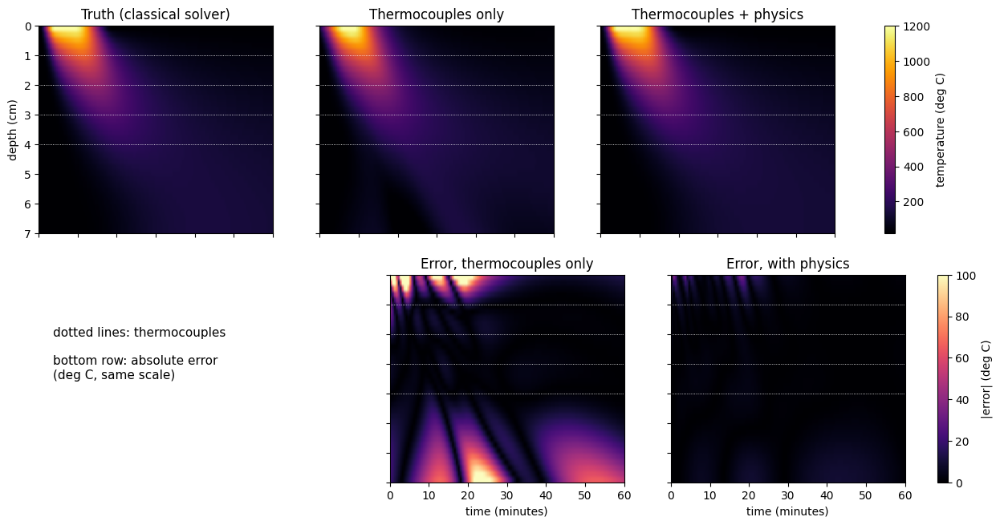

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.4), sharex=True, sharey=True)
for ax, field, title in ((axes[0, 0], tile_truth_grid, "Truth (classical solver)"), (axes[0, 1], field_tile_data, "Thermocouples only"),
                         (axes[0, 2], field_tile_pinn, "Thermocouples + physics")):
    img = ax.imshow(field, aspect="auto", origin="upper", cmap="inferno", vmin=TILE_T0, vmax=TILE_TPK,
                    extent=[0, TILE_TEND, 100 * TILE_L, 0])
    ax.set_title(title)
    for z in tile_sensor_depths:
        ax.axhline(100 * z, color="w", lw=0.6, ls=":")
fig.colorbar(img, ax=axes[0, :], label="temperature (deg C)")
axes[1, 0].axis("off")
axes[1, 0].text(0.05, 0.5, "dotted lines: thermocouples\n\nbottom row: absolute error\n(deg C, same scale)", transform=axes[1, 0].transAxes, fontsize=11)
for ax, field, title in ((axes[1, 1], field_tile_data, "Error, thermocouples only"), (axes[1, 2], field_tile_pinn, "Error, with physics")):
    err_img = ax.imshow(np.abs(field - tile_truth_grid), aspect="auto", origin="upper", cmap="magma", vmin=0, vmax=100,
                        extent=[0, TILE_TEND, 100 * TILE_L, 0])
    ax.set_title(title)
    ax.set_xlabel("time (minutes)")
    for z in tile_sensor_depths:
        ax.axhline(100 * z, color="w", lw=0.6, ls=":")
fig.colorbar(err_img, ax=axes[1, 1:], label="|error| (deg C)")
for ax in axes[:, 0]:
    ax.set_ylabel("depth (cm)")
plt.show()

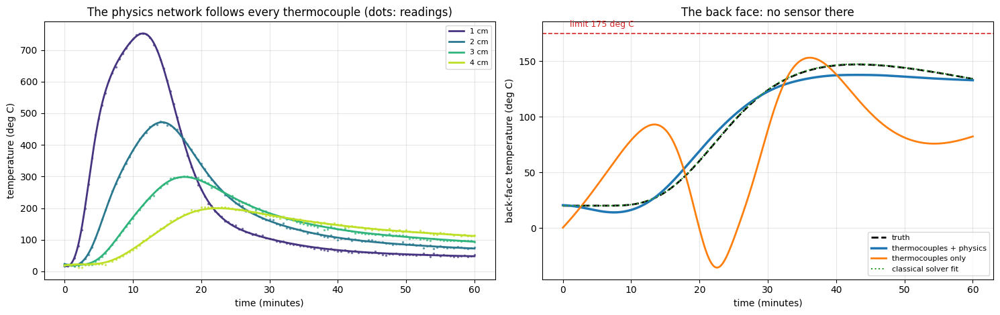

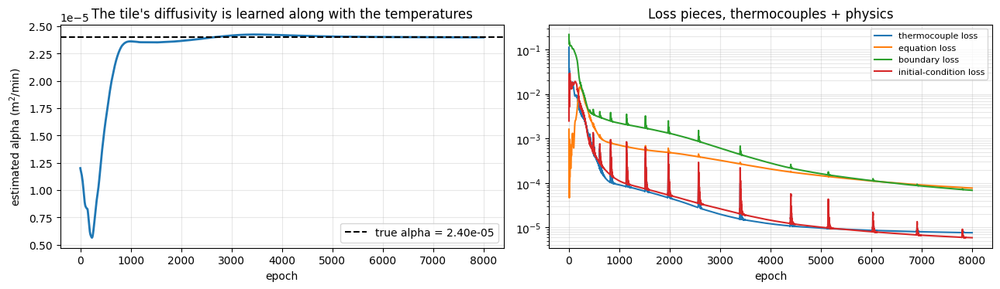

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for i, (z, colour) in enumerate(zip(tile_sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    axes[0].plot(tile_sensor_times, TILE_T0 + TILE_DT * tile_theta_matrix[i], ".", color=colour, ms=3, alpha=0.6)
    axes[0].plot(minutes_fine, tile_predict_series(params_tile_pinn, z, minutes_fine), color=colour, lw=2, label=f"{int(100*z)} cm")
axes[0].set_xlabel("time (minutes)")
axes[0].set_ylabel("temperature (deg C)")
axes[0].set_title("The physics network follows every thermocouple (dots: readings)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(minutes_fine, back_true, "k--", lw=2, label="truth")
axes[1].plot(minutes_fine, back_pinn, color="tab:blue", lw=2.5, label="thermocouples + physics")
axes[1].plot(minutes_fine, back_data, color="tab:orange", lw=2, label="thermocouples only")
axes[1].plot(minutes_fine, back_fit, color="tab:green", lw=1.5, ls=":", label="classical solver fit")
axes[1].axhline(BOND_LIMIT, color="tab:red", ls="--", lw=1.2)
axes[1].text(1, BOND_LIMIT + 6, f"limit {BOND_LIMIT:.0f} deg C", color="tab:red", fontsize=9)
axes[1].set_xlabel("time (minutes)")
axes[1].set_ylabel("back-face temperature (deg C)")
axes[1].set_title("The back face: no sensor there")
axes[1].legend(fontsize=8, loc="lower right")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(alpha_hist_tile, lw=2)
axes[0].axhline(TILE_ALPHA, color="k", ls="--", label=f"true alpha = {TILE_ALPHA:.2e}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("estimated alpha (m$^2$/min)")
axes[0].set_title("The tile's diffusivity is learned along with the temperatures")
axes[0].legend()
axes[0].grid(alpha=0.3)
for j, name in ((1, "thermocouple loss"), (2, "equation loss"), (3, "boundary loss"), (4, "initial-condition loss")):
    axes[1].semilogy(hist_tile_pinn[:, j], label=name)
axes[1].set_xlabel("epoch")
axes[1].set_title("Loss pieces, thermocouples + physics")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What to notice.**

* The thermocouples-only network matches the readings (its error between them, 3.6 °C, is about the noise level). Below the last thermocouple it has nothing to go on. Its error there is about 30 °C on average, and its back-face curve has the wrong shape: an invented early bump (it says the back face warms during the first 14 minutes, when in truth it does not), a dip to below the starting temperature, and a peak that comes about seven minutes too early. In this run the peak *value* happens to land near the truth, but that is luck. A different training run can be wrong in size as well, and the **time** of the peak, which tells the designer how long the structure stays hot, is wrong either way.
* The physics network is held to the equation, the known hot-face history, the insulated back and the known start. It finds the diffusivity to within 0.1%, follows every thermocouple, its whole temperature map is within 3.5 °C of the truth (about the noise level of a single thermocouple), and the back-face peak comes at the right time. The shape of the whole back-face curve is right.
* But it **under-predicts the back-face peak by about 9 °C** (138 against 147 °C). The thermocouples are at 1 to 4 cm and the back is at 7 cm, so the back face is an extrapolation, and a small error in the fitted field shows up there. Under-predicting a temperature is the **unsafe direction** when the question is a safety limit. The classical solver fit, which has the exact structure of the problem built in, gets the peak to within a degree, with a spread of a fraction of a degree in the repeat test. So in a real design you would still add a safety margin and cross-check the network against a solver. What the network offers is not point accuracy at the back face. It is that one training run gives the diffusivity and the whole temperature history without a solver loop, and keeps working when the problem is too messy for a solver.
* The loss plot shows small periodic spikes. They are Adam overshooting briefly, with the learning rate still fairly large, and the loss recovers within a few hundred epochs each time.

### A13.6 Energy check
Section 12.5 gave the heat balance for the insulated tile: the rate at which the tile's stored heat changes equals the heat flowing in at the hot face,
$$
\frac{d}{dt}\int_0^L\theta\,dz=-\alpha\,\theta_z(0,t).
$$
We compute both sides from each network (depth integral by the trapezoid rule, time derivative by finite differences, and $\theta_z$ at the hot face from the network's own derivative output). We use the true $\alpha$ for the thermocouples-only network (it has none of its own) and the learned one for the physics network. No exact answer is needed. For reference, the same check is applied to the classical solver.

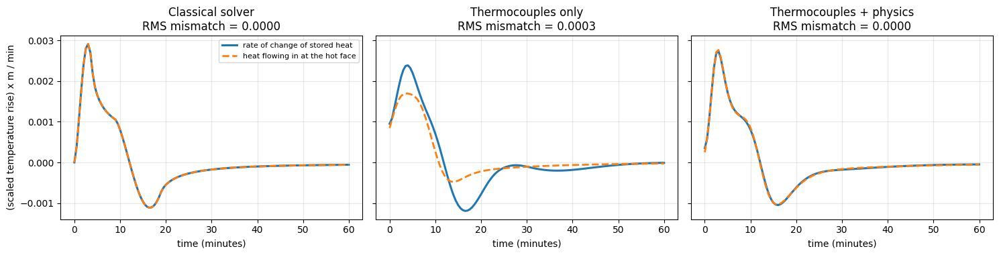

In [ ]:
z_dense_t = np.linspace(0.0, TILE_L, 141)

def trap(y, x):
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))

def tile_budget(params, alpha):
    Q = np.array([trap(forward_jets(params, np.column_stack([z_dense_t, np.full_like(z_dense_t, t)]) / np.array(TILE_SCALES), TILE_SCALES)[0].ravel(), z_dense_t)
                  for t in tile_grid_t])
    top = forward_jets(params, np.column_stack([np.zeros_like(tile_grid_t), tile_grid_t]) / np.array(TILE_SCALES), TILE_SCALES)[1].ravel()
    return np.gradient(Q, tile_grid_t), -alpha * top

# classical solver, as a reference for the size of the numerical error
Q_s = np.array([trap(f_row, z_s) for f_row in f_s])
t_idx = np.round(tile_grid_t / 0.02).astype(int)
dz_s = z_s[1] - z_s[0]
top_solver = (-3 * f_s[:, 0] + 4 * f_s[:, 1] - f_s[:, 2]) / (2 * dz_s)
left_solver, right_solver = np.gradient(Q_s, t_s)[t_idx], (-alpha_tile_fit * top_solver)[t_idx]
left_d, right_d = tile_budget(params_tile_data, TILE_ALPHA)
left_p, right_p = tile_budget(params_tile_pinn, alpha_tile_hat)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, (left, right, title) in zip(axes, ((left_solver, right_solver, "Classical solver"), (left_d, right_d, "Thermocouples only"),
                                           (left_p, right_p, "Thermocouples + physics"))):
    ax.plot(tile_grid_t, left, lw=2.2, label="rate of change of stored heat")
    ax.plot(tile_grid_t, right, "--", lw=2, label="heat flowing in at the hot face")
    ax.set_title(f"{title}\nRMS mismatch = {np.sqrt(np.mean((left - right) ** 2)):.4f}")
    ax.set_xlabel("time (minutes)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("(scaled temperature rise) x m / min")
axes[0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

The classical solver balances to within its own numerical error (the number in its title). The physics network balances much more closely than the thermocouples-only network, which is only constrained where the thermocouples are.

### A13.7 The re-entry video
Now the video, built from the networks' own predictions. It plays the whole hour of the re-entry. In every frame:

* **left**: a cross-section of the tile coloured by the physics network's temperature, with the plasma glowing above it (brighter when the hot face is hotter), the four thermocouples, and the aluminium structure below, which turns red if the network's back-face temperature goes over the limit,
* **middle**: temperature through the tile at that moment. The physics network (blue) against the truth (dashed), the thermocouples-only network (orange), and the thermocouple readings (red dots),
* **top right**: the hot face and the thermocouple histories,
* **bottom right**: the back face as it develops: the truth (dashed), the physics network (blue), the thermocouples-only network (orange), and the limit. The curves grow with time. A "heat soak" label appears when the surface has cooled but the back face is still rising.

`make_reentry_video` writes a GIF and an MP4, in the same way as the training video in the soil case.

In [ ]:
def make_reentry_video(minutes, z_grid, truth_C, pinn_C, data_C, mp4_path=None, gif_path=None,
                       fps=12, hold_frames=18, mp4_dpi=90, gif_dpi=55):
    # fields have shape (n_depths, n_times) in deg C, on z_grid (metres) x minutes
    nz, nt = truth_C.shape
    z_cm = 100.0 * np.asarray(z_grid)
    L_cm = 100.0 * TILE_L
    rows = [int(np.argmin(np.abs(z_grid - z))) for z in tile_sensor_depths]
    colours = plt.cm.viridis(np.linspace(0.15, 0.9, len(rows)))
    surface_C = TILE_T0 + TILE_DT * reentry_pulse(minutes)
    t_peak = minutes[int(np.argmax(truth_C[-1]))]
    sample_idx = [int(np.argmin(np.abs(tile_sensor_times - m))) for m in minutes]

    fig = plt.figure(figsize=(12, 7.2))
    gs = fig.add_gridspec(2, 3, width_ratios=[0.85, 1.2, 1.95], height_ratios=[1, 1])
    ax_tile, ax_prof = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[:, 1])
    ax_ts, ax_back = fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, 2])

    # left: the tile cross-section
    ax_tile.set_xlim(0, 1); ax_tile.set_ylim(L_cm + 3.4, -4.6); ax_tile.axis("off")
    plasma = plt.Rectangle((0.05, -4.4), 0.9, 4.4, lw=0)
    ax_tile.add_patch(plasma)
    tile_img = ax_tile.imshow(np.zeros((nz, 1)), extent=[0.05, 0.95, L_cm, 0], aspect="auto", cmap="inferno",
                              vmin=TILE_T0, vmax=TILE_TPK, interpolation="bilinear")
    structure = plt.Rectangle((0.05, L_cm), 0.9, 3.0, edgecolor="k")
    ax_tile.add_patch(structure)
    ax_tile.set_xlim(0, 1); ax_tile.set_ylim(L_cm + 3.4, -4.6)
    ax_tile.plot([0.12] * len(rows), 100 * tile_sensor_depths, "o", color="white", mec="k", ms=7)
    tc_texts = [ax_tile.text(0.2, 100 * z, "", color="white", fontsize=8, va="center") for z in tile_sensor_depths]
    surf_text = ax_tile.text(0.5, -2.2, "", ha="center", va="center", fontsize=10, fontweight="bold")
    back_text = ax_tile.text(0.5, L_cm + 1.5, "", ha="center", va="center", fontsize=9, fontweight="bold")
    ax_tile.text(0.5, -4.55, "plasma", ha="center", fontsize=8, color="gray")
    ax_tile.set_title("Heat shield, cross-section", fontsize=10)

    # middle: temperature through the tile
    ax_prof.plot([], [])
    line_true, = ax_prof.plot([], [], "k--", lw=1.4, label="truth")
    line_data, = ax_prof.plot([], [], color="tab:orange", lw=1.6, label="thermocouples-only network")
    line_net, = ax_prof.plot([], [], color="tab:blue", lw=2.6, label="network with physics")
    dots, = ax_prof.plot([], [], "o", color="crimson", ms=6, label="thermocouples")
    ax_prof.set_xlim(-200, 1200); ax_prof.set_ylim(L_cm, 0)
    ax_prof.set_xlabel("temperature (deg C)"); ax_prof.set_ylabel("depth into the tile (cm)")
    ax_prof.grid(alpha=0.3); ax_prof.legend(loc="lower right", fontsize=8)
    ax_prof.set_title("Temperature through the tile", fontsize=10)

    # top right: hot face and thermocouples
    ax_ts.plot(minutes, surface_C, color="gray", lw=1.5, label="hot face")
    ts_lines = [ax_ts.plot(minutes, pinn_C[r], color=c, lw=1.6, label=f"{int(100*z)} cm")[0]
                for r, c, z in zip(rows, colours, tile_sensor_depths)]
    cursor_ts = ax_ts.axvline(0, color="k", lw=1)
    ax_ts.set_ylabel("temperature (deg C)"); ax_ts.set_xlim(0, TILE_TEND); ax_ts.grid(alpha=0.3)
    ax_ts.legend(ncol=3, fontsize=7, loc="upper right"); ax_ts.set_title("Hot face and thermocouples", fontsize=10)

    # bottom right: the back face
    ax_back.axhline(BOND_LIMIT, color="tab:red", ls="--", lw=1.2)
    ax_back.text(1, BOND_LIMIT + 6, f"limit {BOND_LIMIT:.0f} deg C", color="tab:red", fontsize=8)
    ax_back.axvspan(0, 19, color="orange", alpha=0.12)
    ax_back.text(9.5, 0.02, "surface heating", ha="center", fontsize=7, color="darkorange", transform=ax_back.get_xaxis_transform())
    b_true, = ax_back.plot([], [], "k--", lw=1.8, label="truth")
    b_net, = ax_back.plot([], [], color="tab:blue", lw=2.6, label="network with physics")
    b_data, = ax_back.plot([], [], color="tab:orange", lw=1.8, label="thermocouples-only network")
    cursor_b = ax_back.axvline(0, color="k", lw=1)
    soak = ax_back.text(0.98, 0.06, "", transform=ax_back.transAxes, ha="right", fontsize=9, color="navy", fontweight="bold")
    ymax = max(300.0, float(np.max(data_C[-1])) * 1.1)
    ymin = max(min(0.0, float(np.min(data_C[-1])), float(np.min(pinn_C[-1]))) - 10.0, -150.0)
    ax_back.set_xlim(0, TILE_TEND); ax_back.set_ylim(ymin, ymax); ax_back.grid(alpha=0.3)
    ax_back.set_xlabel("time (minutes)"); ax_back.set_ylabel("back-face temperature (deg C)")
    ax_back.legend(loc="upper left", fontsize=7); ax_back.set_title("The back face (no sensor there)", fontsize=10)
    title = fig.suptitle("", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    def phase(t):
        if t < 4: return "surface heating up"
        if t < 9: return "peak heating"
        if t < 19: return "surface cooling"
        if t < t_peak: return "heat soak: surface cool, back face still rising"
        return "back face past its peak"

    frames = list(range(nt)) + [nt - 1] * hold_frames

    def update(i):
        t = minutes[i]
        s = (surface_C[i] - TILE_T0) / TILE_DT
        plasma.set_facecolor(plt.cm.YlOrRd(0.12 + 0.85 * s)); plasma.set_alpha(0.25 + 0.75 * s)
        tile_img.set_data(pinn_C[:, i][:, None])
        back_now = pinn_C[-1, i]
        structure.set_facecolor("#e57373" if back_now > BOND_LIMIT else "#9aa5b1")
        for txt, r in zip(tc_texts, rows):
            txt.set_text(f"{pinn_C[r, i]:.0f} C")
        surf_text.set_text(f"hot face {surface_C[i]:.0f} C")
        back_text.set_text(f"back face {back_now:.0f} C")
        line_true.set_data(truth_C[:, i], z_cm); line_net.set_data(pinn_C[:, i], z_cm)
        line_data.set_data(data_C[:, i], z_cm)
        dots.set_data(TILE_T0 + TILE_DT * tile_theta_matrix[:, sample_idx[i]], 100 * tile_sensor_depths)
        cursor_ts.set_xdata([t, t]); cursor_b.set_xdata([t, t])
        b_true.set_data(minutes[: i + 1], truth_C[-1, : i + 1])
        b_net.set_data(minutes[: i + 1], pinn_C[-1, : i + 1])
        b_data.set_data(minutes[: i + 1], data_C[-1, : i + 1])
        soak.set_text("HEAT SOAK" if 19 <= t < t_peak else "")
        title.set_text(f"Re-entry, minute {t:4.1f}:  {phase(t)}")
        return [tile_img, line_true, line_net, line_data, dots, cursor_ts, cursor_b, b_true, b_net, b_data, soak, title, plasma, structure]

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)
    if gif_path is not None:
        anim.save(str(gif_path), writer=animation.PillowWriter(fps=fps), dpi=gif_dpi)
        print(f"saved GIF: {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    if mp4_path is not None:
        ffmpeg = find_ffmpeg()
        if ffmpeg is None:
            print("ffmpeg was not found, so no MP4 was written. Install ffmpeg, or run: pip install imageio-ffmpeg")
        else:
            plt.rcParams["animation.ffmpeg_path"] = ffmpeg
            anim.save(str(mp4_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2200), dpi=mp4_dpi)
            print(f"saved MP4: {mp4_path}  ({Path(mp4_path).stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)
    return anim


reentry_gif = MEDIA_DIR / "reentry_heat_shield.gif"
reentry_mp4 = MEDIA_DIR / "reentry_heat_shield.mp4"
anim_reentry = make_reentry_video(tile_grid_t, tile_grid_z, tile_truth_grid, field_tile_pinn, field_tile_data,
                                  mp4_path=reentry_mp4, gif_path=reentry_gif, fps=12)

saved GIF: media/reentry_heat_shield.gif  (2.4 MB)
saved MP4: media/reentry_heat_shield.mp4  (0.9 MB)


Here is the GIF. (In Jupyter it plays inline. Elsewhere, open the file in the `media` folder.)

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(reentry_gif)))

**Results(GIF)**

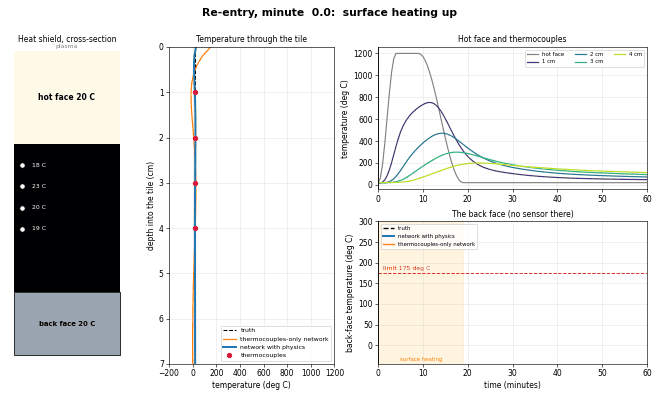

**Try it yourself (Jupyter or Colab).** A slider to move through the re-entry minute by minute. It shows the temperature through the tile (truth, the physics network and the thermocouples-only network, with the thermocouple readings) and the back-face history up to that moment.

In [ ]:
def scrub_reentry(minutes, z_grid, truth_C, pinn_C, data_C):
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets is not installed. Run: pip install ipywidgets")
        return
    sample_idx = [int(np.argmin(np.abs(tile_sensor_times - m))) for m in minutes]

    def draw(step):
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
        axes[0].plot(truth_C[:, step], 100 * z_grid, "k--", lw=1.4, label="truth")
        axes[0].plot(pinn_C[:, step], 100 * z_grid, color="tab:blue", lw=2.6, label="network with physics")
        axes[0].plot(data_C[:, step], 100 * z_grid, color="tab:orange", lw=1.6, label="thermocouples-only network")
        axes[0].plot(TILE_T0 + TILE_DT * tile_theta_matrix[:, sample_idx[step]], 100 * tile_sensor_depths, "o", color="crimson", label="thermocouples")
        axes[0].set_xlim(-50, 1300); axes[0].set_ylim(100 * TILE_L, 0)
        axes[0].set_xlabel("temperature (deg C)"); axes[0].set_ylabel("depth (cm)"); axes[0].grid(alpha=0.3)
        axes[0].legend(fontsize=8, loc="lower right")
        axes[1].plot(minutes, truth_C[-1], "k--", lw=1.4, alpha=0.5)
        axes[1].plot(minutes[: step + 1], truth_C[-1, : step + 1], "k--", lw=1.8, label="truth")
        axes[1].plot(minutes[: step + 1], pinn_C[-1, : step + 1], color="tab:blue", lw=2.6, label="network with physics")
        axes[1].plot(minutes[: step + 1], data_C[-1, : step + 1], color="tab:orange", lw=1.8, label="thermocouples-only network")
        axes[1].axhline(BOND_LIMIT, color="tab:red", ls="--")
        axes[1].set_xlim(0, TILE_TEND)
        axes[1].set_ylim(max(min(0.0, float(data_C[-1].min()), float(pinn_C[-1].min())) - 10.0, -150.0), max(300.0, float(data_C[-1].max()) * 1.1))
        axes[1].set_xlabel("time (minutes)"); axes[1].set_ylabel("back-face temperature (deg C)"); axes[1].grid(alpha=0.3)
        axes[1].legend(fontsize=8, loc="upper left")
        fig.suptitle(f"minute {minutes[step]:.1f}", fontweight="bold")
        plt.tight_layout()
        plt.show()

    slider = widgets.SelectionSlider(options=[(f"{m:.1f} min", i) for i, m in enumerate(minutes)], description="time",
                                     layout=widgets.Layout(width="85%"))
    widgets.interact(draw, step=slider)

scrub_reentry(tile_grid_t, tile_grid_z, tile_truth_grid, field_tile_pinn, field_tile_data)

**End of Part A.** Everything above used NumPy only: a network that returns its own time and depth derivatives, hand-derived gradients tested against finite differences (for the soil loss and the tile loss), an optimiser, two inverse problems (soil diffusivity and tile diffusivity), heat-budget checks, two videos, and a messy-surface test. Part B repeats the main experiments with PyTorch, where the derivative work is automatic.

---
---
# Part B: PyTorch and more advanced tools

The experiment is the same as in Part A: the same soil, the same four sensors, the same surface record, the same network shape and the same training schedule. What changes is who does the calculus.

1. **Automatic differentiation** gives $\hat\theta_t$, $\hat\theta_z$ and $\hat\theta_{zz}$. We call PyTorch's `autograd.grad` and never write the layer-by-layer formulas of background section 10.
2. **Backpropagation** for the whole loss, including both derivatives and the unknown diffusivity, is one call to `loss.backward()`. The long derivation of A3 collapses into a single line.

The first half (B1 to B8) rebuilds the experiment and the video in PyTorch. The second half (B9 to B11) adds L-BFGS polishing, the functional `torch.func` interface, and a study of **how many sensors you need**. B12 then does the **heat-shield tile** in PyTorch.

> **Setup needed.** Part B needs PyTorch (`pip install torch`; Colab has it). Run the **Setup** section first: the constants, sensor readings, classical estimators and helper functions come from there.
>
> **Runtime.** Differentiating twice through a network at 1500 points is slower than a plain forward pass. As a rough guide, the whole of Part B takes somewhere around 15 to 25 minutes on a laptop CPU.
>
> **Random numbers.** PyTorch draws different random numbers from NumPy, so the starting weights differ from Part A. Expect results close to, but not identical with, Part A.

## B1. Imports and random seed

In [ ]:
import copy
import torch
import torch.nn as nn

torch.manual_seed(0)

## B2. Tensors
The sensor readings, the surface record, the collocation points and the evaluation grid from Setup and Part A, as `float32` tensors with one row per point. Depth and time are kept as separate columns, because we will differentiate with respect to each one separately.

In [ ]:
def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)

# sensor readings
z_m_t, t_m_t, theta_m_t = to_tensor(zt_data[:, 0:1]), to_tensor(zt_data[:, 1:2]), to_tensor(theta_data)

# surface (z = 0) and deep (z = Z_MAX) boundary points
t_edge = np.linspace(0.0, T_MAX, 150).reshape(-1, 1)
t_s_t = to_tensor(t_edge)
z_s_t = torch.zeros_like(t_s_t)
theta_s_t = torch.cos(OMEGA * t_s_t)                  # the surface record: a clean daily cosine
z_d_t = torch.full_like(t_s_t, Z_MAX)
t_d_t = t_s_t.clone()

# 1500 random points over the whole depth-time rectangle, where the equation is checked
gen = torch.Generator().manual_seed(1)
z_c_t = torch.rand(1500, 1, generator=gen) * Z_MAX
t_c_t = torch.rand(1500, 1, generator=gen) * T_MAX

# evaluation grid
grid_z_t, grid_t_t = to_tensor(GRID_POINTS[:, 0:1]), to_tensor(GRID_POINTS[:, 1:2])
print(z_m_t.shape, z_c_t.shape, grid_z_t.shape)

torch.Size([292, 1]) torch.Size([1500, 1]) torch.Size([2821, 1])


## B3. The network
A fully connected network, 2 → 24 → 24 → 24 → 1 with $\tanh$, Xavier-uniform weights and zero biases. Its `forward` method takes depth and time as two separate columns, scales them (dividing by the depth and time scales, which default to `Z_MAX` and `T_MAX`, and can be changed, as we do for the tile in B12) and joins them into the two inputs. Because the scaling is *inside* the network, derivatives taken with respect to the physical depth and time come out right automatically.

In [ ]:
class HeatPINN(nn.Module):
    def __init__(self, hidden=(24, 24, 24), z_scale=Z_MAX, t_scale=T_MAX):
        super().__init__()
        self.z_scale, self.t_scale = z_scale, t_scale
        sizes = [2, *hidden, 1]
        layers = []
        for i in range(len(sizes) - 1):
            linear = nn.Linear(sizes[i], sizes[i + 1])
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)
            layers.append(linear)
            if i < len(sizes) - 2:
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)

    def forward(self, z, t):
        # z, t: columns of shape (N, 1), in physical units
        return self.net(torch.cat([z / self.z_scale, t / self.t_scale], dim=1))

## B4. Differentiating with autograd
`torch.autograd.grad(y, x, ...)` returns $\partial y/\partial x$ for every entry. We call it three times: for $\hat\theta_t$, for $\hat\theta_z$, and again on $\hat\theta_z$ to get $\hat\theta_{zz}$. As before, `create_graph=True` keeps the record needed to differentiate again and to differentiate the loss with respect to the weights. The residual is scaled by $\omega$ exactly as in background section 9.

In [ ]:
def grad(y, x):
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]


def pde_residual(model, z, t, alpha):
    z = z.clone().requires_grad_(True)
    t = t.clone().requires_grad_(True)
    theta = model(z, t)
    theta_t = grad(theta, t)             # rate of change in time
    theta_z = grad(theta, z)             # slope in depth
    theta_zz = grad(theta_z, z)          # curvature in depth
    return (theta_t - alpha * theta_zz) / OMEGA

## B5. The loss pieces
The same three pieces as in Part A: the sensors, the equation at the collocation points, and the boundaries (surface record on top, steady deep value at the bottom). The function can be given a different set of sensor readings, which we use in B11.

In [ ]:
def heat_losses(model, alpha, data=None):
    z_m, t_m, th_m = (z_m_t, t_m_t, theta_m_t) if data is None else data
    l_data = torch.mean((model(z_m, t_m) - th_m) ** 2)
    l_pde = torch.mean(pde_residual(model, z_c_t, t_c_t, alpha) ** 2)
    l_bc = torch.mean((model(z_s_t, t_s_t) - theta_s_t) ** 2) + torch.mean(model(z_d_t, t_d_t) ** 2)
    return l_data, l_pde, l_bc

## B6. Training
As in Part A, one function trains either network: `lam = (lam_data, lam_bc, lam_pde)`, so `(1, 0, 0)` is the sensors-only network and `(1, 1, 1)` with `learn_alpha=True` is the physics network. The diffusivity is held as its **logarithm** in an `nn.Parameter`, so it stays positive and autograd works out its gradient on its own. In A3 we derived that gradient by hand, and it is the same quantity. The learning rate falls from $3\times10^{-3}$ to $10^{-4}$ with `ExponentialLR`.

In [ ]:
EPOCHS = 8000
LR_START, LR_END = 3e-3, 1e-4


def train_torch(lam, epochs=EPOCHS, learn_alpha=False, alpha_start=0.015, seed=0, data=None,
                snapshot_epochs=None, verbose=True, print_every=1000):
    torch.manual_seed(seed)
    model = HeatPINN()
    params = list(model.parameters())
    log_alpha = None
    if learn_alpha:
        log_alpha = nn.Parameter(torch.log(torch.tensor(float(alpha_start))))
        params.append(log_alpha)
    optimizer = torch.optim.Adam(params, lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, alpha_history = [], []
    snap_theta, snap_alpha, snap_rmse = [], [], []
    for epoch in range(epochs + 1):
        alpha_value = torch.exp(log_alpha) if learn_alpha else ALPHA_TRUE
        alpha_now = alpha_value.item() if learn_alpha else ALPHA_TRUE
        if epoch in snap_set:
            with torch.no_grad():
                field = model(grid_z_t, grid_t_t).numpy().ravel()
            snap_theta.append(field.copy())
            snap_alpha.append(alpha_now)
            snap_rmse.append(AMP * rmse(field, GRID_EXACT))
        if epoch == epochs:
            break
        optimizer.zero_grad()
        z_m, t_m, th_m = (z_m_t, t_m_t, theta_m_t) if data is None else data
        l_data = torch.mean((model(z_m, t_m) - th_m) ** 2)
        l_pde = torch.mean(pde_residual(model, z_c_t, t_c_t, alpha_value) ** 2) if lam[2] > 0 else torch.zeros(())
        l_bc = (torch.mean((model(z_s_t, t_s_t) - theta_s_t) ** 2) + torch.mean(model(z_d_t, t_d_t) ** 2)
                if lam[1] > 0 else torch.zeros(()))
        total = lam[0] * l_data + lam[1] * l_bc + lam[2] * l_pde
        total.backward()
        optimizer.step()
        scheduler.step()
        history.append([total.item(), l_data.item(), l_pde.item(), l_bc.item()])
        alpha_history.append(alpha_now)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha_now:.5f}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.3e}  sensors = {l_data.item():.2e}  "
                  f"equation = {l_pde.item():.2e}  boundary = {l_bc.item():.2e}{extra}")
    snaps = {"theta": np.array(snap_theta), "alpha": np.array(snap_alpha) if learn_alpha else None,
             "rmse": np.array(snap_rmse)}
    return model, log_alpha, np.array(history), np.array(alpha_history), snaps


def predict_grid(model):
    with torch.no_grad():
        return model(grid_z_t, grid_t_t).numpy().ravel()

## B7. Train both networks and compare
The same recipe as A7: a sensors-only network and a physics network that has to find $\alpha$ from a wrong starting guess of 0.015. The error table splits the depth range as in A8.

In [ ]:
snap_epochs = make_snapshot_epochs(EPOCHS)

print("=== sensors only ===")
model_data, _, hist_data_t, _, snaps_data_t = train_torch((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== sensors + physics, diffusivity unknown ===")
model_pinn, log_alpha_pinn, hist_pinn_t, alpha_hist_t, snaps_pinn_t = train_torch(
    (1.0, 1.0, 1.0), learn_alpha=True, snapshot_epochs=snap_epochs)
alpha_hat_t = alpha_hist_t[-1]

=== sensors only ===
epoch   1000/8000  total = 4.449e-02  sensors = 4.45e-02  equation = 0.00e+00  boundary = 0.00e+00
epoch   2000/8000  total = 7.792e-04  sensors = 7.79e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   3000/8000  total = 5.314e-04  sensors = 5.31e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   4000/8000  total = 4.947e-04  sensors = 4.95e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   5000/8000  total = 4.811e-04  sensors = 4.81e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   6000/8000  total = 4.733e-04  sensors = 4.73e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   7000/8000  total = 4.678e-04  sensors = 4.68e-04  equation = 0.00e+00  boundary = 0.00e+00
epoch   8000/8000  total = 4.635e-04  sensors = 4.64e-04  equation = 0.00e+00  boundary = 0.00e+00

=== sensors + physics, diffusivity unknown ===
epoch   1000/8000  total = 2.448e-01  sensors = 2.68e-02  equation = 2.29e-02  boundary = 1.95e-01  alpha = 0.00294
epoch   2000/8000  tota

error vs exact (deg C)        sensors only  sensors + physics
sensor noise (for reference)          0.20               0.20
sensor depths (5-30 cm)              0.096              0.075
above 5 cm                           0.806              0.111
below 30 cm                          0.927              0.051
whole map                            0.695              0.069

estimated diffusivity: 0.04170 m^2/day   (true 0.04320, error -3.5%)

method                        alpha (m^2/day)    error
amplitude method                      0.04140    -4.2%
phase method                          0.04337     0.4%
formula fit                           0.04223    -2.2%
sensors + physics (PyTorch)           0.04170    -3.5%


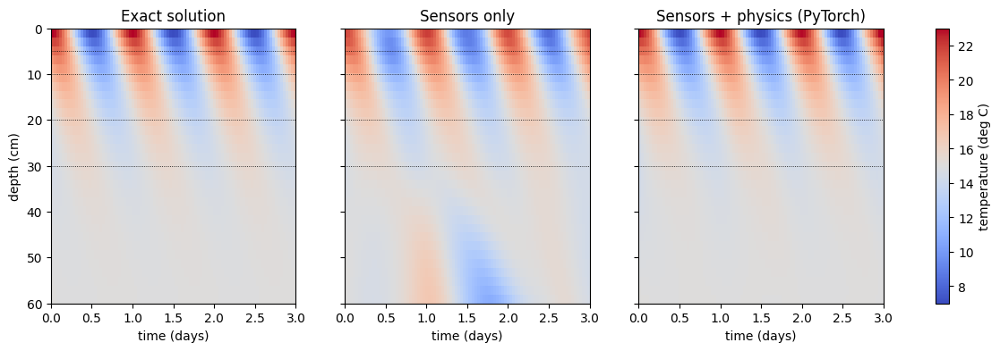

In [ ]:
def field_errors_torch(theta_flat):
    shape = (len(GRID_Z), len(GRID_T))
    err = AMP * (np.asarray(theta_flat).reshape(shape) - GRID_EXACT.reshape(shape))
    band = (GRID_Z >= 0.05) & (GRID_Z <= 0.30)
    return {"sensor depths (5-30 cm)": np.sqrt(np.mean(err[band] ** 2)),
            "above 5 cm": np.sqrt(np.mean(err[GRID_Z < 0.05] ** 2)),
            "below 30 cm": np.sqrt(np.mean(err[GRID_Z > 0.30] ** 2)),
            "whole map": np.sqrt(np.mean(err ** 2))}

e_data_t = field_errors_torch(predict_grid(model_data))
e_pinn_t = field_errors_torch(predict_grid(model_pinn))
print(f"{'error vs exact (deg C)':28s}{'sensors only':>14s}{'sensors + physics':>19s}")
print(f"{'sensor noise (for reference)':28s}{noise_celsius:14.2f}{noise_celsius:19.2f}")
for key in e_data_t:
    print(f"{key:28s}{e_data_t[key]:14.3f}{e_pinn_t[key]:19.3f}")
print(f"\nestimated diffusivity: {alpha_hat_t:.5f} m^2/day   (true {ALPHA_TRUE:.5f}, error {100*(alpha_hat_t/ALPHA_TRUE-1):.1f}%)")

print(f"\n{'method':28s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase),
                    ("formula fit", alpha_fit), ("sensors + physics (PyTorch)", alpha_hat_t)):
    print(f"{name:28s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")

shape = (len(GRID_Z), len(GRID_T))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, field, title in ((axes[0], GRID_EXACT, "Exact solution"), (axes[1], predict_grid(model_data), "Sensors only"),
                         (axes[2], predict_grid(model_pinn), "Sensors + physics (PyTorch)")):
    img = ax.imshow(to_celsius(np.asarray(field).reshape(shape)), aspect="auto", origin="upper", cmap="coolwarm",
                    vmin=T_MEAN - AMP, vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    ax.set_xlabel("time (days)")
    for z in sensor_depths:
        ax.axhline(100 * z, color="k", lw=0.6, ls=":")
axes[0].set_ylabel("depth (cm)")
fig.colorbar(img, ax=axes, label="temperature (deg C)")
plt.show()

The pattern to look for is the one from Part A: both networks follow the readings between the sensors, the sensors-only network goes wrong above the first sensor and below the last, and the physics network stays close to the truth everywhere and finds a diffusivity close to the true value. The exact numbers differ a little from Part A, because the starting weights are different and PyTorch works in 32-bit numbers where our NumPy code used 64-bit ones.

## B8. The training video again, from the PyTorch run
The same helper builds the animation. The files get a `_pytorch` suffix.

In [ ]:
runs_video_t = [
    {"name": "Sensors only", "color": "tab:orange", "theta": snaps_data_t["theta"], "alpha": None, "rmse": snaps_data_t["rmse"]},
    {"name": "Sensors + physics", "color": "tab:blue", "theta": snaps_pinn_t["theta"], "alpha": snaps_pinn_t["alpha"], "rmse": snaps_pinn_t["rmse"]},
]
gif_path_t = MEDIA_DIR / "soil_heat_training_pytorch.gif"
mp4_path_t = MEDIA_DIR / "soil_heat_training_pytorch.mp4"

anim_t = make_training_video(snap_epochs, runs_video_t, mp4_path=mp4_path_t, gif_path=gif_path_t, fps=12)

from IPython.display import Image, display
display(Image(filename=str(gif_path_t)))

**Result (GIF)**

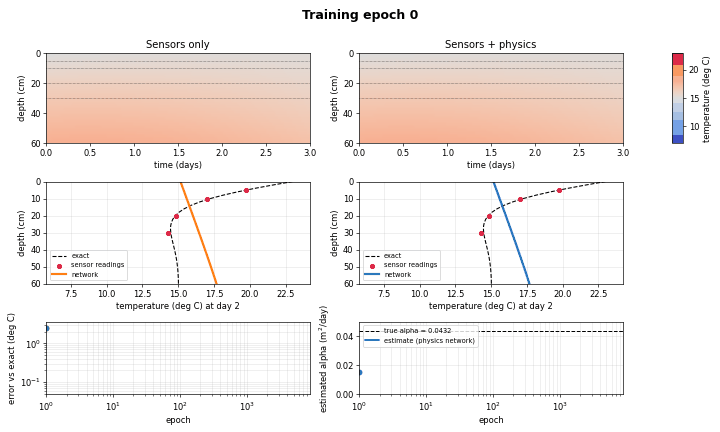

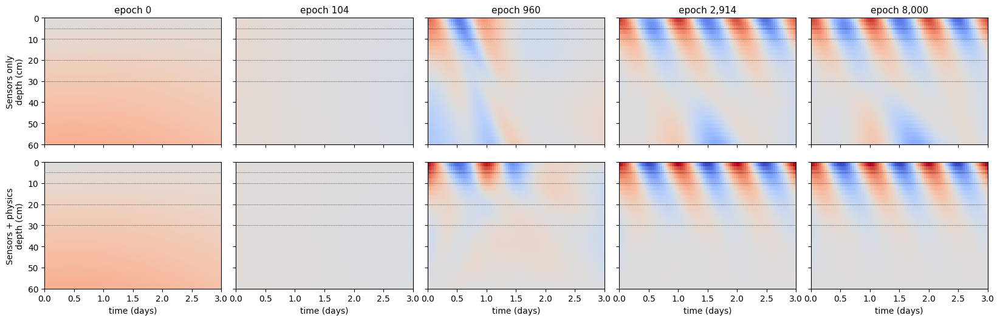

In [ ]:
snapshot_grid(snap_epochs, runs_video_t, picks=(0, 100, 1000, 3000, 8000))

In [ ]:
scrub_epochs(snap_epochs, runs_video_t)

---
## Advanced additions

Everything below goes beyond the basic experiment.

## B9. Polishing with L-BFGS
Adam is steady but slow to settle. **L-BFGS** builds a rough picture of how the loss curves from the last several gradients and takes larger, better-aimed steps (Liu and Nocedal, 1989). A common recipe is Adam first and L-BFGS to finish. Here it polishes both the network weights and the diffusivity together.

PyTorch's L-BFGS needs a **closure**, a function that recomputes the loss and its gradients on demand. It prefers 64-bit numbers, and our model is 32-bit, so progress can stall or occasionally give non-finite values. The cell checks for that and keeps the Adam result if it happens. We run at most 200 iterations to keep the time reasonable.

In [ ]:
model_lbfgs = copy.deepcopy(model_pinn)
log_alpha_lbfgs = nn.Parameter(log_alpha_pinn.detach().clone())
lbfgs = torch.optim.LBFGS(list(model_lbfgs.parameters()) + [log_alpha_lbfgs], lr=1.0, max_iter=200,
                          history_size=50, tolerance_grad=1e-12, tolerance_change=1e-15,
                          line_search_fn="strong_wolfe")

def closure():
    lbfgs.zero_grad()
    l_data, l_pde, l_bc = heat_losses(model_lbfgs, torch.exp(log_alpha_lbfgs))
    loss = l_data + l_pde + l_bc
    loss.backward()
    return loss

before_err = field_errors_torch(predict_grid(model_pinn))["whole map"]
before_alpha = torch.exp(log_alpha_pinn).item()
lbfgs.step(closure)
after_field = predict_grid(model_lbfgs)

if np.isfinite(after_field).all():
    print(f"whole-map error  before L-BFGS: {before_err:.4f} deg C   after: {field_errors_torch(after_field)['whole map']:.4f} deg C")
    print(f"alpha estimate   before L-BFGS: {before_alpha:.5f}   after: {torch.exp(log_alpha_lbfgs).item():.5f}   (true {ALPHA_TRUE:.5f})")
else:
    print("L-BFGS produced non-finite values in 32-bit arithmetic; keeping the Adam result.")

whole-map error  before L-BFGS: 0.0692 deg C   after: 0.0544 deg C
alpha estimate   before L-BFGS: 0.04170   after: 0.04171   (true 0.04320)


Do not expect a dramatic change. The readings are noisy, so the limit on the diffusivity estimate is the noise in the data and not the optimiser. L-BFGS helps more when the data are clean or when you solve an equation with no data at all (as in the Blasius notebook).

## B10. Derivatives with `torch.func`
In B4 we called `autograd.grad` three times. The functional interface `torch.func` works differently: write a function for a **single** point, then ask for its derivatives. `jacrev(f, argnums=1)` differentiates with respect to the second argument (time), and `jacrev(jacrev(f, argnums=0), argnums=0)` differentiates twice with respect to the first (depth). `vmap` applies the result to a whole batch. This style is common in more advanced code, and it extends cleanly to several inputs and mixed derivatives. Below, the time-derivative and second depth-derivative of the trained network are computed both ways and compared.

In [ ]:
from torch.func import vmap, jacrev

def theta_scalar(z, t):
    # network output for one point: scalars in, scalar out
    return model_pinn(z.reshape(1, 1), t.reshape(1, 1)).reshape(())

d_dt = vmap(jacrev(theta_scalar, argnums=1))
d2_dz2 = vmap(jacrev(jacrev(theta_scalar, argnums=0), argnums=0))

z_chk = torch.linspace(0.02, 0.55, 9)
t_chk = torch.linspace(0.1, 2.9, 9)
theta_t_func, theta_zz_func = d_dt(z_chk, t_chk), d2_dz2(z_chk, t_chk)

z_ag = z_chk.reshape(-1, 1).clone().requires_grad_(True)
t_ag = t_chk.reshape(-1, 1).clone().requires_grad_(True)
theta_ag = model_pinn(z_ag, t_ag)
theta_t_ag = grad(theta_ag, t_ag)
theta_zz_ag = grad(grad(theta_ag, z_ag), z_ag)

print("largest difference in theta_t: ", float((theta_t_func - theta_t_ag.reshape(-1)).abs().max()))
print("largest difference in theta_zz:", float((theta_zz_func - theta_zz_ag.reshape(-1)).abs().max()))

largest difference in theta_t:  0.0
largest difference in theta_zz: 0.0


/tmp/ipykernel_68008/3539246086.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("largest difference in theta_t: ", float((theta_t_func - theta_t_ag.reshape(-1)).abs().max()))


The two interfaces agree up to rounding.

## B11. How many sensors do you need?
The most practical question for anyone who wants to bury sensors. We train the physics network, with the diffusivity unknown, using **different subsets** of the sensors: only the 10 cm sensor, the 5 and 10 cm pair, and all four. Each run is 5000 epochs, shorter than the main run to keep the time reasonable, so the numbers are not directly comparable with B7. Where the classical amplitude and phase methods can be applied to the same subset, we show them too.

sensors          network  amplitude    phase   map error (deg C)      (true alpha = 0.0432)
10 cm only        0.0422     0.0418   0.0428               0.198
5 and 10 cm       0.0420     0.0419   0.0426               0.199
all four          0.0397     0.0414   0.0434               0.091


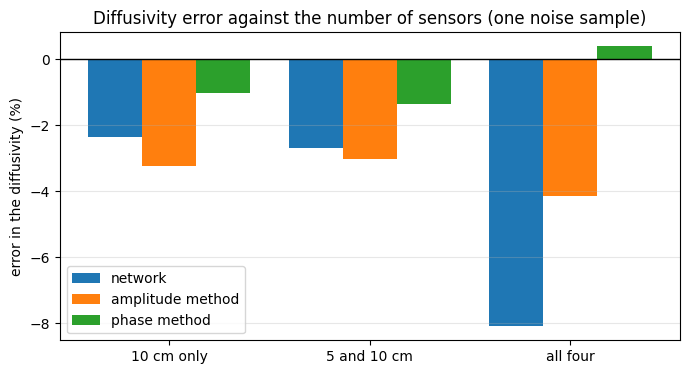

In [ ]:
def sensor_subset(depths_cm):
    keep = np.isin(np.round(100 * zt_data[:, 0]).astype(int), depths_cm)
    return (to_tensor(zt_data[keep, 0:1]), to_tensor(zt_data[keep, 1:2]), to_tensor(theta_data[keep]))

configs = [((10,), "10 cm only"), ((5, 10), "5 and 10 cm"), ((5, 10, 20, 30), "all four")]
study = []
for depths_cm, label in configs:
    model_s, _, _, alpha_hist_s, _ = train_torch((1.0, 1.0, 1.0), epochs=5000, learn_alpha=True,
                                                 data=sensor_subset(depths_cm), verbose=False)
    rows = [np.where(np.isclose(sensor_depths, c / 100.0))[0][0] for c in depths_cm]
    a_amp, a_phase = classical_alphas(theta_matrix[rows], depths=sensor_depths[rows])
    study.append((label, alpha_hist_s[-1], a_amp, a_phase, field_errors_torch(predict_grid(model_s))["whole map"]))

print(f"{'sensors':14s}{'network':>10s}{'amplitude':>11s}{'phase':>9s}{'map error (deg C)':>20s}      (true alpha = {ALPHA_TRUE:.4f})")
for label, a_net, a_amp, a_phase, err in study:
    print(f"{label:14s}{a_net:10.4f}{a_amp:11.4f}{a_phase:9.4f}{err:20.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(study))
ax.bar(positions - 0.27, [100 * (s[1] / ALPHA_TRUE - 1) for s in study], width=0.27, label="network")
ax.bar(positions, [100 * (s[2] / ALPHA_TRUE - 1) for s in study], width=0.27, label="amplitude method")
ax.bar(positions + 0.27, [100 * (s[3] / ALPHA_TRUE - 1) for s in study], width=0.27, label="phase method")
ax.axhline(0, color="k", lw=1)
ax.set_xticks(positions)
ax.set_xticklabels([s[0] for s in study])
ax.set_ylabel("error in the diffusivity (%)")
ax.set_title("Diffusivity error against the number of sensors (one noise sample)")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.show()

This is one noise sample for each setting, so it cannot show a trend by itself. A fair study would repeat each setting with many noise draws, as in Setup S8. Still, it shows that the physics network can work with very few sensors, because the surface record and the heat equation supply the rest. The map error (last column) is the more telling number: how well the whole temperature field is reproduced with so little data.

## B12. Case study 2 in PyTorch: the heat-shield tile
The same tile problem as A13: thermocouples at 1 to 4 cm, the known hot-face history, an insulated back, a known start, and an unknown diffusivity starting at half its true value. The tile loss has two more pieces than the soil loss (the zero-flux back face and the initial condition), and both are easy with autograd: the back-face condition just needs the depth derivative at $z=L$, which `grad` gives directly.

First the network is told its own scales: the `HeatPINN` class from B3 takes optional `z_scale` and `t_scale` arguments (the tile thickness and the 60-minute window).

In [ ]:
# tensors for the tile
tz_m, tt_m = to_tensor(tile_zt_data[:, 0:1]), to_tensor(tile_zt_data[:, 1:2])
tth_m = to_tensor(tile_theta_data)

t_edge_tile = to_tensor(np.linspace(0.0, TILE_TEND, 300).reshape(-1, 1))
tz_s, tt_s = torch.zeros_like(t_edge_tile), t_edge_tile
tth_s = to_tensor(reentry_pulse(t_edge_tile.numpy()))                 # known hot-face history
tz_b, tt_b = torch.full_like(t_edge_tile, TILE_L), t_edge_tile        # back face
tz_i = to_tensor(np.linspace(0.0, TILE_L, 100).reshape(-1, 1))        # the start (t = 0)
tt_i = torch.zeros_like(tz_i)

gen_t = torch.Generator().manual_seed(1)
tz_c = torch.rand(2500, 1, generator=gen_t) * TILE_L
tt_c = torch.rand(2500, 1, generator=gen_t) * TILE_TEND

tile_grid_z_t, tile_grid_t_t = to_tensor(tile_grid_zz.reshape(-1, 1)), to_tensor(tile_grid_tt.reshape(-1, 1))
TILE_RES_T = 0.1


def tile_losses_torch(model, alpha, n_use=None):
    l_data = torch.mean((model(tz_m, tt_m) - tth_m) ** 2)
    z = tz_c.clone().requires_grad_(True)
    t = tt_c.clone().requires_grad_(True)
    theta = model(z, t)
    theta_t = grad(theta, t)
    theta_zz = grad(grad(theta, z), z)
    l_pde = torch.mean(((theta_t - alpha * theta_zz) / TILE_RES_T) ** 2)
    zb = tz_b.clone().requires_grad_(True)
    flux = grad(model(zb, tt_b), zb) * TILE_L                          # zero flux at the back face
    l_bc = torch.mean((model(tz_s, tt_s) - tth_s) ** 2) + torch.mean(flux ** 2)
    l_init = torch.mean(model(tz_i, tt_i) ** 2)
    return l_data, l_pde, l_bc, l_init


def train_tile_torch(lam, epochs=8000, learn_alpha=True, alpha_start=1.2e-5, seed=0, verbose=True, print_every=1000):
    torch.manual_seed(seed)
    model = HeatPINN(hidden=(32, 32, 32), z_scale=TILE_L, t_scale=TILE_TEND)
    params = list(model.parameters())
    log_alpha = None
    if learn_alpha:
        log_alpha = nn.Parameter(torch.log(torch.tensor(float(alpha_start))))
        params.append(log_alpha)
    optimizer = torch.optim.Adam(params, lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    alpha_history = []
    for epoch in range(epochs):
        alpha = torch.exp(log_alpha) if learn_alpha else TILE_ALPHA
        optimizer.zero_grad()
        if lam[2] > 0:
            l_data, l_pde, l_bc, l_init = tile_losses_torch(model, alpha)
        else:                                                             # sensors only: skip the physics terms
            l_data = torch.mean((model(tz_m, tt_m) - tth_m) ** 2)
            l_pde = l_bc = l_init = torch.zeros(())
        total = lam[0] * l_data + lam[1] * l_bc + lam[2] * l_pde + lam[3] * l_init
        total.backward()
        optimizer.step()
        scheduler.step()
        alpha_history.append(alpha.item() if learn_alpha else TILE_ALPHA)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha_history[-1]:.3e}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.3e}  sensors = {l_data.item():.2e}  "
                  f"equation = {l_pde.item():.2e}  boundary = {l_bc.item():.2e}  initial = {l_init.item():.2e}{extra}")
    return model, log_alpha, np.array(alpha_history)


def tile_series_torch(model, depth, minutes):
    z = torch.full((len(minutes), 1), float(depth))
    t = to_tensor(np.asarray(minutes).reshape(-1, 1))
    with torch.no_grad():
        return TILE_T0 + TILE_DT * model(z, t).numpy().ravel()

In [ ]:
print("=== thermocouples only ===")
model_tile_data, _, _ = train_tile_torch((1.0, 0.0, 0.0, 0.0), learn_alpha=False, print_every=2000)

print("\n=== thermocouples + physics, diffusivity unknown ===")
model_tile_pinn, log_alpha_tile, alpha_hist_tile_t = train_tile_torch((1.0, 1.0, 1.0, 1.0))
alpha_tile_hat_t = alpha_hist_tile_t[-1]

=== thermocouples only ===
epoch   2000/8000  total = 6.624e-05  sensors = 6.62e-05  equation = 0.00e+00  boundary = 0.00e+00  initial = 0.00e+00
epoch   4000/8000  total = 3.144e-05  sensors = 3.14e-05  equation = 0.00e+00  boundary = 0.00e+00  initial = 0.00e+00
epoch   6000/8000  total = 1.630e-05  sensors = 1.63e-05  equation = 0.00e+00  boundary = 0.00e+00  initial = 0.00e+00
epoch   8000/8000  total = 1.183e-05  sensors = 1.18e-05  equation = 0.00e+00  boundary = 0.00e+00  initial = 0.00e+00

=== thermocouples + physics, diffusivity unknown ===
epoch   1000/8000  total = 6.100e-03  sensors = 1.57e-03  equation = 1.72e-03  boundary = 2.70e-03  initial = 1.07e-04  alpha = 1.010e-05
epoch   2000/8000  total = 1.447e-03  sensors = 3.15e-05  equation = 3.25e-04  boundary = 1.05e-03  initial = 3.77e-05  alpha = 2.320e-05
epoch   3000/8000  total = 7.222e-04  sensors = 1.66e-05  equation = 2.19e-04  boundary = 4.68e-04  initial = 1.80e-05  alpha = 2.404e-05
epoch   4000/8000  total = 4.

method                             alpha (m^2/min)   error  back-face peak  at minute
truth                                    2.400e-05    0.0%         147 C       43.1
thermocouples only                                                 164 C       60.0
fit with the classical solver            2.406e-05    0.2%         147 C       43.0
thermocouples + physics (PyTorch)        2.389e-05   -0.5%         143 C       38.7


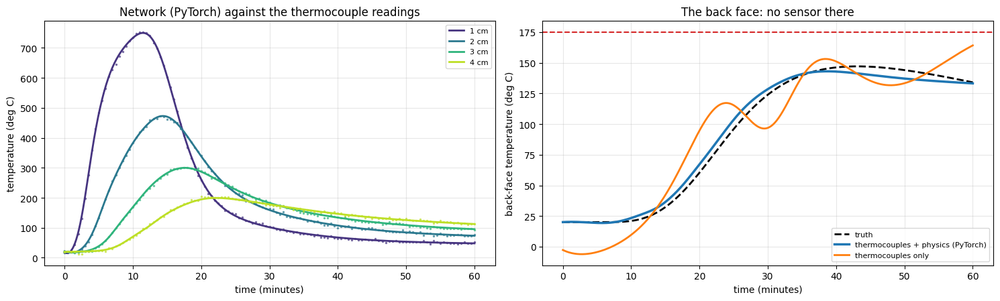

In [ ]:
back_data_t = tile_series_torch(model_tile_data, TILE_L, minutes_fine)
back_pinn_t = tile_series_torch(model_tile_pinn, TILE_L, minutes_fine)

print(f"{'method':34s}{'alpha (m^2/min)':>16s}{'error':>8s}{'back-face peak':>16s}{'at minute':>11s}")
rows_t = (("truth", TILE_ALPHA, back_true), ("thermocouples only", None, back_data_t),
          ("fit with the classical solver", alpha_tile_fit, back_fit),
          ("thermocouples + physics (PyTorch)", alpha_tile_hat_t, back_pinn_t))
for name, a, series in rows_t:
    a_txt, e_txt = ("", "") if a is None else (f"{a:.3e}", f"{100*(a/TILE_ALPHA-1):.1f}%")
    print(f"{name:34s}{a_txt:>16s}{e_txt:>8s}{series.max():12.0f} C{minutes_fine[np.argmax(series)]:11.1f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for i, (z, colour) in enumerate(zip(tile_sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    axes[0].plot(tile_sensor_times, TILE_T0 + TILE_DT * tile_theta_matrix[i], ".", color=colour, ms=3, alpha=0.6)
    axes[0].plot(minutes_fine, tile_series_torch(model_tile_pinn, z, minutes_fine), color=colour, lw=2, label=f"{int(100*z)} cm")
axes[0].set_xlabel("time (minutes)"); axes[0].set_ylabel("temperature (deg C)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_title("Network (PyTorch) against the thermocouple readings")
axes[1].plot(minutes_fine, back_true, "k--", lw=2, label="truth")
axes[1].plot(minutes_fine, back_pinn_t, color="tab:blue", lw=2.5, label="thermocouples + physics (PyTorch)")
axes[1].plot(minutes_fine, back_data_t, color="tab:orange", lw=2, label="thermocouples only")
axes[1].axhline(BOND_LIMIT, color="tab:red", ls="--")
axes[1].set_xlabel("time (minutes)"); axes[1].set_ylabel("back-face temperature (deg C)"); axes[1].legend(fontsize=8, loc="lower right")
axes[1].grid(alpha=0.3); axes[1].set_title("The back face: no sensor there")
plt.tight_layout()
plt.show()

Compare with A13. The pattern to look for is the same: the sensors-only network misjudges the back-face temperature, while the physics network finds the diffusivity and puts the peak at about the right time and size. The exact numbers will differ a little, because the starting weights differ and PyTorch works in 32-bit numbers.

**A re-entry video from the PyTorch networks.** The same `make_reentry_video` helper works with these fields too. The files get a `_pytorch` suffix.

In [ ]:
def tile_field_torch(model):
    with torch.no_grad():
        theta = model(tile_grid_z_t, tile_grid_t_t).numpy().reshape(tile_grid_zz.shape)
    return TILE_T0 + TILE_DT * theta

anim_reentry_t = make_reentry_video(tile_grid_t, tile_grid_z, tile_truth_grid, tile_field_torch(model_tile_pinn),
                                    tile_field_torch(model_tile_data),
                                    mp4_path=MEDIA_DIR / "reentry_heat_shield_pytorch.mp4",
                                    gif_path=MEDIA_DIR / "reentry_heat_shield_pytorch.gif", fps=12)

**Result(GIF)**

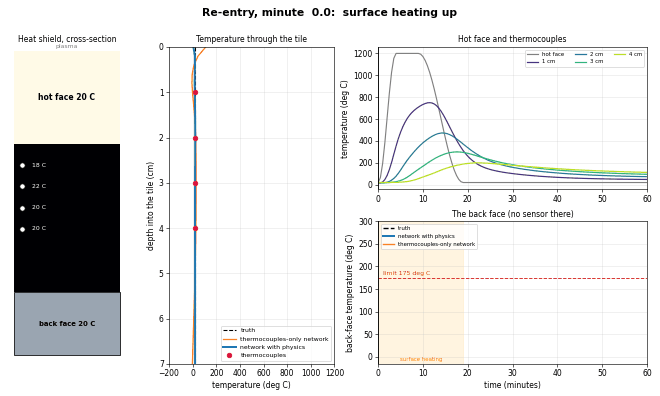

---
# Summary

| | Part A (NumPy) | Part B (PyTorch) |
|---|---|---|
| Time and depth derivatives of the network | Written by hand, layer by layer, in two directions | `torch.autograd.grad`, or `torch.func` |
| Gradient of the loss | Derived by hand, tested against finite differences (soil and tile) | `loss.backward()` |
| Unknown diffusivity | Gradient for $\log\alpha$ derived and coded by hand | `nn.Parameter` and autograd |
| Optimiser | Adam from its equations, decaying step size | `torch.optim.Adam` with `ExponentialLR`, then `LBFGS` |
| Beyond the main tests | Heat-budget checks, a cloudy-surface test, a re-entry video | A study of how many sensors are needed, the tile in PyTorch |
| Good for | Understanding every step | Faster experiments, other optimisers, larger models |

**What the soil case showed**

* The daily temperature wave in soil is a **damped, delayed wave**, $e^{-z/d}\cos(\omega t-z/d)$ with $d=\sqrt{2\alpha/\omega}$. It has the same decaying-cosine shape as the damped oscillator, spread over depth. We derived it and checked it against an independent classical solver.
* The diffusivity can be read from the **amplitude** and the **delay** of the daily swing at several depths. That is the classical method, and it works, but each estimate wanders by a few percent when sensors have realistic noise.
* A network trained on the sensor readings alone is wrong where there are no sensors. A network that also knows the heat equation and the surface temperature gets the **whole depth–time map** right, to within a few hundredths of a degree, and finds the diffusivity at the same time.
* On clean daily-cosine data the network **matches** the best classical estimate (fitting the exact formula) but does not beat it. Its advantage is that it needs no exact formula: with a messy surface record it worked with the same code.
* A conservation law, the **heat budget**, lets us test a temperature model without knowing the true answer.

**What the spacecraft case showed**

* A tile of finite thickness has an exact solution too, a **series of decaying sines** (derived by separation of variables), with a slowest time constant of about 83 minutes. That is much longer than the 19-minute heating. The tile works because it is slow.
* The structure behind the tile reaches its **peak temperature after the surface heating has ended** (heat soak). A design check has to follow the whole history. With these numbers a 7 cm tile stays under the illustrative 175 °C limit, and a 6 cm tile does not.
* From four thermocouples at 1 to 4 cm, a hot-face history that is known, and an insulated back face, the physics network finds the tile's diffusivity and reconstructs the temperature **everywhere, including the back face where nothing was measured**. The thermocouples-only network cannot: its back-face curve has the wrong shape and its peak arrives about seven minutes early. The physics network gets the timing and shape right but **under-predicts the peak by about 9 °C** in our run (138 against 147 °C), which is the unsafe direction, so a real design would still need a margin and a solver cross-check. The classical way (fitting the diffusivity by running a solver again and again) is more accurate here, with the peak within a degree, but needs a solver in a loop.
* The same energy-balance check works on the tile.

**Limits of this example**

* **Constant properties.** Real soil changes with depth and moisture, and real tile properties change strongly with temperature and pressure. A single constant diffusivity is only an "apparent" value, and the network inherits the assumption. The tile numbers here are illustrative, not data for a real vehicle.
* **Heat only moves by conduction.** Water moving in soil, and radiation inside a porous tile at high temperature, both carry heat as well.
* **The boundary conditions are idealised.** The tile model has a prescribed hot-face temperature, an insulated back (cautious), and a surface that cools to ambient in ten minutes (optimistic). The soil model holds the deep temperature constant at 0.6 m.
* **The surface temperature is known.** If it is unknown, more sensors are needed, and the problem becomes much harder (the classical inverse heat-conduction problem is sensitive to noise).
* **One noise sample** was used for the networks. The repeat tests (Setup S8 and S15) cover the classical methods only. A careful study would repeat the network runs too.
* **A classical solver is quicker** for the heat equation when everything is known. The network is worth it when data and physics must be combined, when constants are unknown, or when conditions are messy.

**Design choices that are ours, not part of the physics**

| Choice | Why |
|---|---|
| Temperatures as a scaled rise or anomaly; residual divided by a typical rate | Puts all loss terms on the scale of one, so the weights can stay near 1 |
| Network inputs scaled by the domain size (the chain rule is built into the derivative seeds) | Keeps the numbers the network sees of order one |
| Train $\log\alpha$, starting deliberately wrong (soil 0.015 m²/day, tile half the true value) | Keeps the diffusivity positive and tests recovery |
| Soil: no initial-condition term. Tile: initial condition used | The soil's starting profile is unknown; the tile starts at ambient |
| 1500 (soil) and 2500 (tile) random equation points, fixed | Enough to hold the field together over the whole rectangle |
| 8000 epochs, learning rate $3\times10^{-3}\to10^{-4}$ | A fixed rate jitters late in training |
| Soil sensors at 5, 10, 20, 30 cm, hourly, 0.2 °C noise. Tile thermocouples at 1 to 4 cm, every 30 s, 3 °C noise | Realistic set-ups |

**Things to try**

* Raise the noise (`noise_celsius` in S7, `tile_noise_c` in S14), or use fewer readings, and watch the estimates spread.
* Tile: move the thermocouples deeper or shallower, or use only two, and see how the back-face prediction changes. A deeper thermocouple should help the most.
* Tile: change the thickness in S10 and S13 and see where the design stops being safe.
* Tile: make the surface cool more slowly after the heating (for example a long exponential tail) and see how much stronger the heat soak becomes.
* Tile: give the network a wrong diffusivity in the equation and see how far the back-face prediction drifts.
* Soil: make the cycle **yearly** instead of daily. The damping depth grows by $\sqrt{365}\approx19$ times, to about 2 m, so you would need deep probes.
* Soil: use **two layers** with different diffusivities and see what the amplitude and phase methods report.

# References

1. H. S. Carslaw, J. C. Jaeger, *Conduction of Heat in Solids*, 2nd edition, Oxford University Press (1959).
2. F. P. Incropera, D. P. DeWitt, T. L. Bergman, A. S. Lavine, *Fundamentals of Heat and Mass Transfer*, 7th edition, Wiley (2011).
3. D. Hillel, *Environmental Soil Physics*, Academic Press (1998).
4. R. Horton, P. J. Wierenga, D. R. Nielsen, *Evaluation of methods for determining the apparent thermal diffusivity of soil near the surface*, Soil Science Society of America Journal, 47(1), 25–32 (1983).
5. J. C. Price, *Thermal inertia mapping: A new view of the Earth*, Journal of Geophysical Research, 82(18), 2582–2590 (1977).
6. J. Crank, P. Nicolson, *A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type*, Proceedings of the Cambridge Philosophical Society, 43(1), 50–67 (1947).
7. J. V. Beck, B. Blackwell, C. R. St. Clair Jr., *Inverse Heat Conduction: Ill-Posed Problems*, Wiley (1985).
8. O. M. Alifanov, *Inverse Heat Transfer Problems*, Springer (1994).
9. S. D. Williams, D. M. Curry, *Thermal Protection Materials: Thermophysical Property Data*, NASA Reference Publication 1289 (1992).
10. M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics, 378, 686–707 (2019).
11. S. Cuomo, V. S. Di Cola, F. Giampaolo, G. Rozza, M. Raissi, F. Piccialli, *Scientific machine learning through physics-informed neural networks: Where we are and what's next*, Journal of Scientific Computing, 92, 88 (2022).
12. D. P. Kingma, J. Ba, *Adam: A method for stochastic optimization*, ICLR (2015).
13. X. Glorot, Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks*, AISTATS, 249–256 (2010).
14. D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Mathematical Programming, 45, 503–528 (1989).
15. A. G. Baydin, B. A. Pearlmutter, A. A. Radul, J. M. Siskind, *Automatic differentiation in machine learning: a survey*, Journal of Machine Learning Research, 18(153), 1–43 (2018).
16. S. Wang, S. Sankaran, P. Perdikaris, *Respecting causality is all you need for training physics-informed neural networks*, arXiv:2203.07404 (2022).
17. A. Krishnapriyan, A. Gholami, S. Zhe, R. Kirby, M. W. Mahoney, *Characterizing possible failure modes in physics-informed neural networks*, Advances in Neural Information Processing Systems 34 (2021).